In [58]:
%load_ext autoreload
%autoreload 2

import jax.numpy as jnp

from mGST.low_level_jit import process_fidelity
from mGST.utility_functions_comparisons import get_target_operators_gate_set_name, get_compressed_rep_from_mgst_output, kraus_tensor_to_mgst

from mGST.simulate import apply_noisy_kraus_tensors_to_target_gate_set, get_random_noisy_kraus_tensors_for_gate_set, run_optimization_workflow_multi_init_realizations

from mGST.gauge_analysis import max_num_parameters, min_num_parameters

from mGST.analysis import get_all_realizations_for_key, compute_mve_and_wve_for_all_realizations, combine_error_results, compute_avg_and_std_along_keys

from mGST.visualization import plot_cost_function, plot_many_mean_std_vs_x

from mGST.typing import TrustRegionOptions, OperatorSchedule

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Parameters

In [ ]:
num_shots = 1000
seq_len_list = [1, 8, 14]
num_qubits = 2
dim = 2 ** num_qubits
state_rank = dim # max
povm_rank = dim # max
kraus_rank = 4 # start with a small rank
num_gates = 6
num_povm = dim
gate_set_name = "2QXYICZ"
noise_strength = 5e-2

title_init = rf"{num_qubits}Q | $r_\mathrm{{Kraus}}$: {kraus_rank} | $r_\mathrm{{POVM}}$: {povm_rank} | $r_\mathrm{{State}}$: {state_rank} | Random Noisy Gate Set | Shots: {num_shots}"

num_realizations = 5
num_max_random_inits = 10
num_max_iterations_random_inits = 20
threshold_multiplier = 3.0 # for the random inits optimization
batch_size = 30 * dim # from mGST estimates see `compressive_gst`

mve_seq_length = 10
num_circuits_sampled = int(1e3)
num_random_runs = 10
title_mve = title_init + f" \n Random inits: {num_max_random_inits} | Realizations: {num_realizations}"

In [3]:
min_expected, max_expected = min_num_parameters(num_qubits=num_qubits, num_gates=num_gates, state_rank=state_rank, povm_rank=povm_rank, kraus_rank=kraus_rank), max_num_parameters(num_qubits=num_qubits, num_gates=num_gates, state_rank=state_rank, povm_rank=povm_rank, kraus_rank=kraus_rank)
print(f"Min expected parameters: {min_expected}, Max expected parameters: {max_expected}")

Min expected parameters: 623, Max expected parameters: 815


In [57]:
# number of parameters of a fully noiseless model (unitary gates, pure states, and projective measurements)
min_num_parameters(num_qubits=num_qubits, num_gates=num_gates, state_rank=1, povm_rank=1, kraus_rank=1)

92

In [56]:
93 + 174 # what is this number even?

267

# Target tensors

In [4]:
target_operators, gate_labels = get_target_operators_gate_set_name(gate_set_name=gate_set_name)

random_kraus_tensors = get_random_noisy_kraus_tensors_for_gate_set(
    num_gates=num_gates,
    dim=dim,
    rank_kraus=kraus_rank,
    noise_strength=noise_strength,
    seed=42
)

noisy_gate_set_superop = apply_noisy_kraus_tensors_to_target_gate_set(
    kraus_tensors_noisy=random_kraus_tensors,
    target_gate_set=target_operators,
    is_target_vectorized=True,
)

INFO:2026-10-28 16:43:34,018:jax._src.xla_bridge:927: Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
2026-10-28 16:43:34,018 - jax._src.xla_bridge - INFO - Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:2026-10-28 16:43:34,021:jax._src.xla_bridge:927: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/

In [5]:
kraus_tensor_noisy, povm_psd_noisy, state_psd_noisy = get_compressed_rep_from_mgst_output(
    *noisy_gate_set_superop.values(),
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank)

kraus_target_superop = kraus_tensor_to_mgst(target_operators["kraus"])

target_gate_set_superops = {
    "kraus": kraus_target_superop,
    "povm": target_operators["povm"],
    "state": target_operators["state"],
}

# Gathering them all in one place
noisy_gate_set_psd = {
    "kraus": kraus_tensor_noisy,
    "povm": povm_psd_noisy,
    "state": state_psd_noisy,
}

In [62]:
fidelities_kraus = process_fidelity(kraus_tensor_noisy, target_operators["kraus"], unitary=True, sum_over=False)
print("Infidelities Kraus:", 1 - fidelities_kraus)
print("Average:", jnp.mean(1 - fidelities_kraus))

Infidelities Kraus: [0.00087109 0.00087109 0.00087109 0.00087109 0.00087109 0.00087109]
Average: 0.0008710866127797552


# Optimization

In [6]:
num_iterations_outer = 20
num_iterations_tr = 5
num_iterations_cg = 10 
tol_grad = 1e-8 # it was 1e-4 before. 1e-8 is suggested in the book.
relative_precision = 1e-3 # changed due to the changes in convergence criteria
global_gradient_norm_tol = 1e-10

tr_options_distance = TrustRegionOptions(num_iterations=num_iterations_tr, verbose=False, verbose_cg=False, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, radius_heuristic="typical_distance")

schedule_distance = OperatorSchedule.default(num_iterations_outer, tr_options_distance)

optimization_schedule = {op: schedule_distance for op in ["povm", "kraus", "state"]}

optimization_options_silence = {
    "schedule": optimization_schedule,
    "num_iterations_outer": num_iterations_outer,
    "relative_precision": relative_precision,
    "global_gradient_norm_tol": global_gradient_norm_tol,
    "noise_threshold": None,
    "compute_least_squares": 1,
    "optimization_verbose": False,
    "absolute_tolerance": 1, # for a global convergence criteria
}
optimization_options_silence

{'schedule': {'povm': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=False, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, verbose_cg=False, linearize=False, radius_heuristic='typical_distance'))]),
  'kraus': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=False, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, verbose_cg=False, linearize=False, radius_heuristic='typical_distance'))]),
  'state': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=False, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, ver

## First, lets do one that we know works

In [7]:
from mGST.simulate import generate_sequence_indices, compute_probability_matrices, run_optimization_workflow
from mGST.utility_functions_comparisons import get_initial_gate_set_for_optimization
from mGST.trust_region import are_all_tensors_in_gate_set_isometries, estimate_noise_floor_threshold
from mGST.analysis import compute_mve_and_wve_from_optimization_results

In [8]:
num_seq_good = int(1e3)
seq_len_list = [1, 8, 14]
seed = 42

indices_dict_r = generate_sequence_indices(
    num_gates=num_gates,
    num_circuits=num_seq_good,
    seq_len_list=seq_len_list,
)
probability_matrices_r = compute_probability_matrices(
    *noisy_gate_set_psd.values(),
    gate_indices=indices_dict_r["gate_indices"],
    num_shots=num_shots,
    seed=seed,
)

In [9]:
# compute the noise threshold so I know what to expect in the rest of the experiments
noise_threshold = estimate_noise_floor_threshold(multiplier=threshold_multiplier, num_shots=num_shots, probability_matrix=probability_matrices_r["sampled"])
noise_threshold

Array(0.00041605, dtype=float64)

In [10]:
# initialized at a perturbed point of the target gate set
spam_depolarization = 1e-2

init_gate_set_psd = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank,
    spam_depolarization=spam_depolarization,
    project_kraus_to_isometry=True, # because it is max rank, even false would return an isometry
)
print("All isometries (interior SPAM init):", are_all_tensors_in_gate_set_isometries(init_gate_set_psd))

All isometries (interior SPAM init): True


In [11]:
final_result_test = run_optimization_workflow(
            num_shots=num_shots,
            init_operators=init_gate_set_psd,
            operators_psd_true=noisy_gate_set_psd,
            target_superops=target_gate_set_superops,
            use_exact_probabilities=False, # test first with finite shots
            optimization_options=optimization_options_silence,
            warmup_run=False,
            use_log_likelihood=True,
            indices_dict=indices_dict_r, 
            probability_matrices=probability_matrices_r,
            verbose=True,
            gauge_optimize=True, # why not?
        )

Using log-likelihood for the cost function optimization 🧮


/Users/emiliano.godinez/Documents/phd/iqm-benchmarks/src/mGST/simulate.py:749: UserWarning: When both `indices_dict` and `probability_matrices` are provided, make sure these are compatible.
  warnings.warn("When both `indices_dict` and `probability_matrices` are provided, make sure these are compatible.")


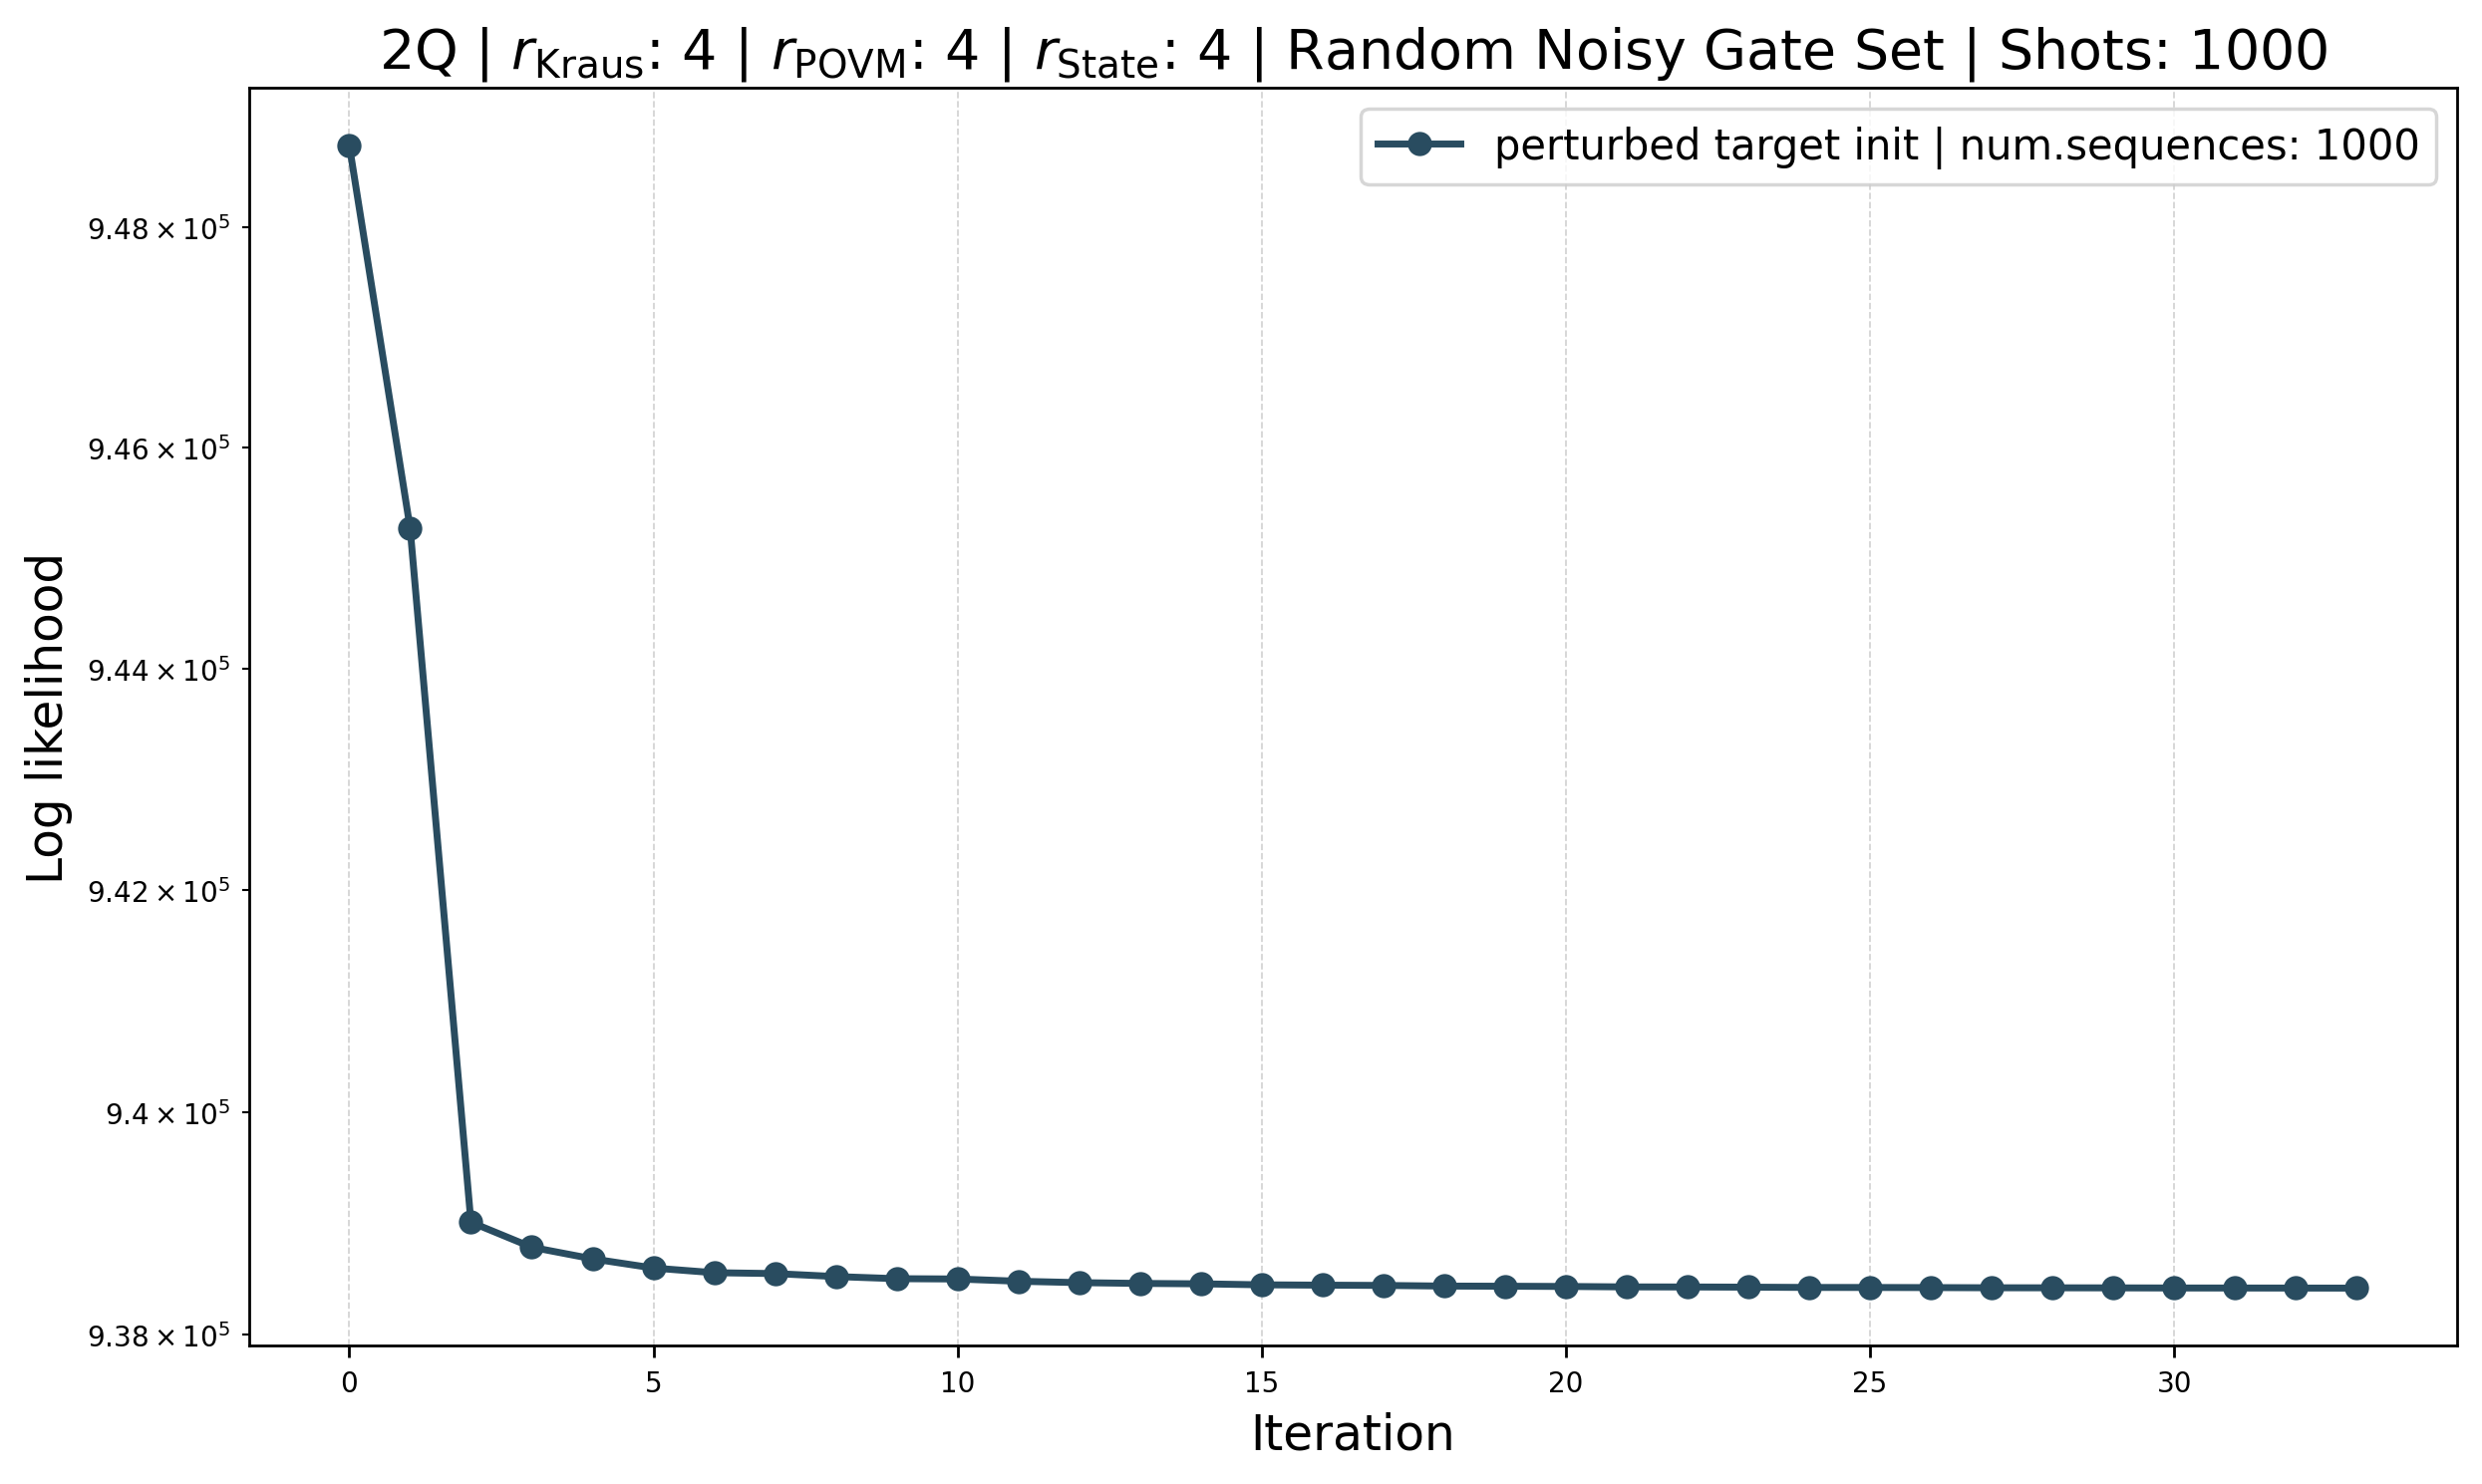

In [12]:
labels = [f"perturbed target init | num.sequences: {num_seq_good}"]
plot_cost_function([final_result_test["cost_fn_history"]["main"]], title=title_init, labels=labels, ylabel="Log likelihood")

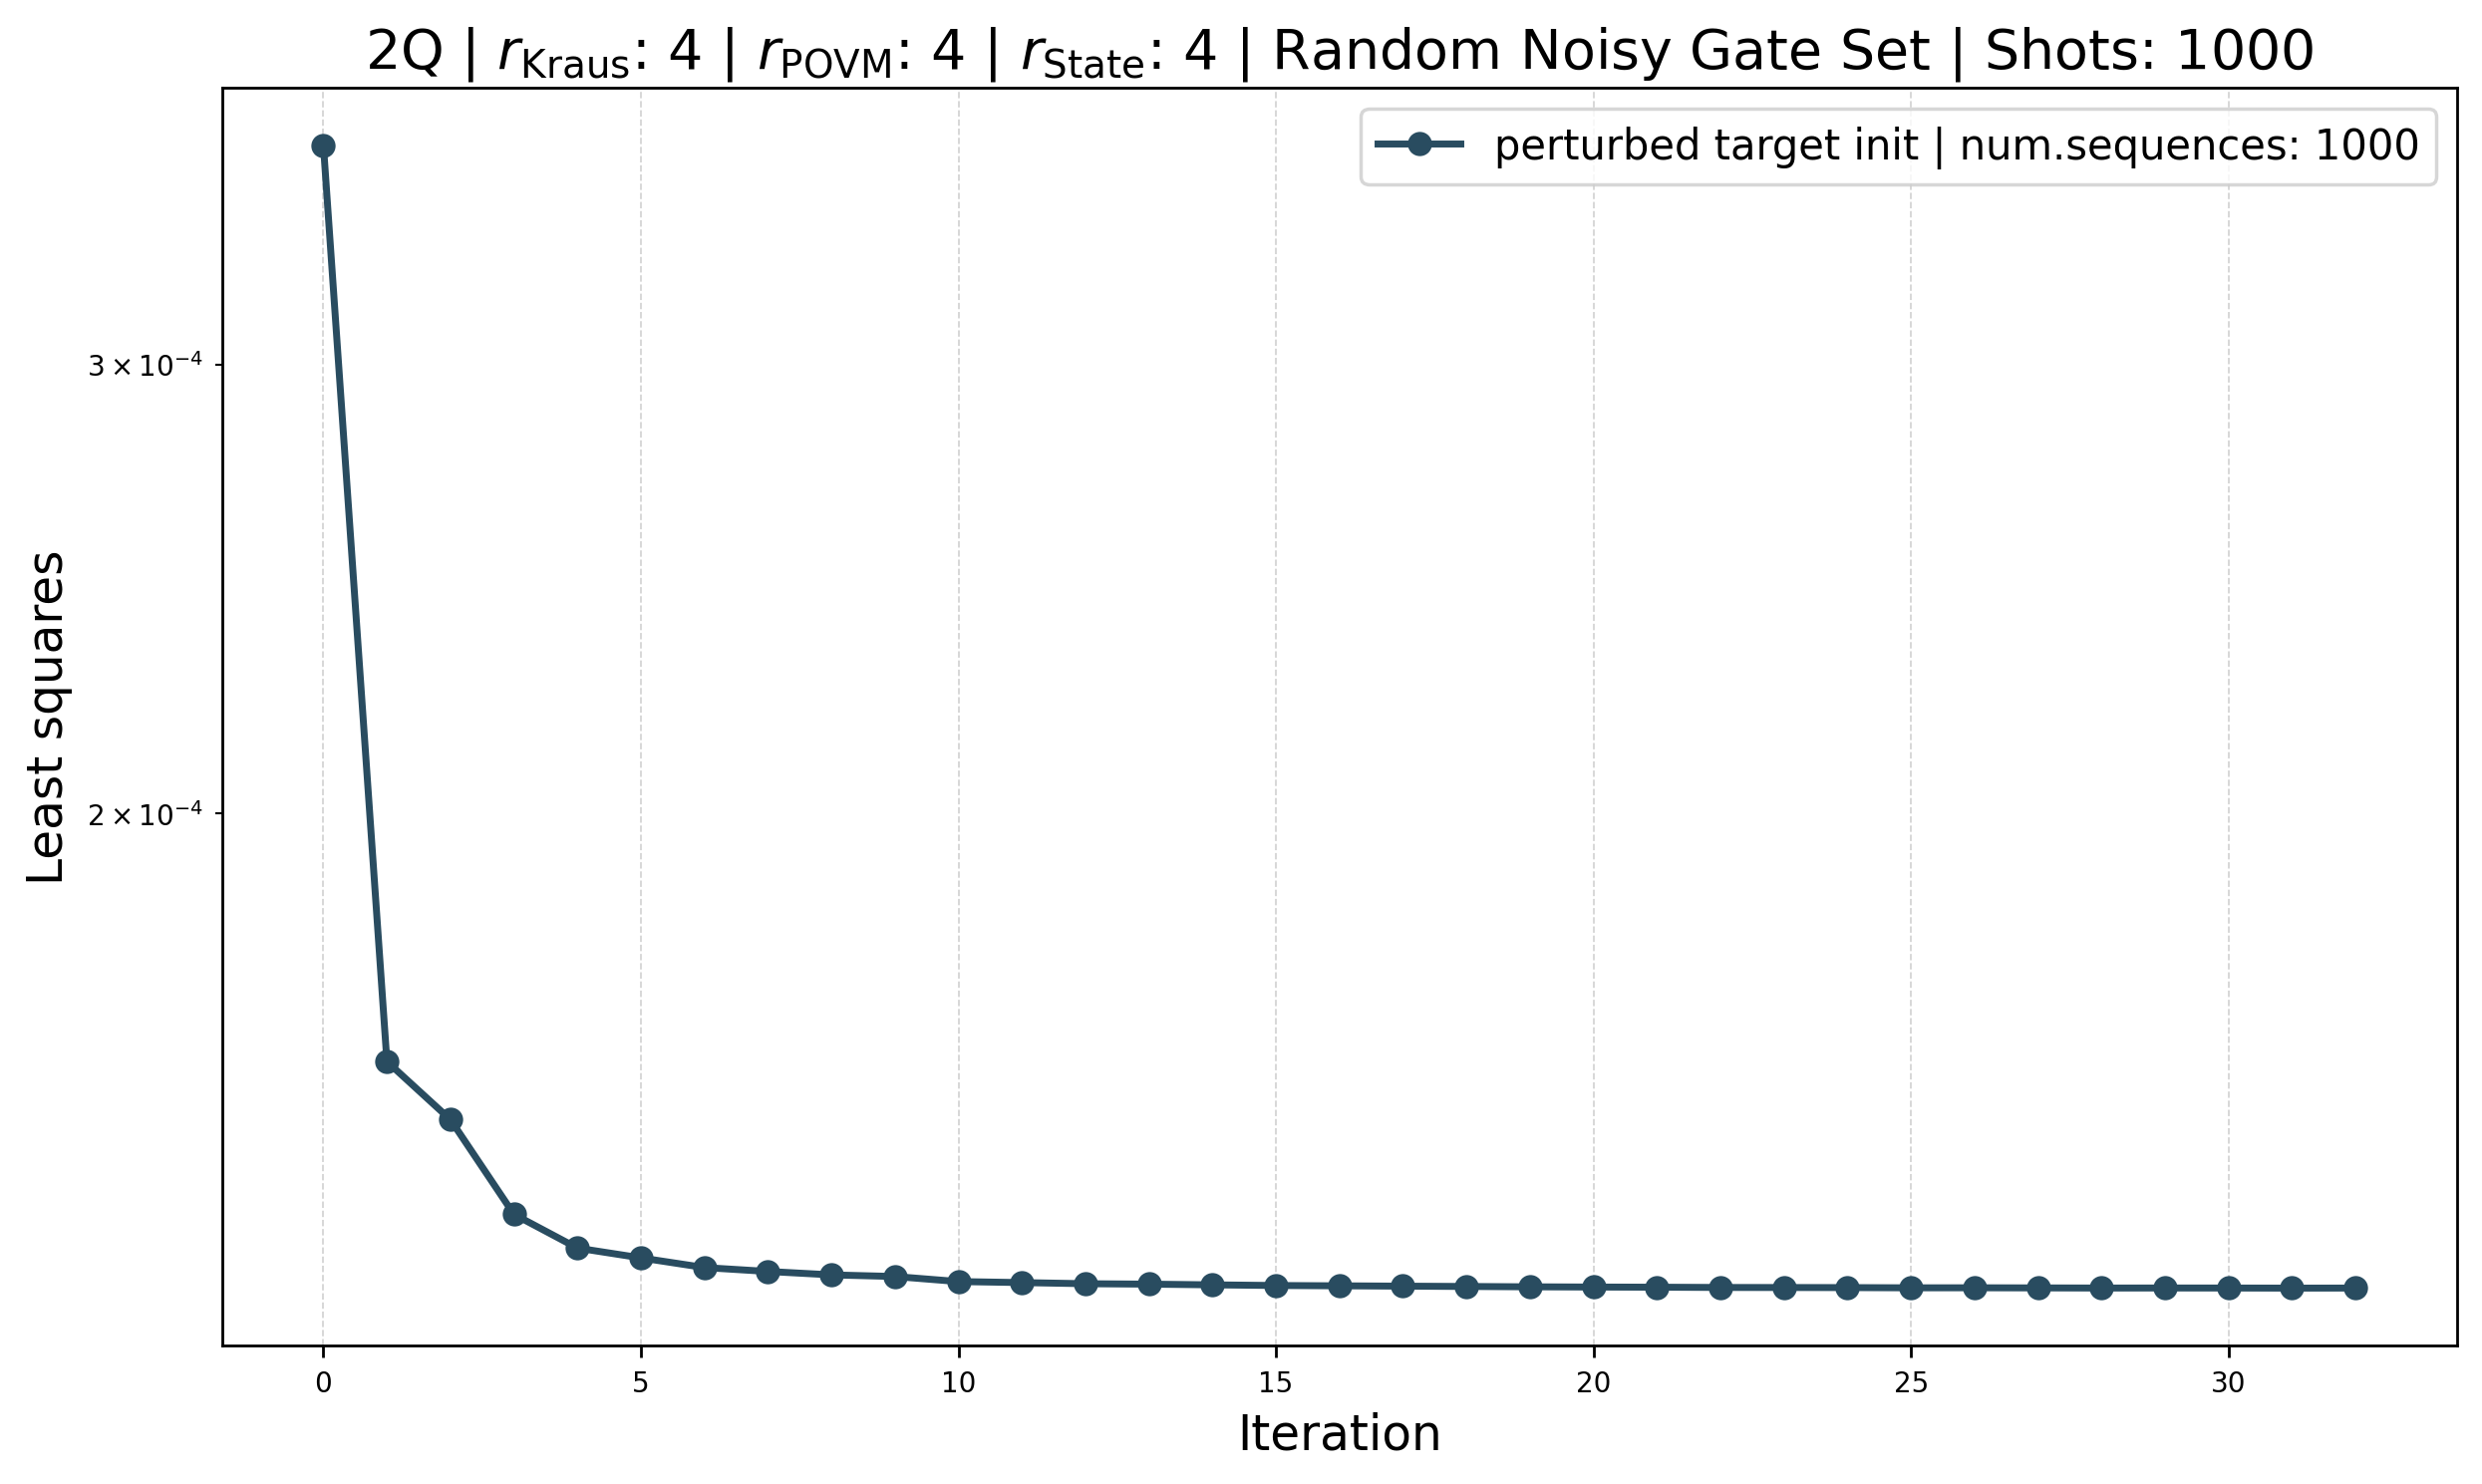

In [13]:
plot_cost_function([final_result_test["cost_fn_history"]["least_squares"]], title=title_init, labels=labels, ylabel="Least squares")

In [14]:
mve_results_test, wve_results_test = compute_mve_and_wve_from_optimization_results(
            optimization_results_dict={num_seq_good: final_result_test},
            true_superops=noisy_gate_set_superop,
            sequence_length=mve_seq_length,
            num_circuits_sampled=num_circuits_sampled,
            num_repetitions=num_random_runs,
            verbose=False,
            which_data="optimized_operators",
        )
mve_results_test

{'1000': {'mean': Array(0.00396809, dtype=float64),
  'std': Array(8.51444148e-05, dtype=float64)}}

In [15]:
from mGST.analysis import compute_average_and_std_shot_noise_variational_error

mve_shot_noise = compute_average_and_std_shot_noise_variational_error(
    true_superops=noisy_gate_set_superop,
    num_shots=num_shots,
    length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    error_type="MVE",
)
mve_shot_noise

(Array(0.01689603, dtype=float64), Array(0.00017872, dtype=float64))

In [16]:
1/jnp.sqrt(num_shots)

Array(0.03162278, dtype=float64, weak_type=True)

# Optimization over many realizations

In [17]:
from mGST.simulate import generate_random_initial_operators
from mGST.trust_region import are_all_tensors_in_gate_set_isometries

# okay so this is not a problem
# it seems that the random (kraus) tensors are already drawn with that specific rank
# so compressing them back to that rank does not change their isometry property!
random_initial_operators_test = generate_random_initial_operators(
    num_gates=num_gates,
    dim=dim,
    kraus_rank=kraus_rank,
    povm_rank=povm_rank,
    state_rank=state_rank
)
are_all_tensors_in_gate_set_isometries(random_initial_operators_test)

True

In [41]:
final_results_100_150, partial_results_100_150 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[100, 150],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=100
🔊 Estimated noise threshold: 3.812905e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 4.040106e-02.
🏁 Iteration 2/20. f(x) on full data: 2.546339e-02.
🏁 Iteration 3/20. f(x) on full data: 1.655938e-02.
🏁 Iteration 4/20. f(x) on full data: 1.300558e-02.
🏁 Iteration 5/20. f(x) on full data: 1.107957e-02.
🏁 Iteration 6/20. f(x) on full data: 1.016369e-02.
🏁 Iteration 7/20. f(x) on full data: 1.014143e-02.
🏁 Iteration 8/20. f(x) on full data: 1.013370e-02.
🏁 Iteration 9/20. f(x) on full data: 1.012754e-02.
🏁 Iteration 10/20. f(x) on full data: 1.012358e-02.
🏁 Iteration 11/20. f(x) on full data: 1.012137e-02.
🏁 Iteration 12/20. f(x) on full data: 1.012023e-02.
🏁 Iteration 13/20. f(x) on full data: 1.011966e-02.
🏁 Iteration 14/20. f(x) on full data: 1.011939e-02.
🏁 Iteration 15/20. f(x) on full data: 1.011926e-02.
🏁 Iteration 16/20. f(x) on full data: 1.011921e-02.
🏁 Iteration 17/20. f(x) o

In [49]:
final_results_200_250, partial_results_200_250 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[200, 250],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=200
🔊 Estimated noise threshold: 4.066345e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 3.853390e-02.
🏁 Iteration 2/20. f(x) on full data: 2.971883e-02.
🏁 Iteration 3/20. f(x) on full data: 2.546334e-02.
🏁 Iteration 4/20. f(x) on full data: 2.526580e-02.
🏁 Iteration 5/20. f(x) on full data: 2.308746e-02.
🏁 Iteration 6/20. f(x) on full data: 2.198185e-02.
🏁 Iteration 7/20. f(x) on full data: 2.182427e-02.
🏁 Iteration 8/20. f(x) on full data: 2.226990e-02.
🏁 Iteration 9/20. f(x) on full data: 2.106348e-02.
🏁 Iteration 10/20. f(x) on full data: 1.962342e-02.
🏁 Iteration 11/20. f(x) on full data: 2.104643e-02.
🏁 Iteration 12/20. f(x) on full data: 1.948946e-02.
🏁 Iteration 13/20. f(x) on full data: 1.944461e-02.
🏁 Iteration 14/20. f(x) on full data: 1.853544e-02.
🏁 Iteration 15/20. f(x) on full data: 1.816288e-02.
🏁 Iteration 16/20. f(x) on full data: 1.778831e-02.
🏁 Iteration 17/20. f(x) o

In [48]:
final_results_200_250, partial_results_200_250 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[200, 250],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=200
🔊 Estimated noise threshold: 4.122050e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 3.880136e-02.
🏁 Iteration 2/20. f(x) on full data: 2.978130e-02.
🏁 Iteration 3/20. f(x) on full data: 2.454403e-02.
🏁 Iteration 4/20. f(x) on full data: 2.179863e-02.
🏁 Iteration 5/20. f(x) on full data: 2.047481e-02.
🏁 Iteration 6/20. f(x) on full data: 1.840666e-02.
🏁 Iteration 7/20. f(x) on full data: 1.807998e-02.
🏁 Iteration 8/20. f(x) on full data: 1.773711e-02.
🏁 Iteration 9/20. f(x) on full data: 1.660105e-02.
🏁 Iteration 10/20. f(x) on full data: 1.744231e-02.
🏁 Iteration 11/20. f(x) on full data: 1.682910e-02.
🏁 Iteration 12/20. f(x) on full data: 1.656143e-02.
🏁 Iteration 13/20. f(x) on full data: 1.440845e-02.
🏁 Iteration 14/20. f(x) on full data: 5.090457e-03.
🏁 Iteration 15/20. f(x) on full data: 3.046939e-04.
✅ Converged below noise threshold after 1 random initializations. 
 Rnd. Init

In [35]:
final_results_300_350, partial_results_300_350 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[300, 350],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=300
🔊 Estimated noise threshold: 4.206888e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 3.914652e-02.
🏁 Iteration 2/20. f(x) on full data: 2.912785e-02.
🏁 Iteration 3/20. f(x) on full data: 2.583432e-02.
🏁 Iteration 4/20. f(x) on full data: 2.517030e-02.
🏁 Iteration 5/20. f(x) on full data: 2.376416e-02.
🏁 Iteration 6/20. f(x) on full data: 2.321788e-02.
🏁 Iteration 7/20. f(x) on full data: 2.369091e-02.
🏁 Iteration 8/20. f(x) on full data: 2.232647e-02.
🏁 Iteration 9/20. f(x) on full data: 2.437864e-02.
🏁 Iteration 10/20. f(x) on full data: 2.429625e-02.
🏁 Iteration 11/20. f(x) on full data: 2.398527e-02.
🏁 Iteration 12/20. f(x) on full data: 2.347992e-02.
🏁 Iteration 13/20. f(x) on full data: 2.549869e-02.
🏁 Iteration 14/20. f(x) on full data: 2.444913e-02.
🏁 Iteration 15/20. f(x) on full data: 2.505918e-02.
🏁 Iteration 16/20. f(x) on full data: 2.442922e-02.
🏁 Iteration 17/20. f(x) o

In [32]:
final_results_400_450, partial_results_400_450 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[400, 450],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=400
🔊 Estimated noise threshold: 4.171499e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 4.024626e-02.
🏁 Iteration 2/20. f(x) on full data: 3.391220e-02.
🏁 Iteration 3/20. f(x) on full data: 3.330789e-02.
🏁 Iteration 4/20. f(x) on full data: 2.985506e-02.
🏁 Iteration 5/20. f(x) on full data: 2.809991e-02.
🏁 Iteration 6/20. f(x) on full data: 2.797252e-02.
🏁 Iteration 7/20. f(x) on full data: 2.701936e-02.
🏁 Iteration 8/20. f(x) on full data: 2.594234e-02.
🏁 Iteration 9/20. f(x) on full data: 2.509651e-02.
🏁 Iteration 10/20. f(x) on full data: 2.406233e-02.
🏁 Iteration 11/20. f(x) on full data: 2.318944e-02.
🏁 Iteration 12/20. f(x) on full data: 2.650217e-02.
🏁 Iteration 13/20. f(x) on full data: 2.320223e-02.
🏁 Iteration 14/20. f(x) on full data: 2.266532e-02.
🏁 Iteration 15/20. f(x) on full data: 1.899342e-02.
🏁 Iteration 16/20. f(x) on full data: 1.161997e-02.
🏁 Iteration 17/20. f(x) o

In [29]:
final_results_500_550, partial_results_500_550 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[500, 550],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=500
🔊 Estimated noise threshold: 4.170270e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 4.441729e-02.
🏁 Iteration 2/20. f(x) on full data: 3.919119e-02.
🏁 Iteration 3/20. f(x) on full data: 3.535875e-02.
🏁 Iteration 4/20. f(x) on full data: 3.301341e-02.
🏁 Iteration 5/20. f(x) on full data: 3.377880e-02.
🏁 Iteration 6/20. f(x) on full data: 3.235923e-02.
🏁 Iteration 7/20. f(x) on full data: 3.270131e-02.
🏁 Iteration 8/20. f(x) on full data: 3.451893e-02.
🏁 Iteration 9/20. f(x) on full data: 3.091246e-02.
🏁 Iteration 10/20. f(x) on full data: 3.018988e-02.
🏁 Iteration 11/20. f(x) on full data: 2.959647e-02.
🏁 Iteration 12/20. f(x) on full data: 2.895221e-02.
🏁 Iteration 13/20. f(x) on full data: 2.780968e-02.
🏁 Iteration 14/20. f(x) on full data: 2.279469e-02.
🏁 Iteration 15/20. f(x) on full data: 1.088323e-02.
🏁 Iteration 16/20. f(x) on full data: 4.211202e-03.
🏁 Iteration 17/20. f(x) o

In [21]:
final_results_600_650, partial_results_600_650 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[600, 650],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=600
🔊 Estimated noise threshold: 4.216914e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 4.189512e-02.
🏁 Iteration 2/20. f(x) on full data: 3.979712e-02.
🏁 Iteration 3/20. f(x) on full data: 3.757760e-02.
🏁 Iteration 4/20. f(x) on full data: 3.471524e-02.
🏁 Iteration 5/20. f(x) on full data: 3.400974e-02.
🏁 Iteration 6/20. f(x) on full data: 3.554876e-02.
🏁 Iteration 7/20. f(x) on full data: 3.290545e-02.
🏁 Iteration 8/20. f(x) on full data: 3.250266e-02.
🏁 Iteration 9/20. f(x) on full data: 3.006347e-02.
🏁 Iteration 10/20. f(x) on full data: 2.901974e-02.
🏁 Iteration 11/20. f(x) on full data: 2.973807e-02.
🏁 Iteration 12/20. f(x) on full data: 2.930785e-02.
🏁 Iteration 13/20. f(x) on full data: 2.704242e-02.
🏁 Iteration 14/20. f(x) on full data: 2.773561e-02.
🏁 Iteration 15/20. f(x) on full data: 2.900317e-02.
🏁 Iteration 16/20. f(x) on full data: 2.899540e-02.
🏁 Iteration 17/20. f(x) o

In [18]:
final_results_700, partial_results_700 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[700],
    num_realizations=num_realizations, # go back to 5 realizations
    num_max_iterations_random_inits=num_max_iterations_random_inits, # go back to 20
    num_max_random_inits=num_max_random_inits, # 10
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=700
🔊 Estimated noise threshold: 4.180663e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 4.730126e-02.
🏁 Iteration 2/20. f(x) on full data: 4.222251e-02.
🏁 Iteration 3/20. f(x) on full data: 3.845296e-02.
🏁 Iteration 4/20. f(x) on full data: 3.924771e-02.
🏁 Iteration 5/20. f(x) on full data: 3.424679e-02.
🏁 Iteration 6/20. f(x) on full data: 3.543908e-02.
🏁 Iteration 7/20. f(x) on full data: 3.171565e-02.
🏁 Iteration 8/20. f(x) on full data: 3.399381e-02.
🏁 Iteration 9/20. f(x) on full data: 3.307236e-02.
🏁 Iteration 10/20. f(x) on full data: 3.227911e-02.
🏁 Iteration 11/20. f(x) on full data: 3.254080e-02.
🏁 Iteration 12/20. f(x) on full data: 3.215901e-02.
🏁 Iteration 13/20. f(x) on full data: 3.021940e-02.
🏁 Iteration 14/20. f(x) on full data: 3.169171e-02.
🏁 Iteration 15/20. f(x) on full data: 3.512909e-02.
🏁 Iteration 16/20. f(x) on full data: 3.472389e-02.
🏁 Iteration 17/20. f(x) o

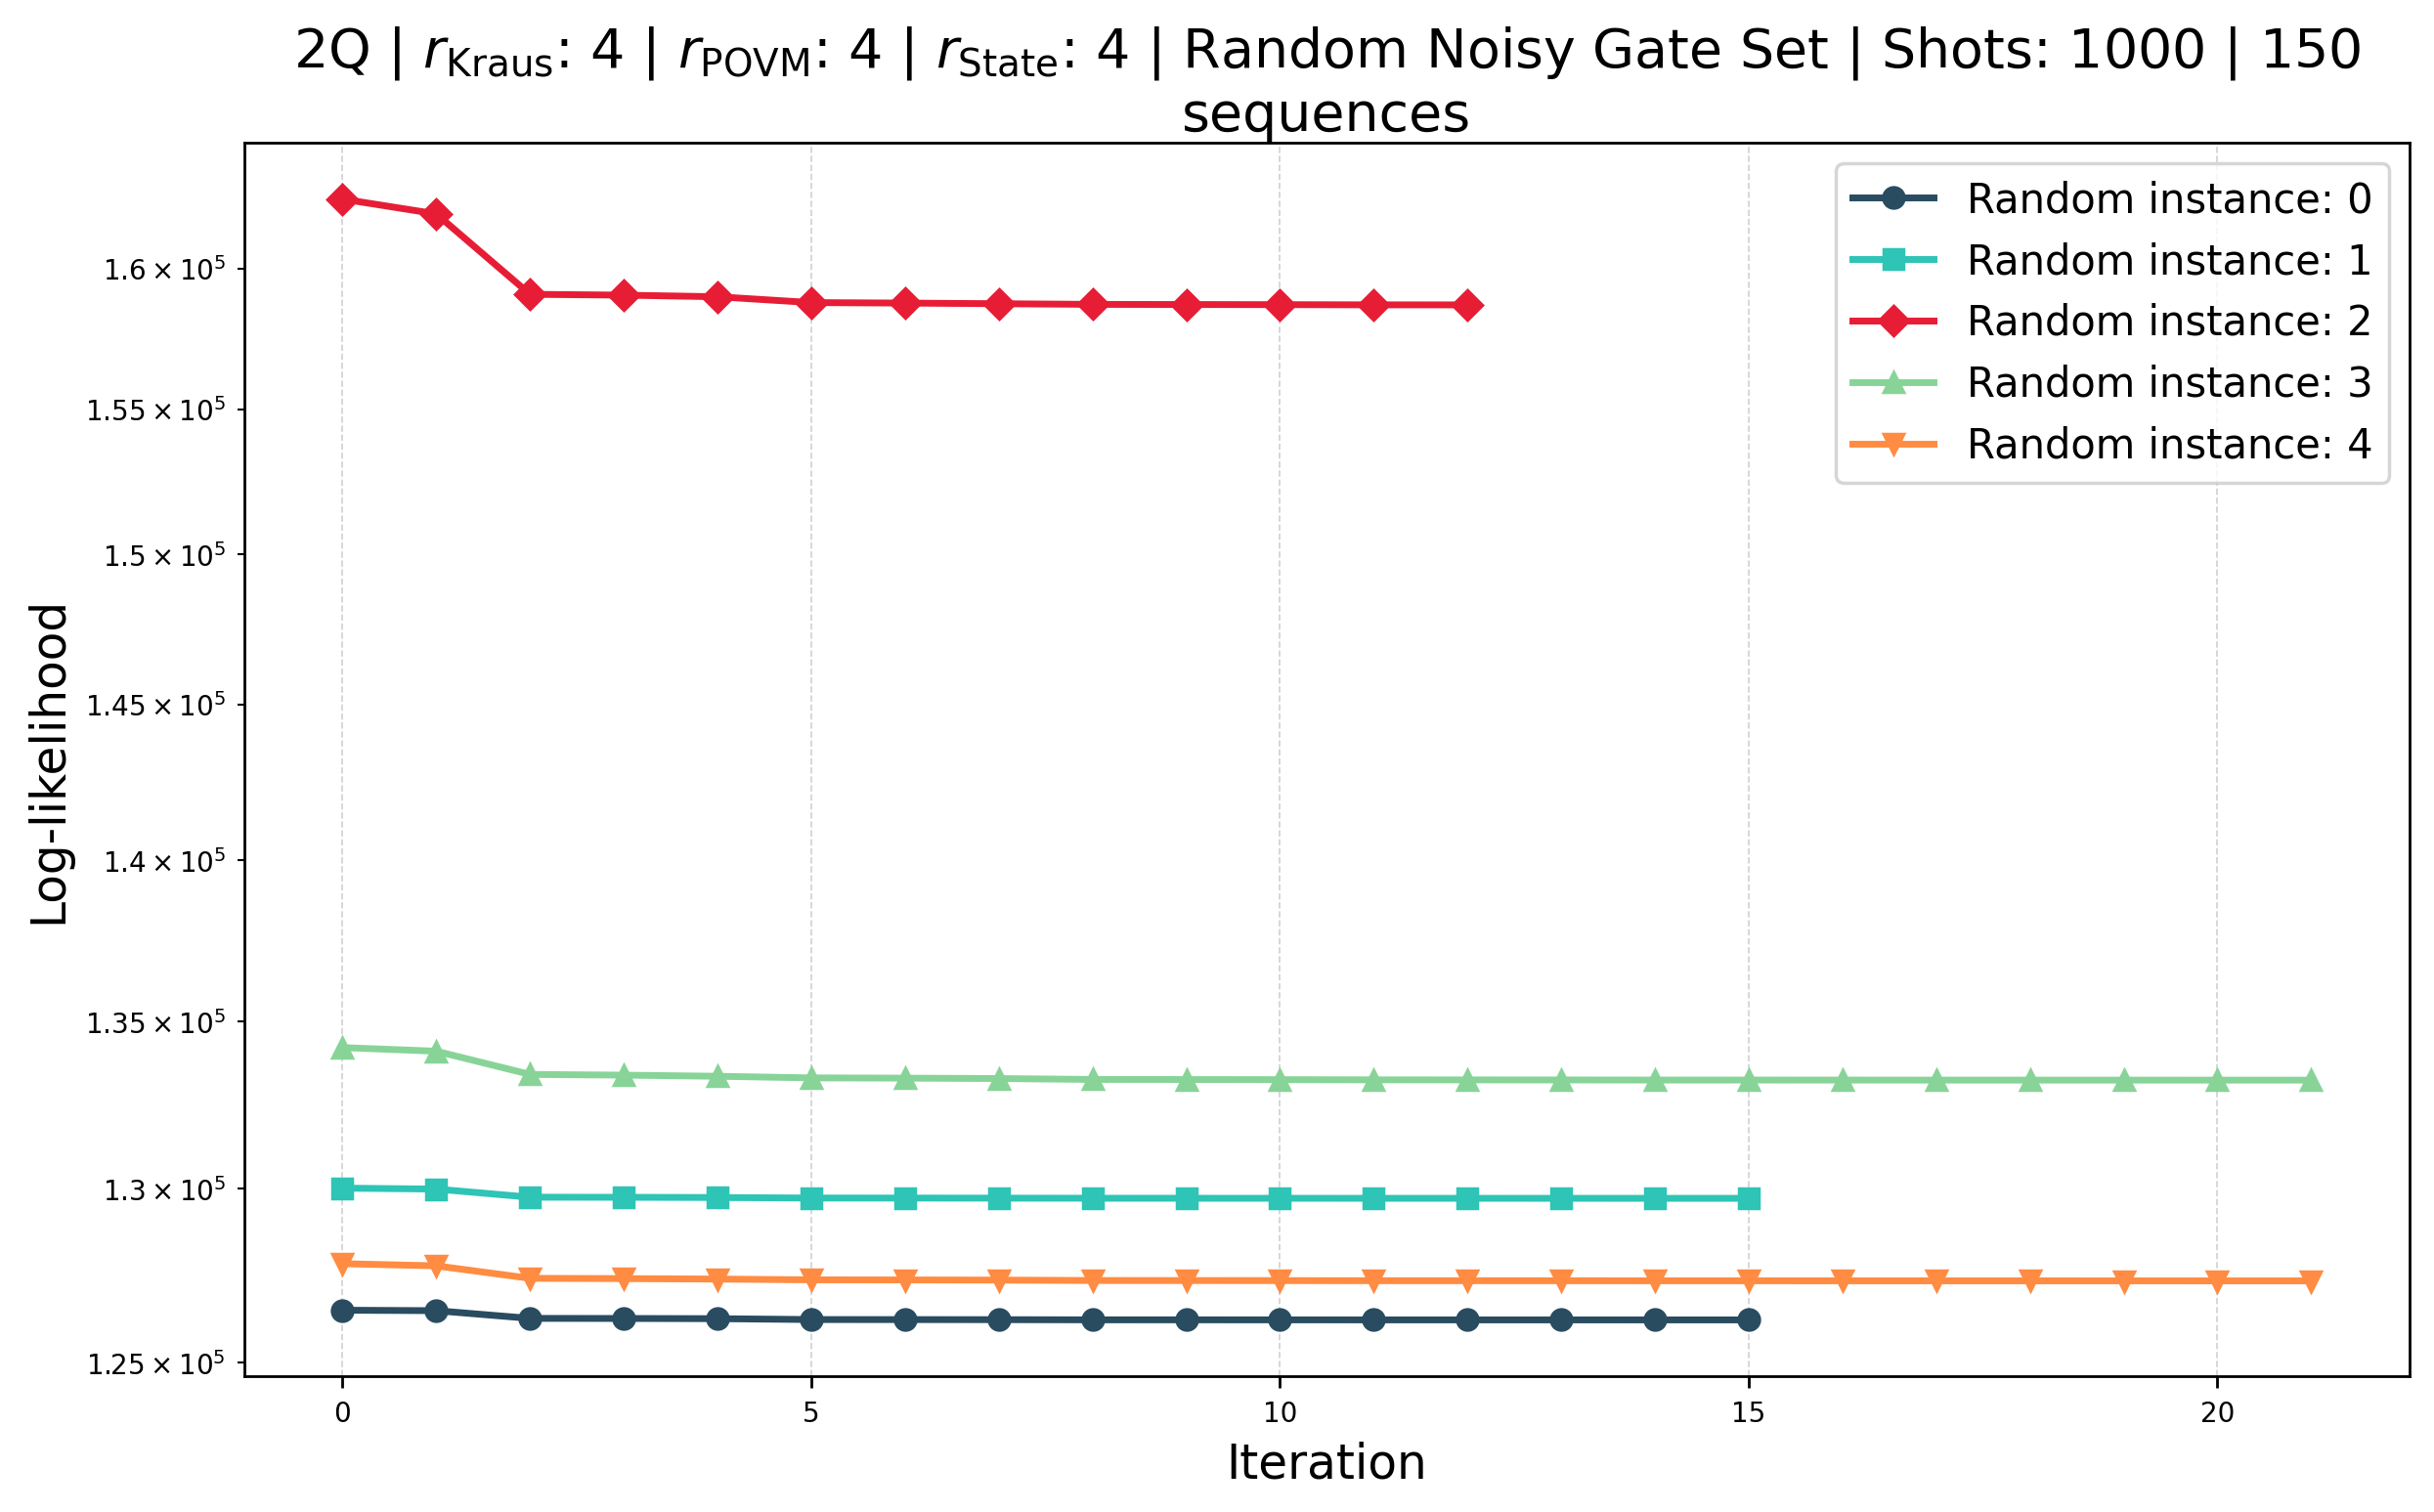

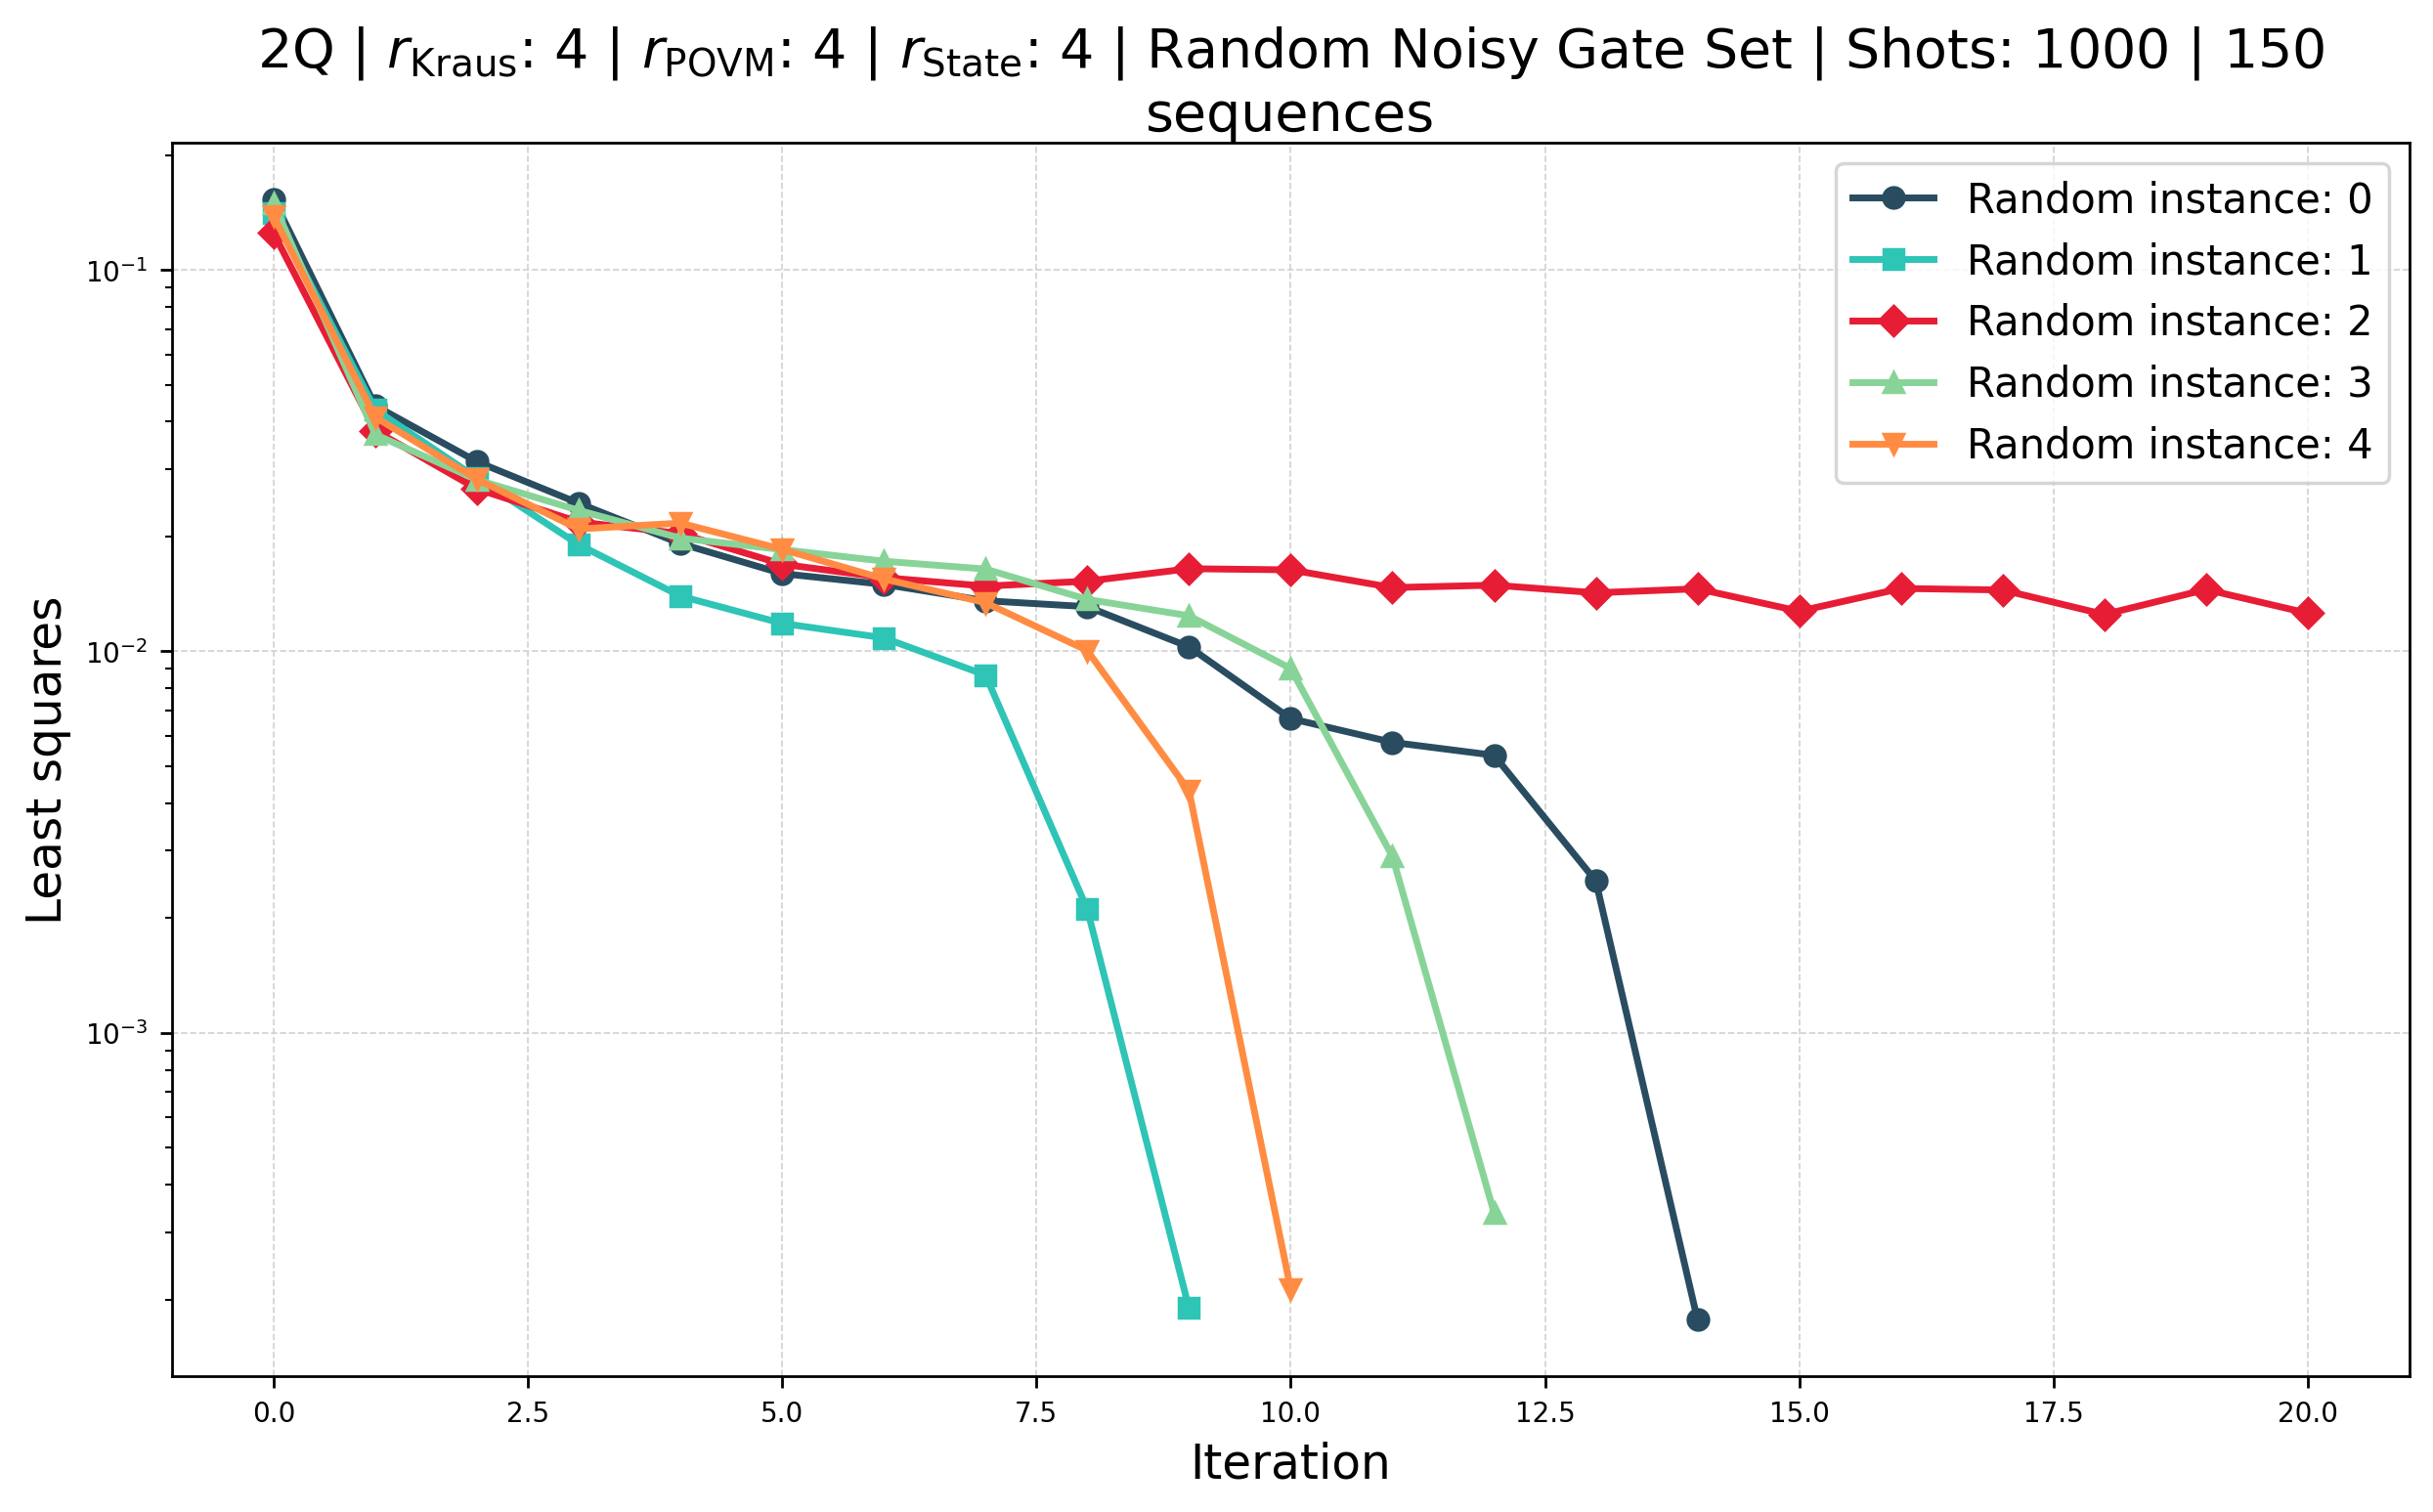

In [43]:
sequences_test = 150

final_results_test = get_all_realizations_for_key(final_results_100_150, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_100_150, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

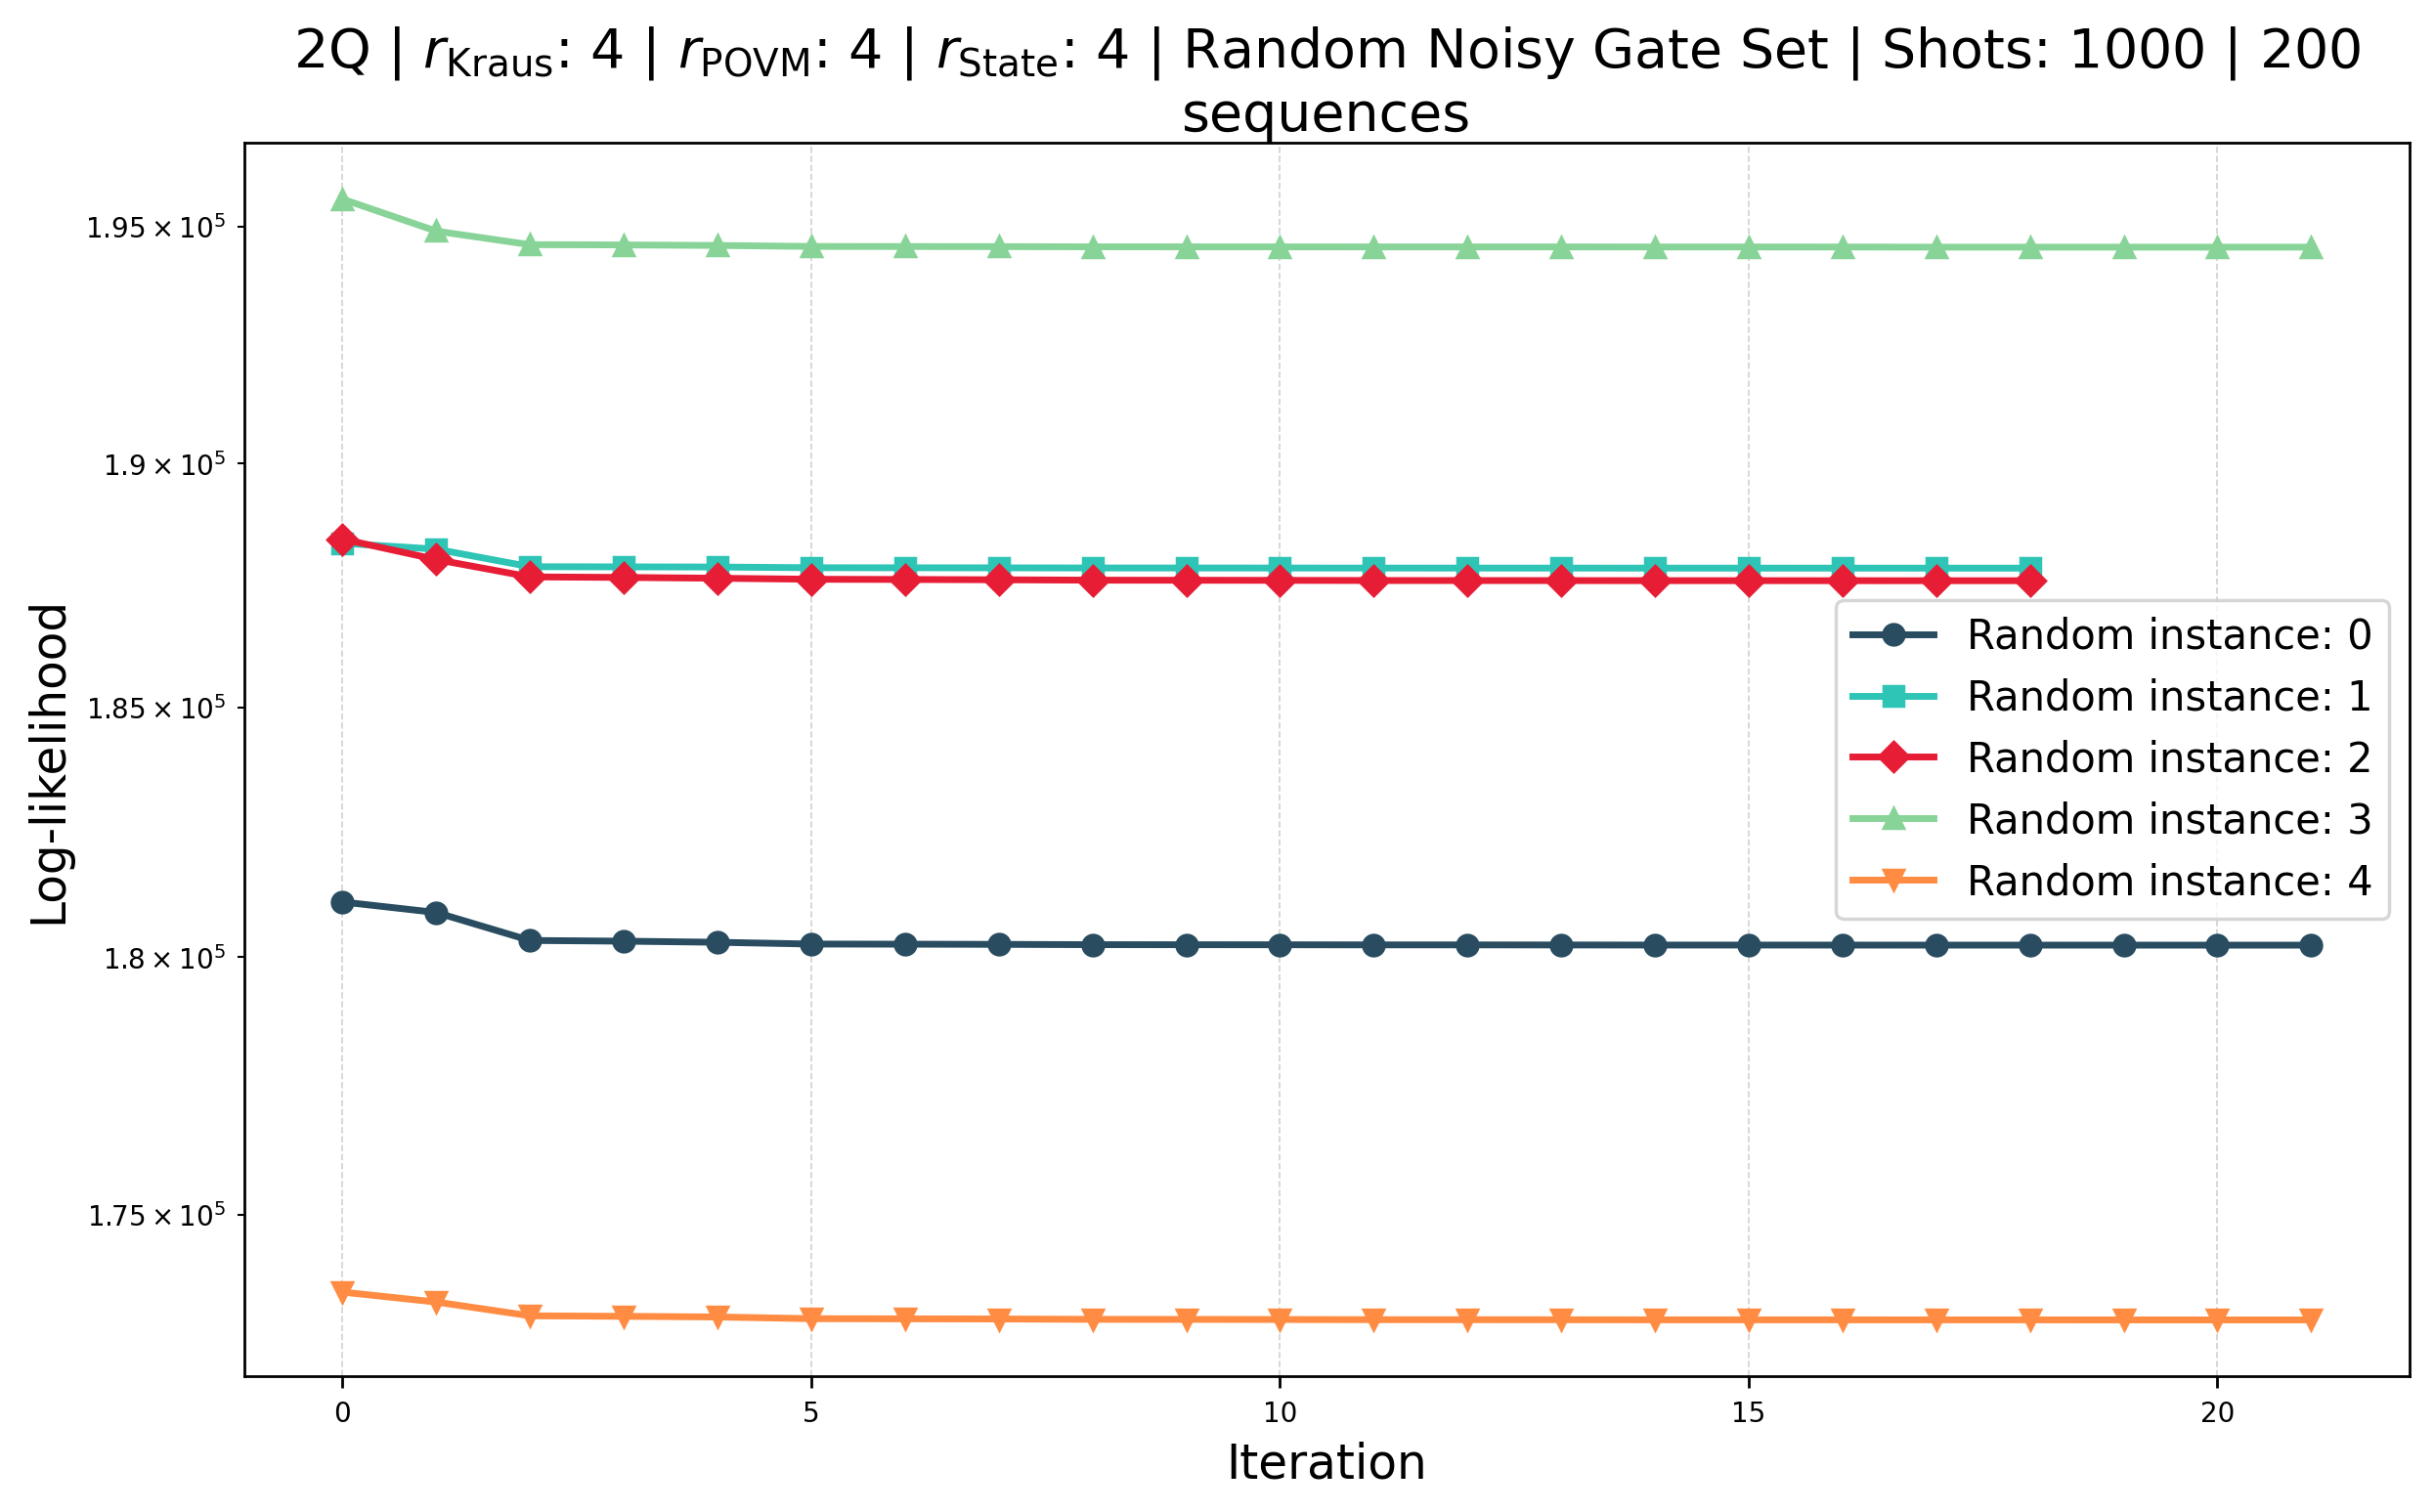

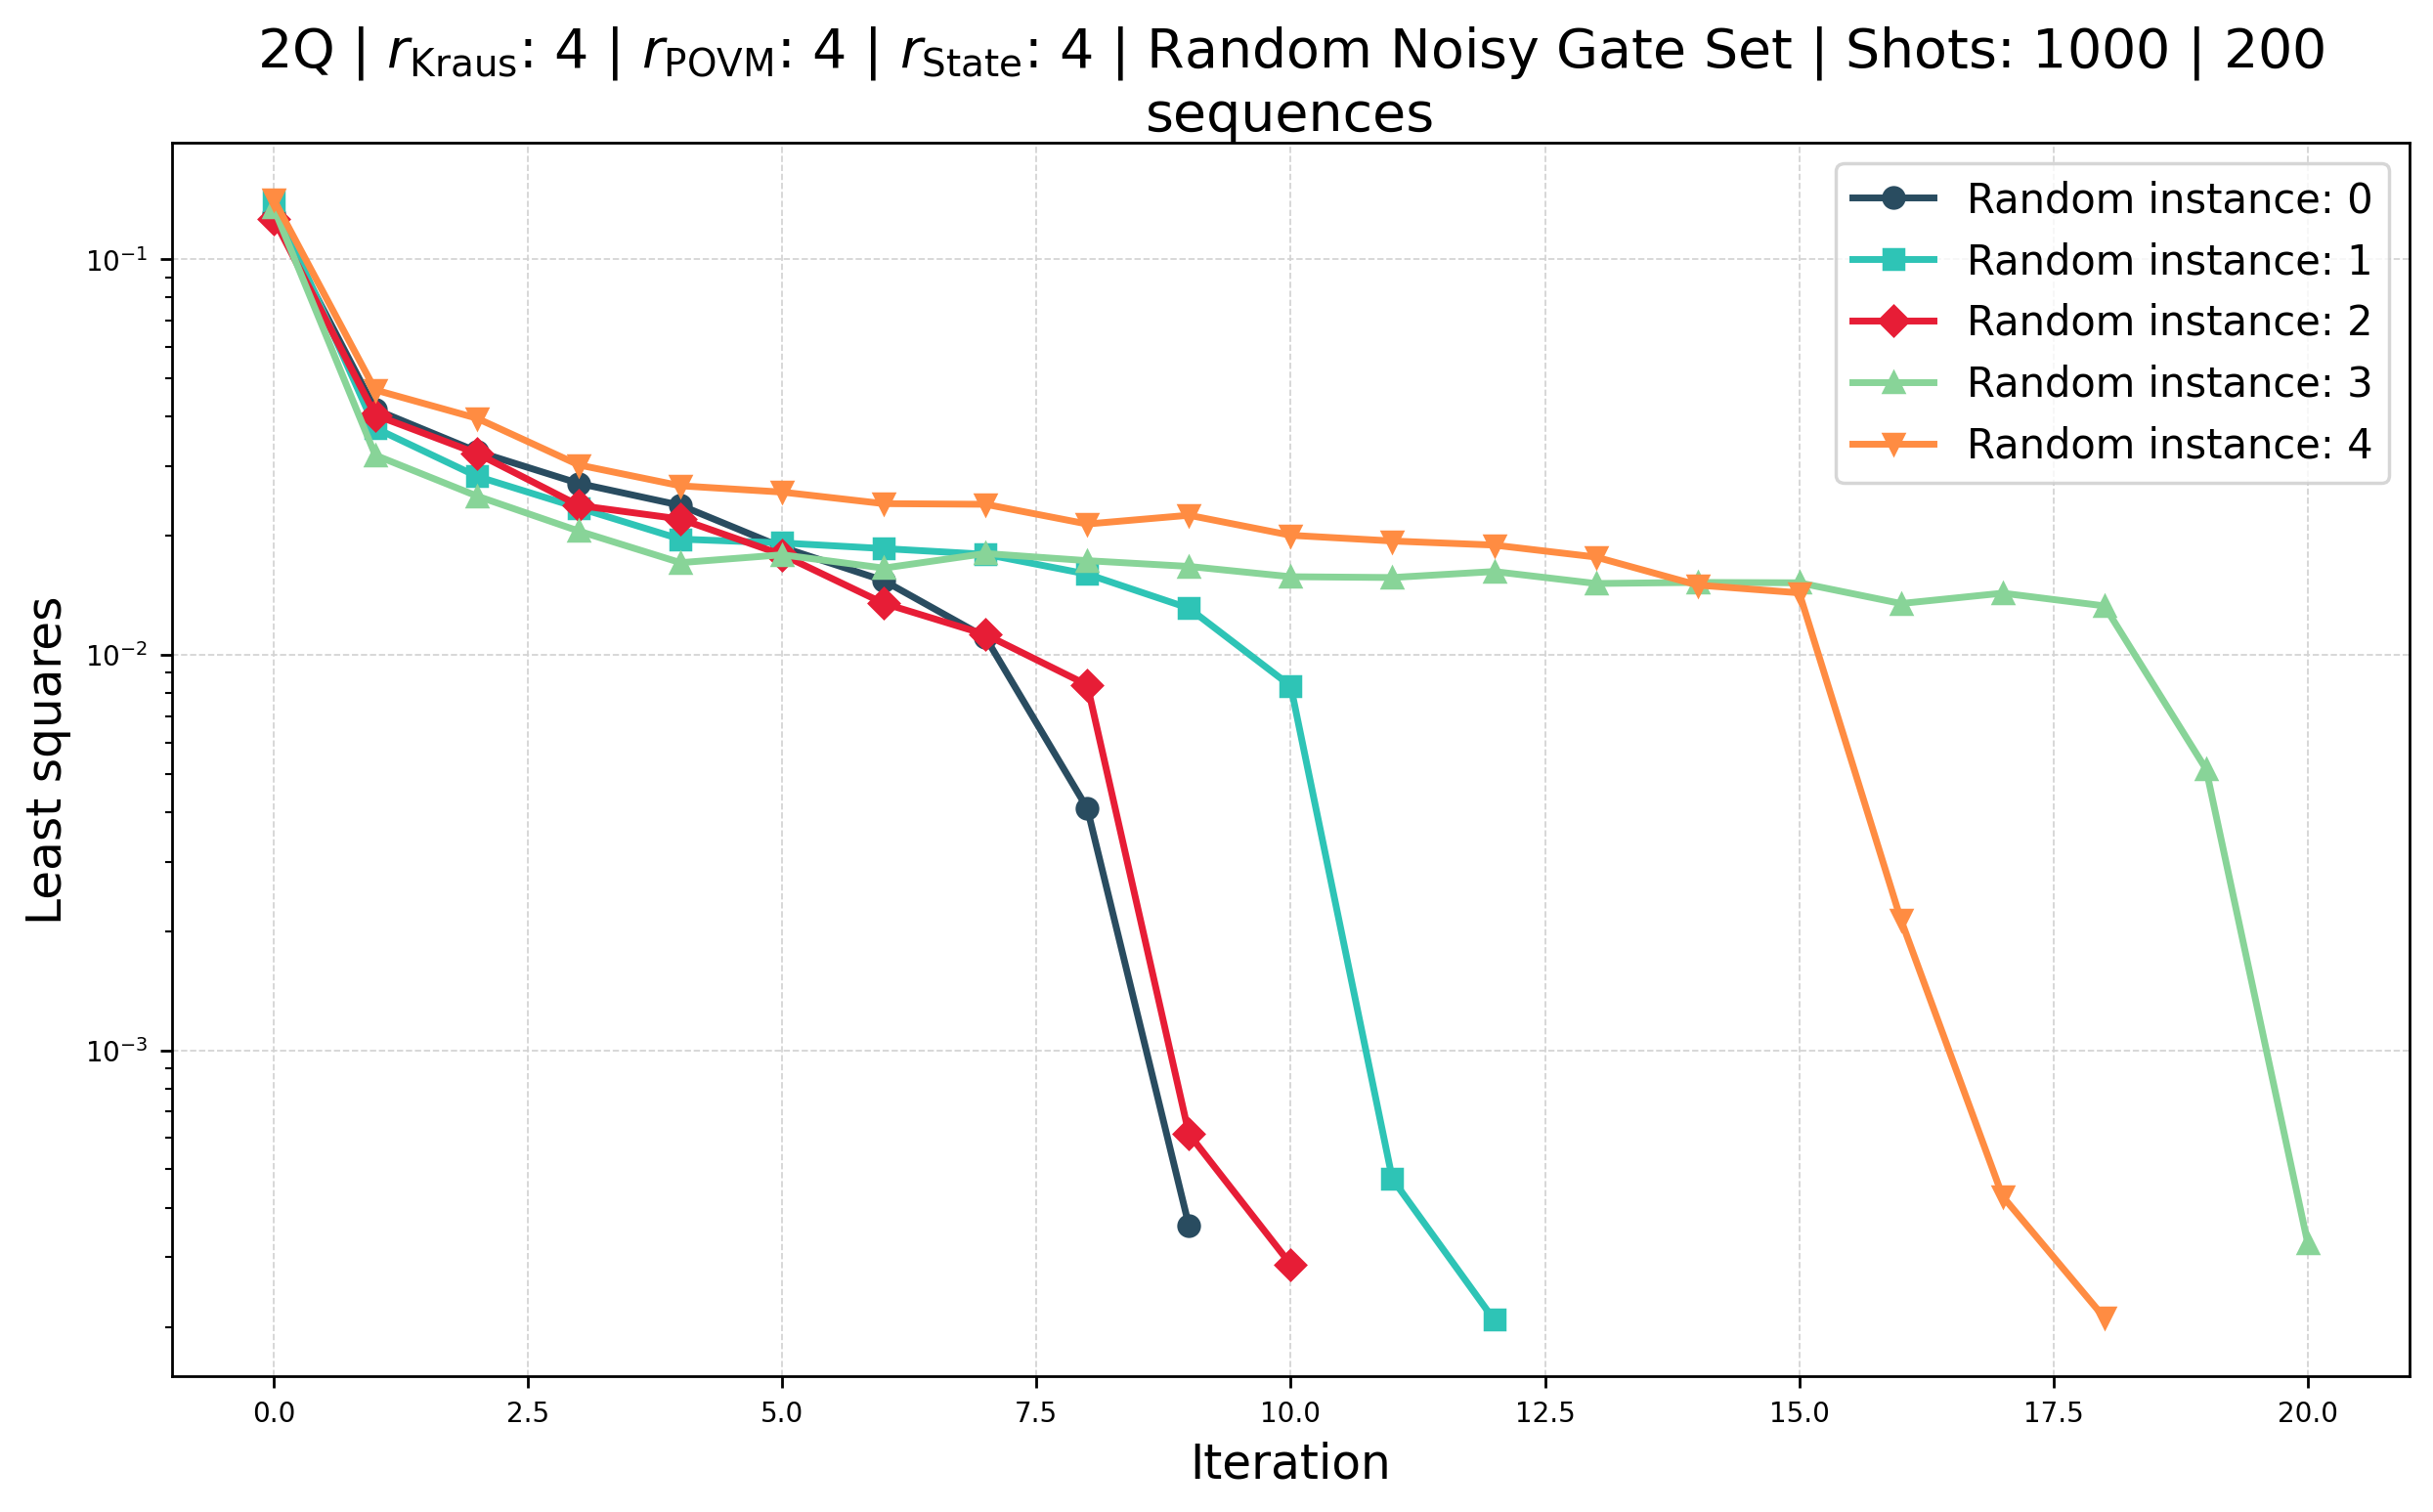

In [50]:
sequences_test = 200

final_results_test = get_all_realizations_for_key(final_results_200_250, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_200_250, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

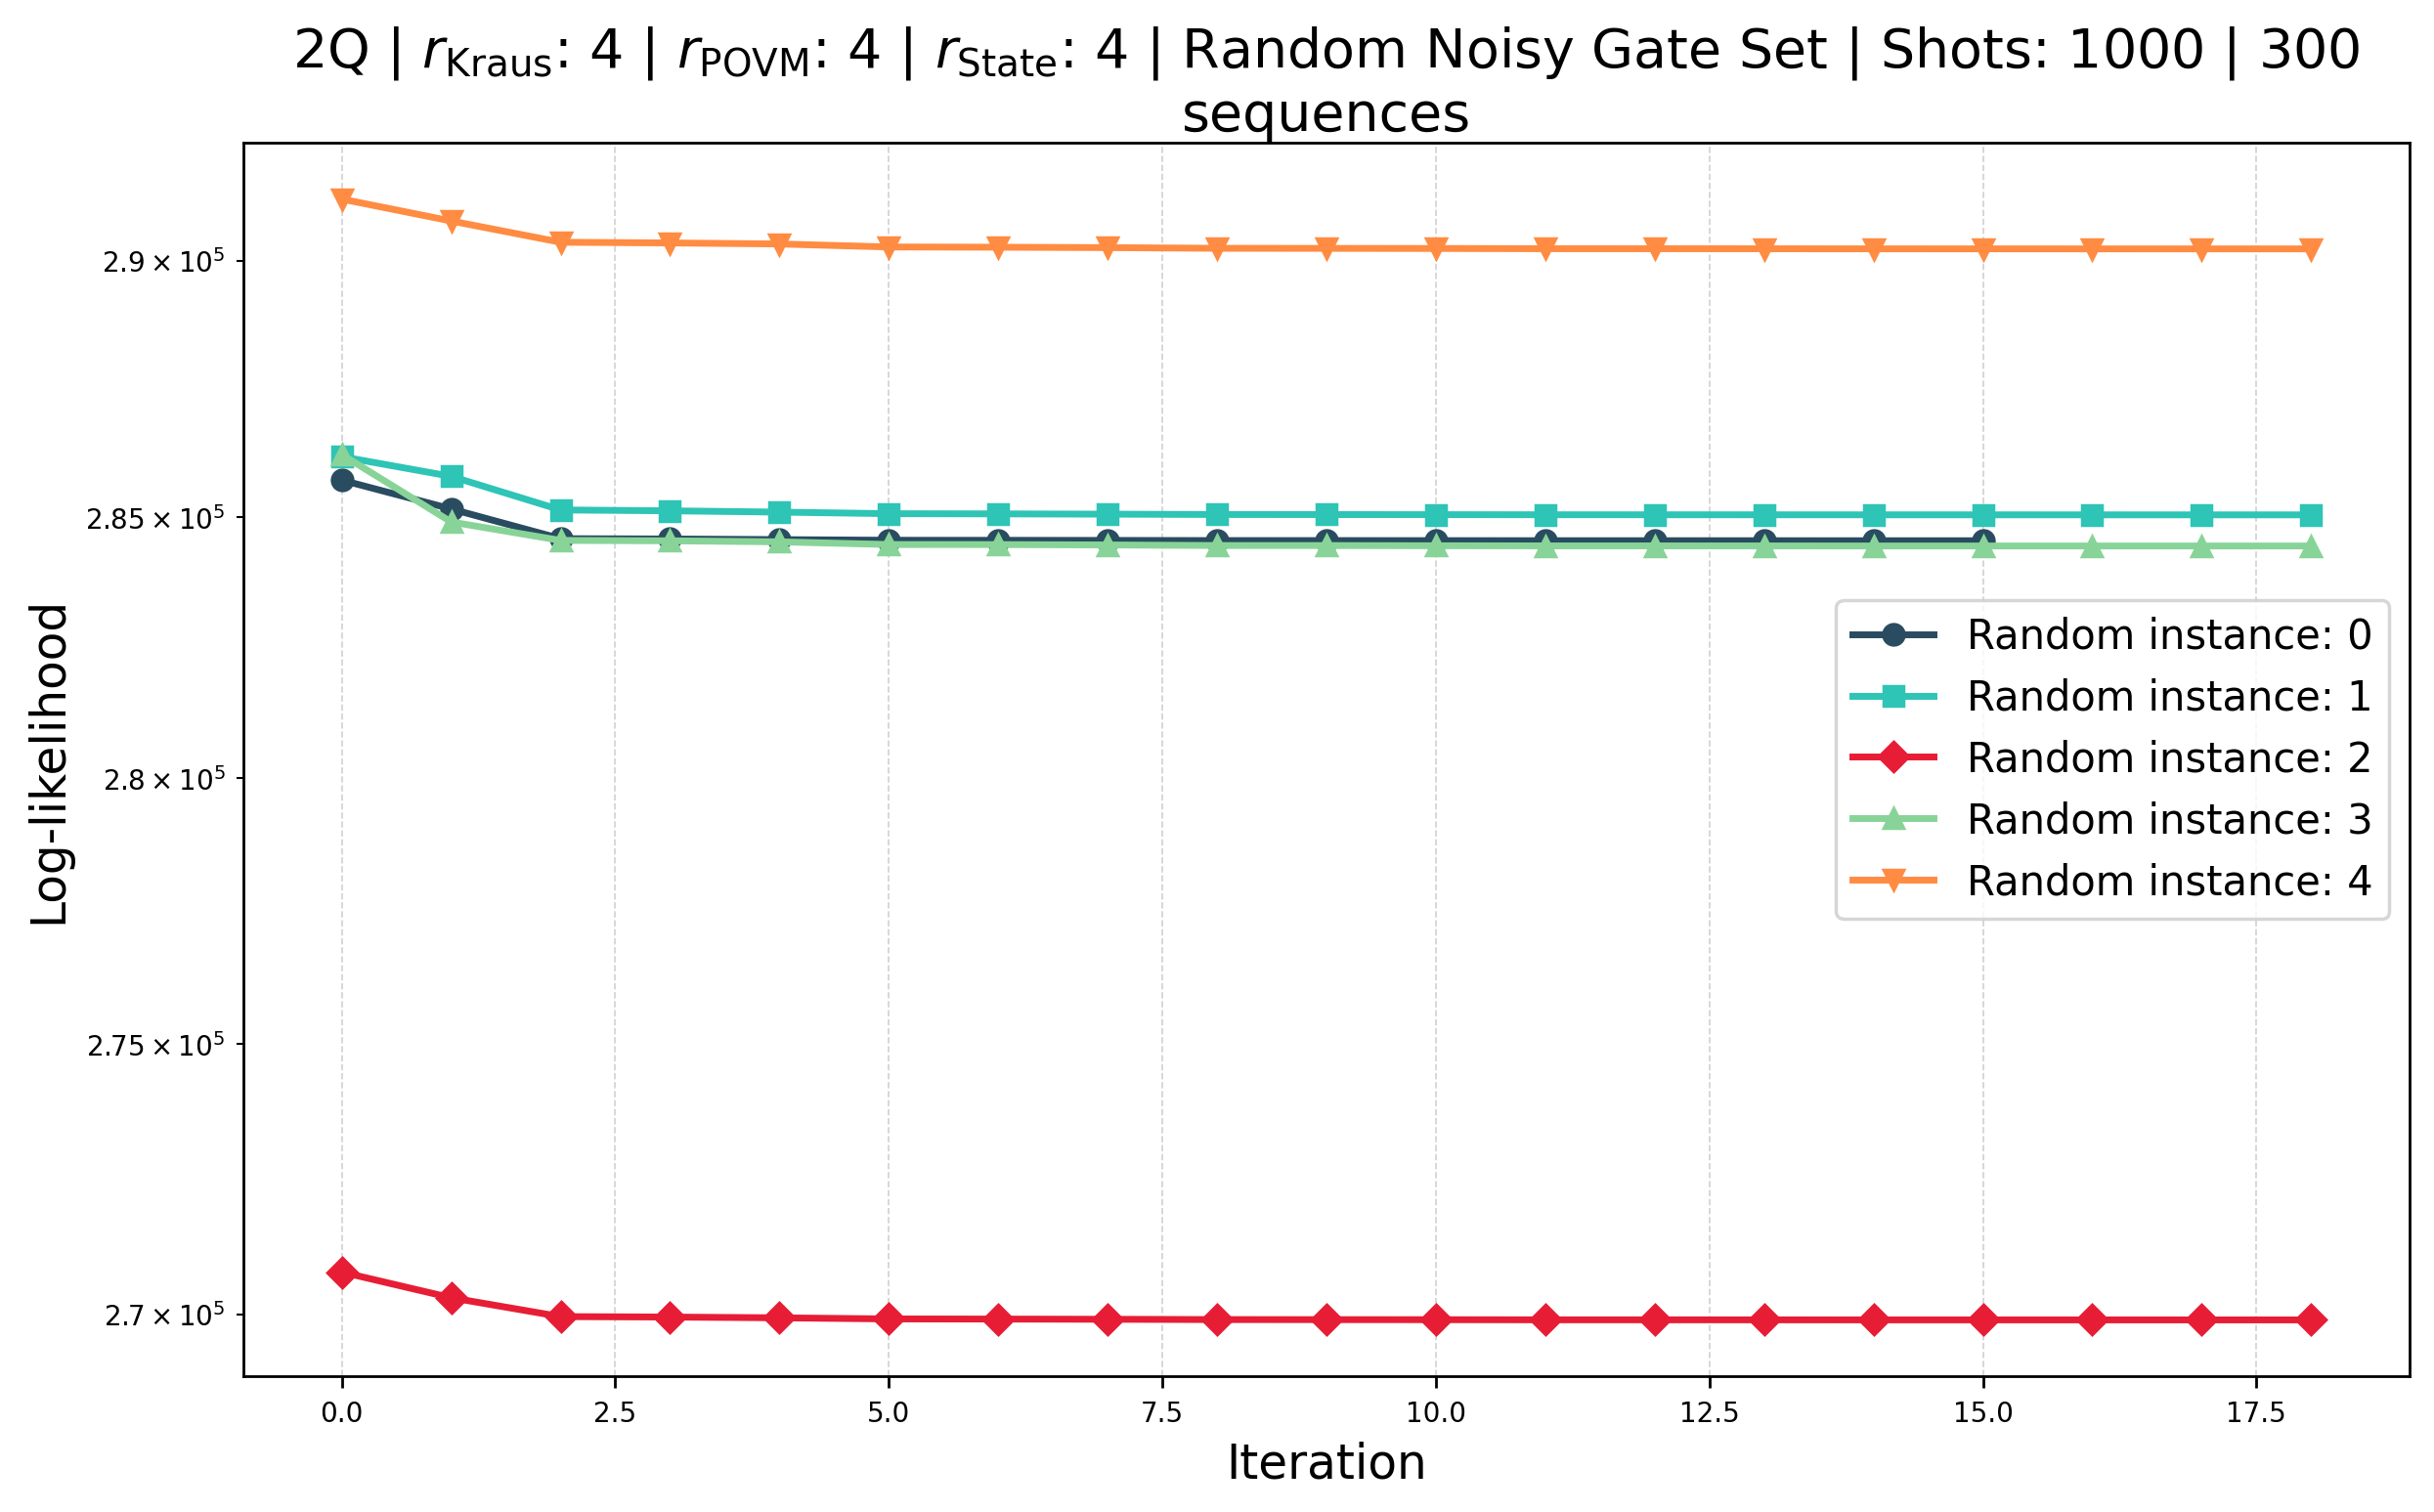

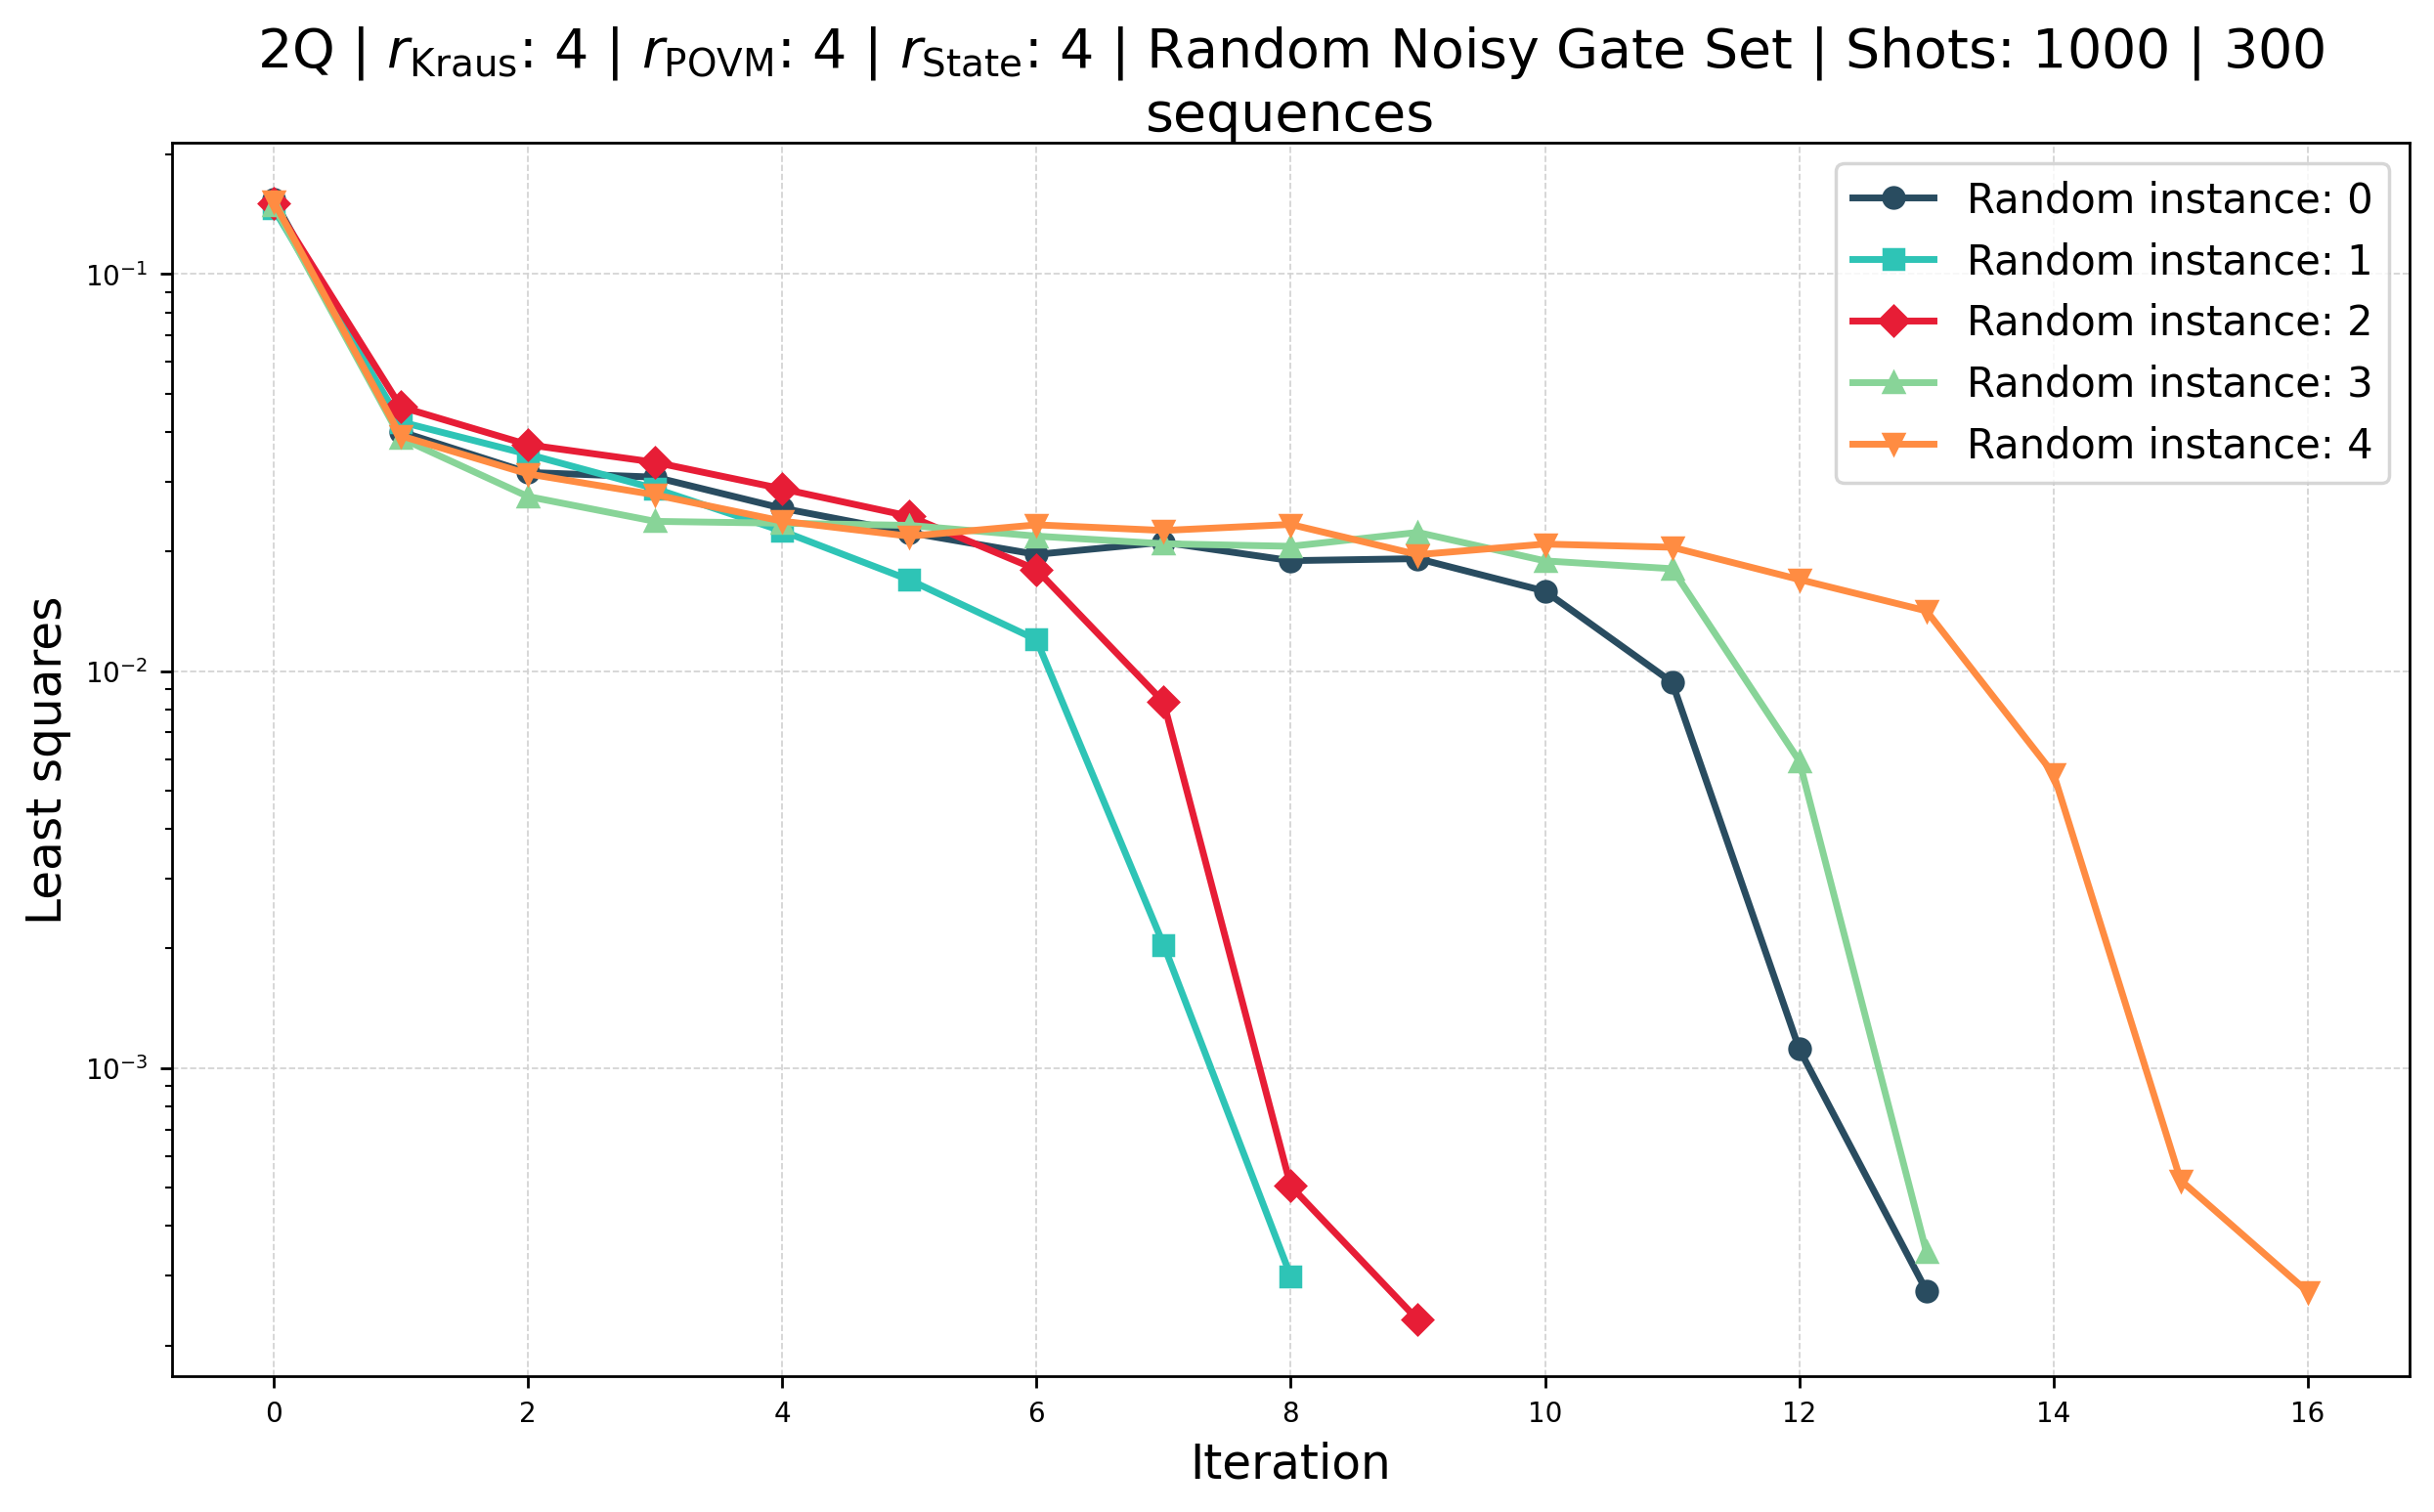

In [36]:
sequences_test = 300

final_results_test = get_all_realizations_for_key(final_results_300_350, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_300_350, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

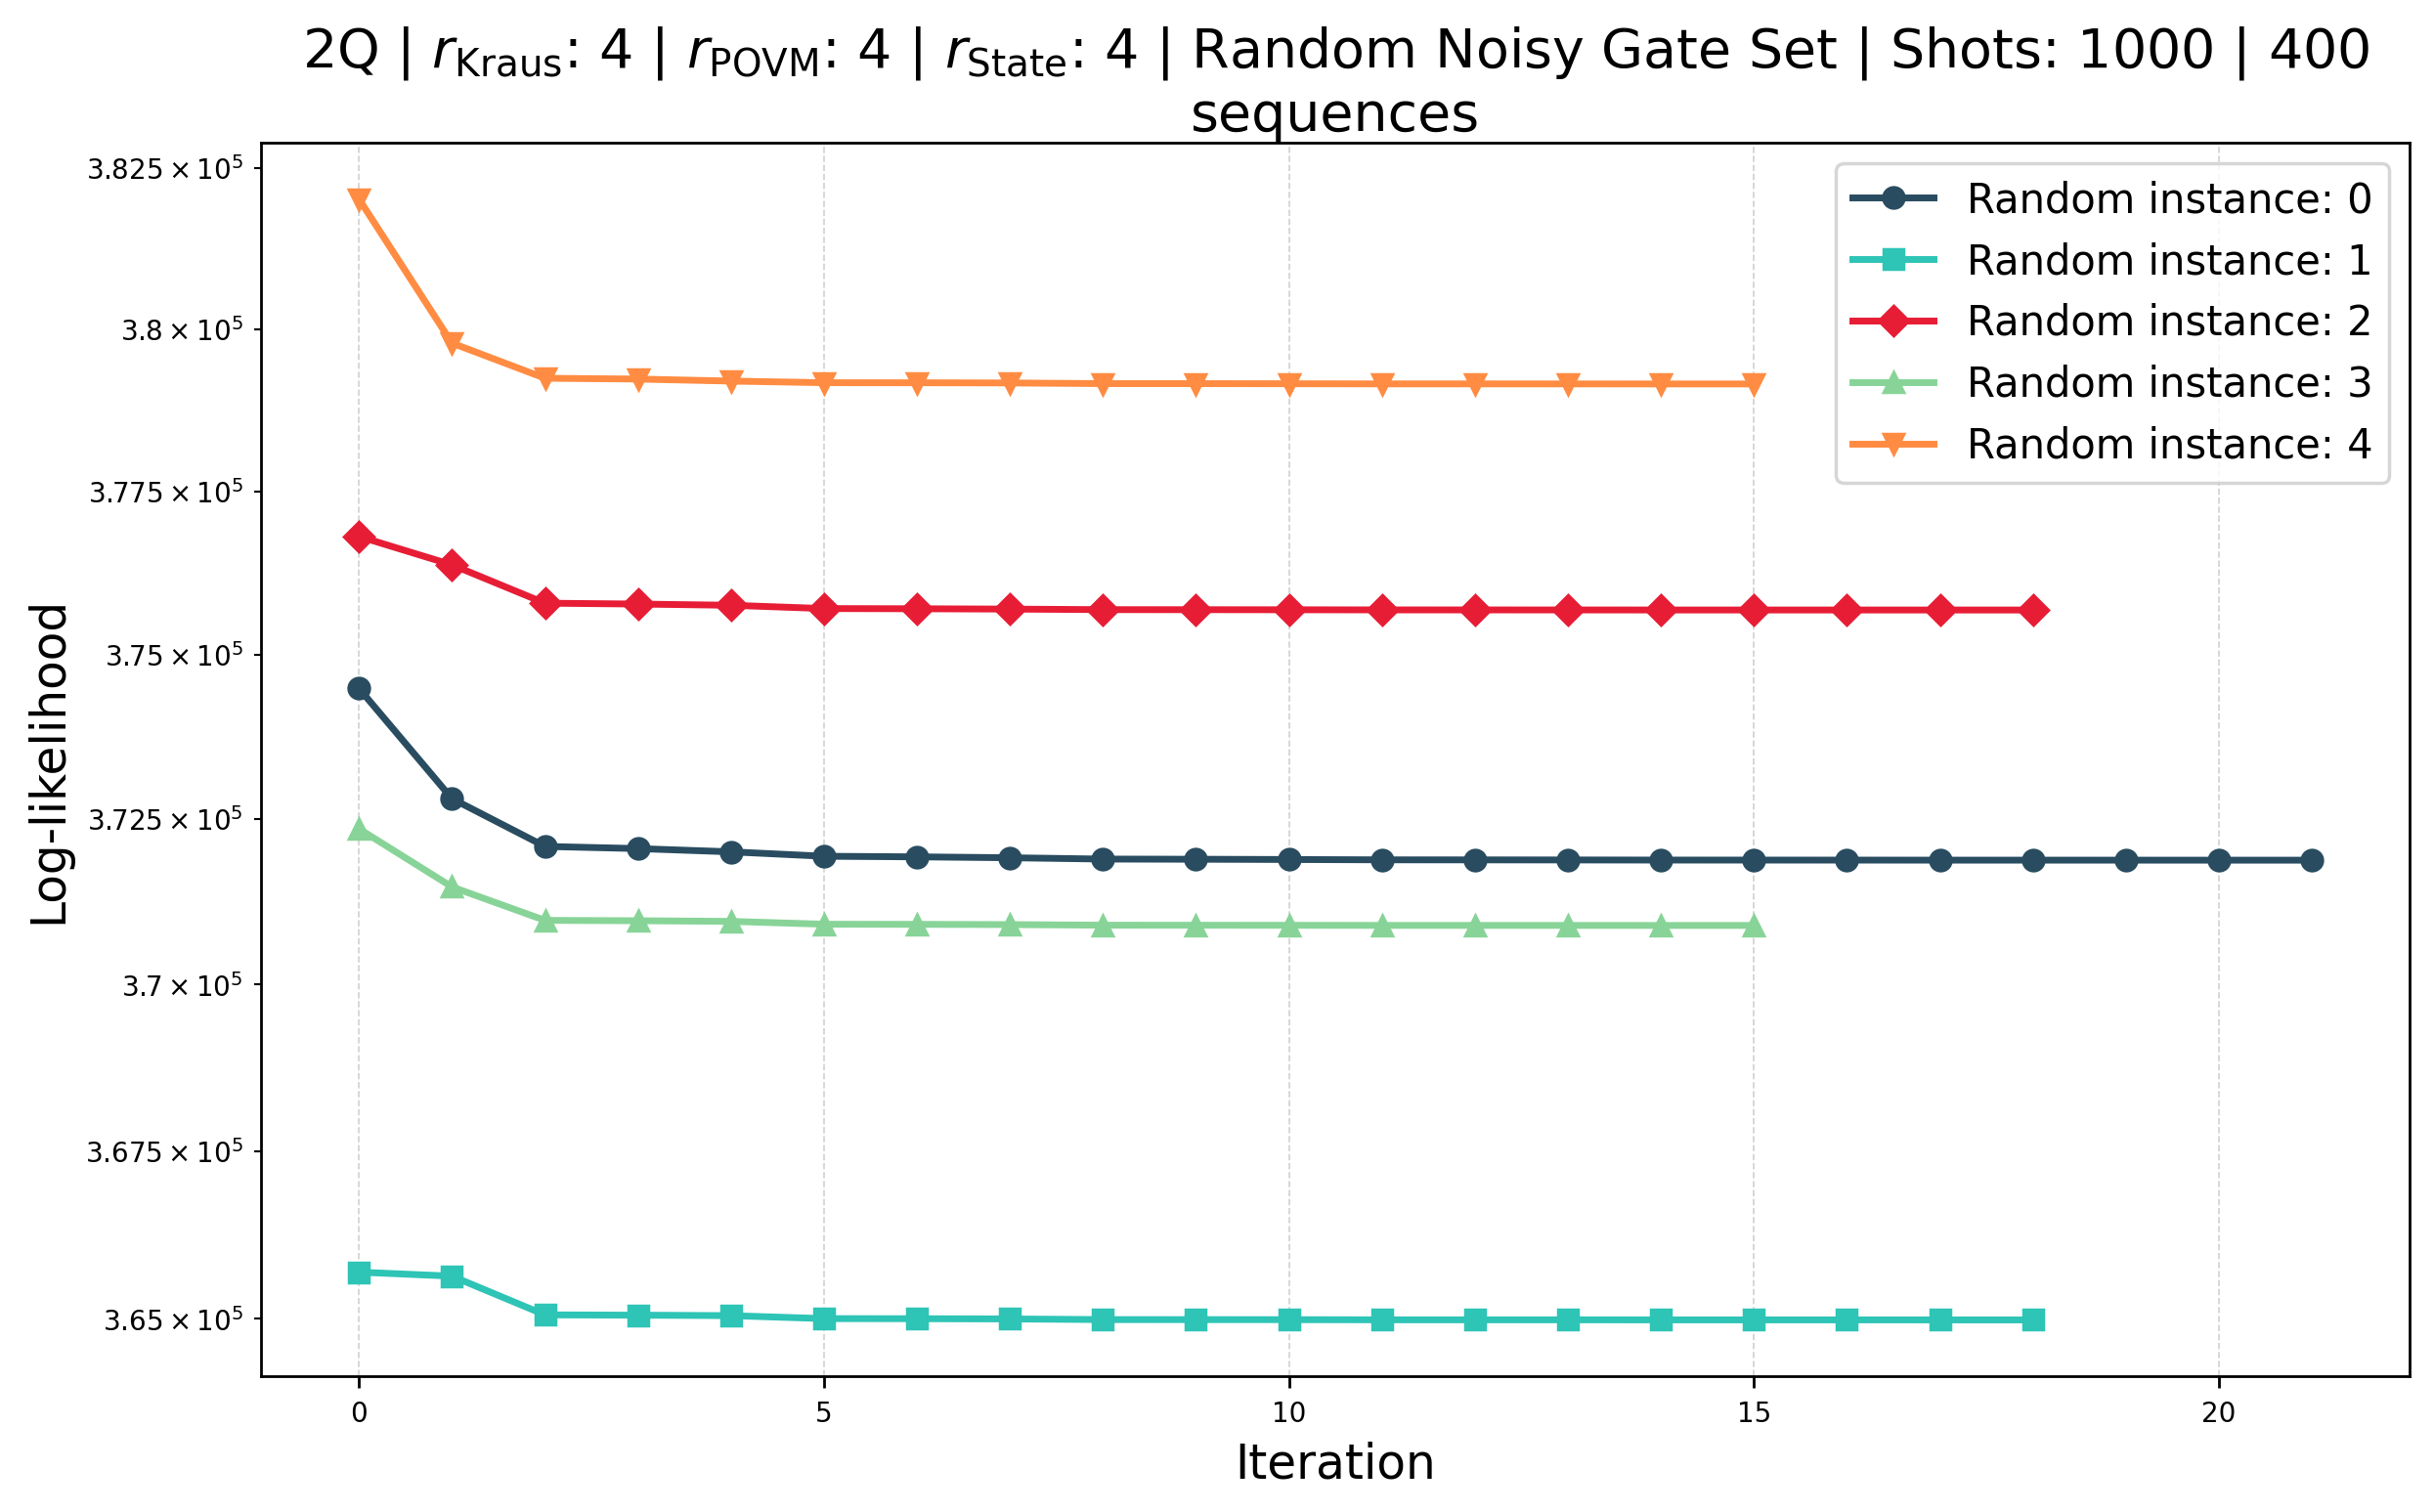

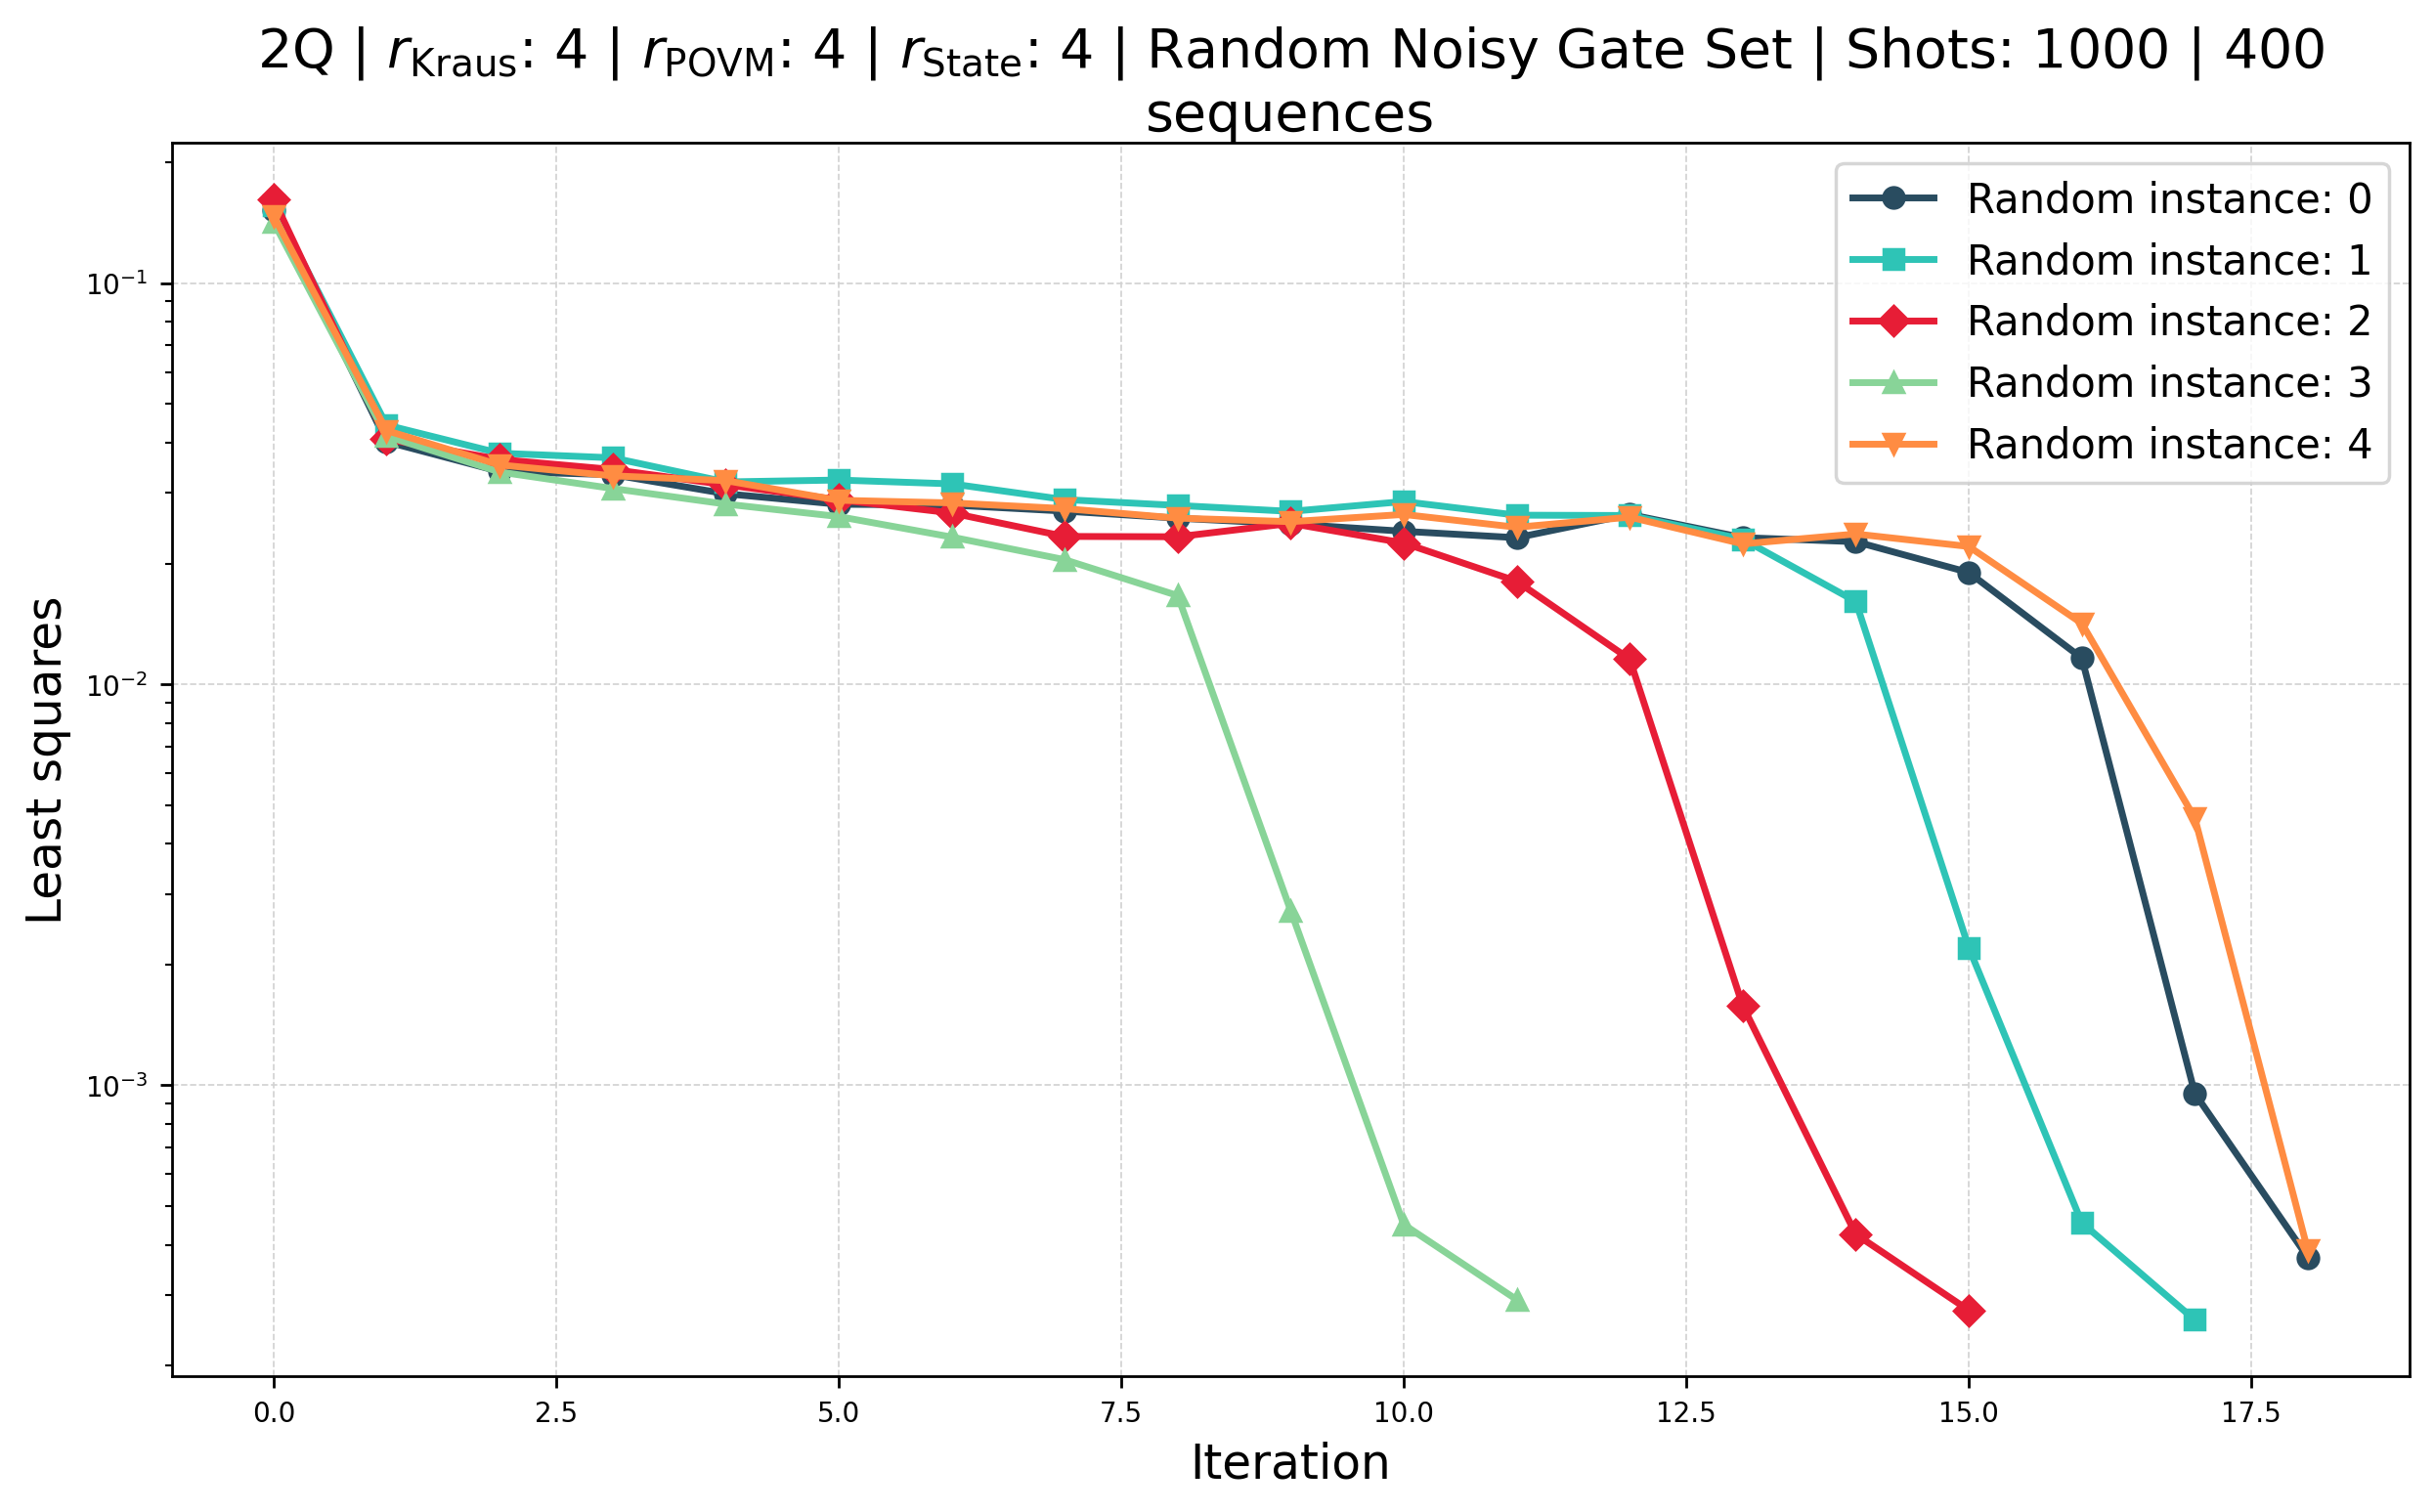

In [33]:
sequences_test = 400

final_results_test = get_all_realizations_for_key(final_results_400_450, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_400_450, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

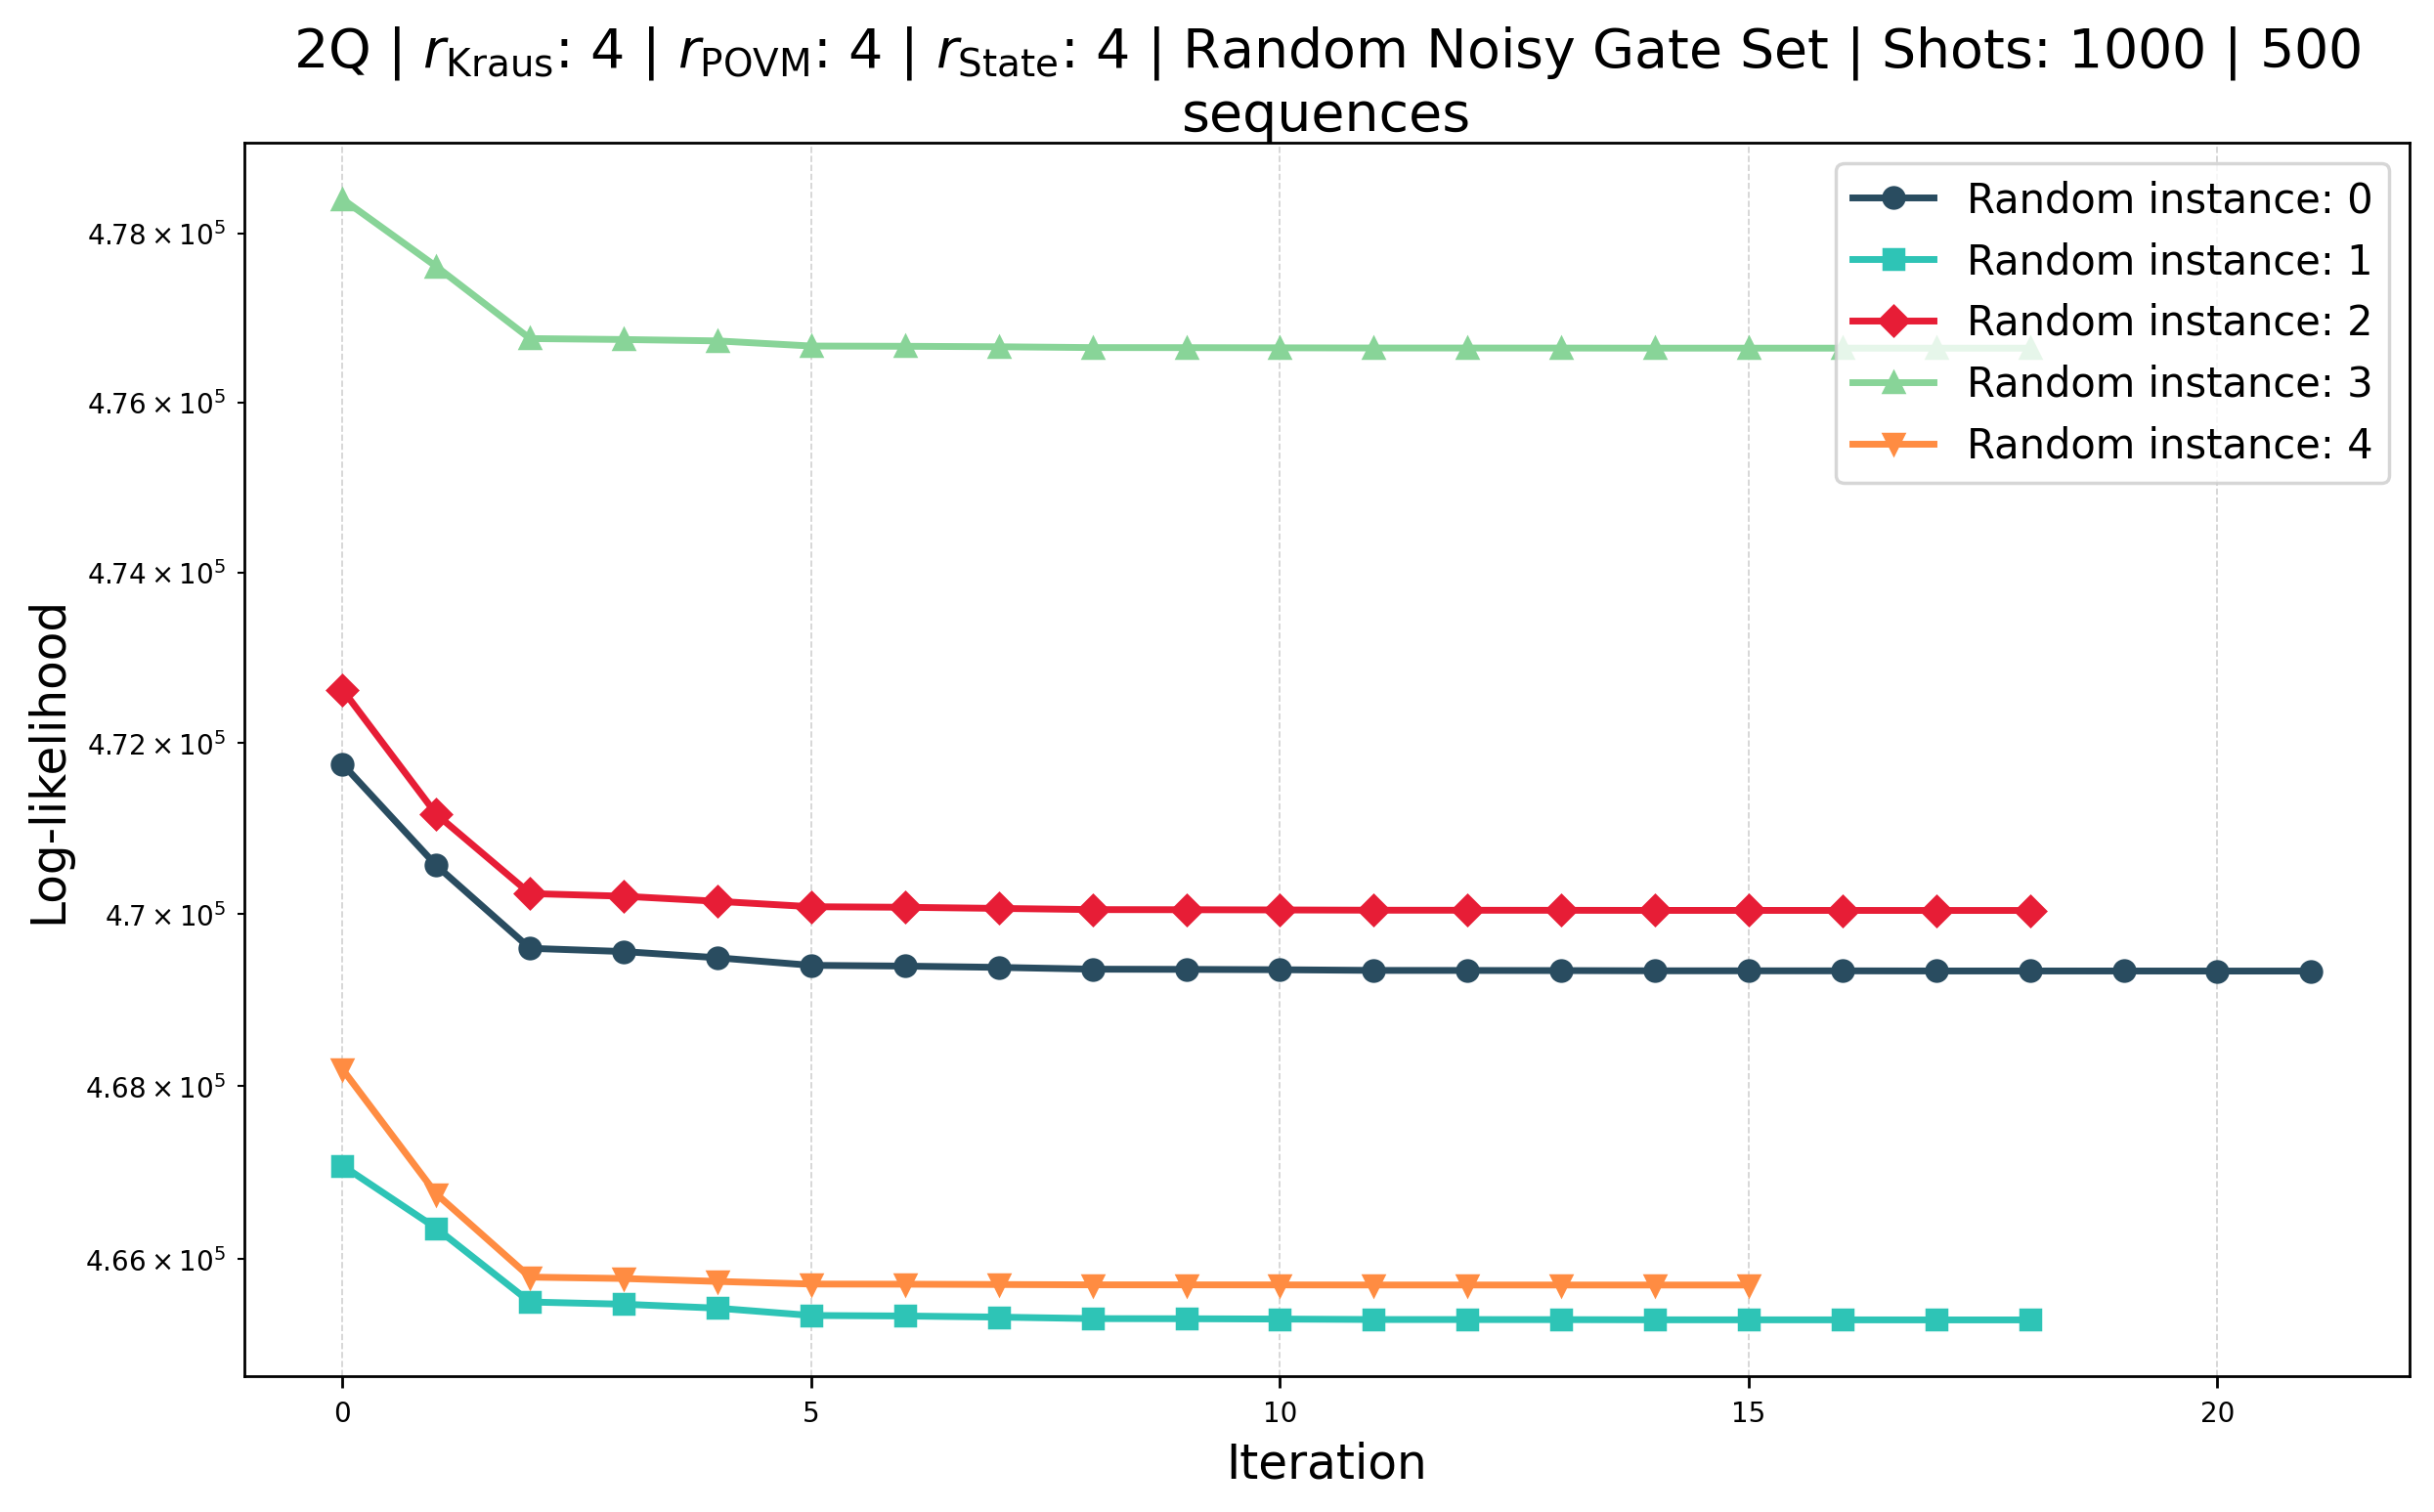

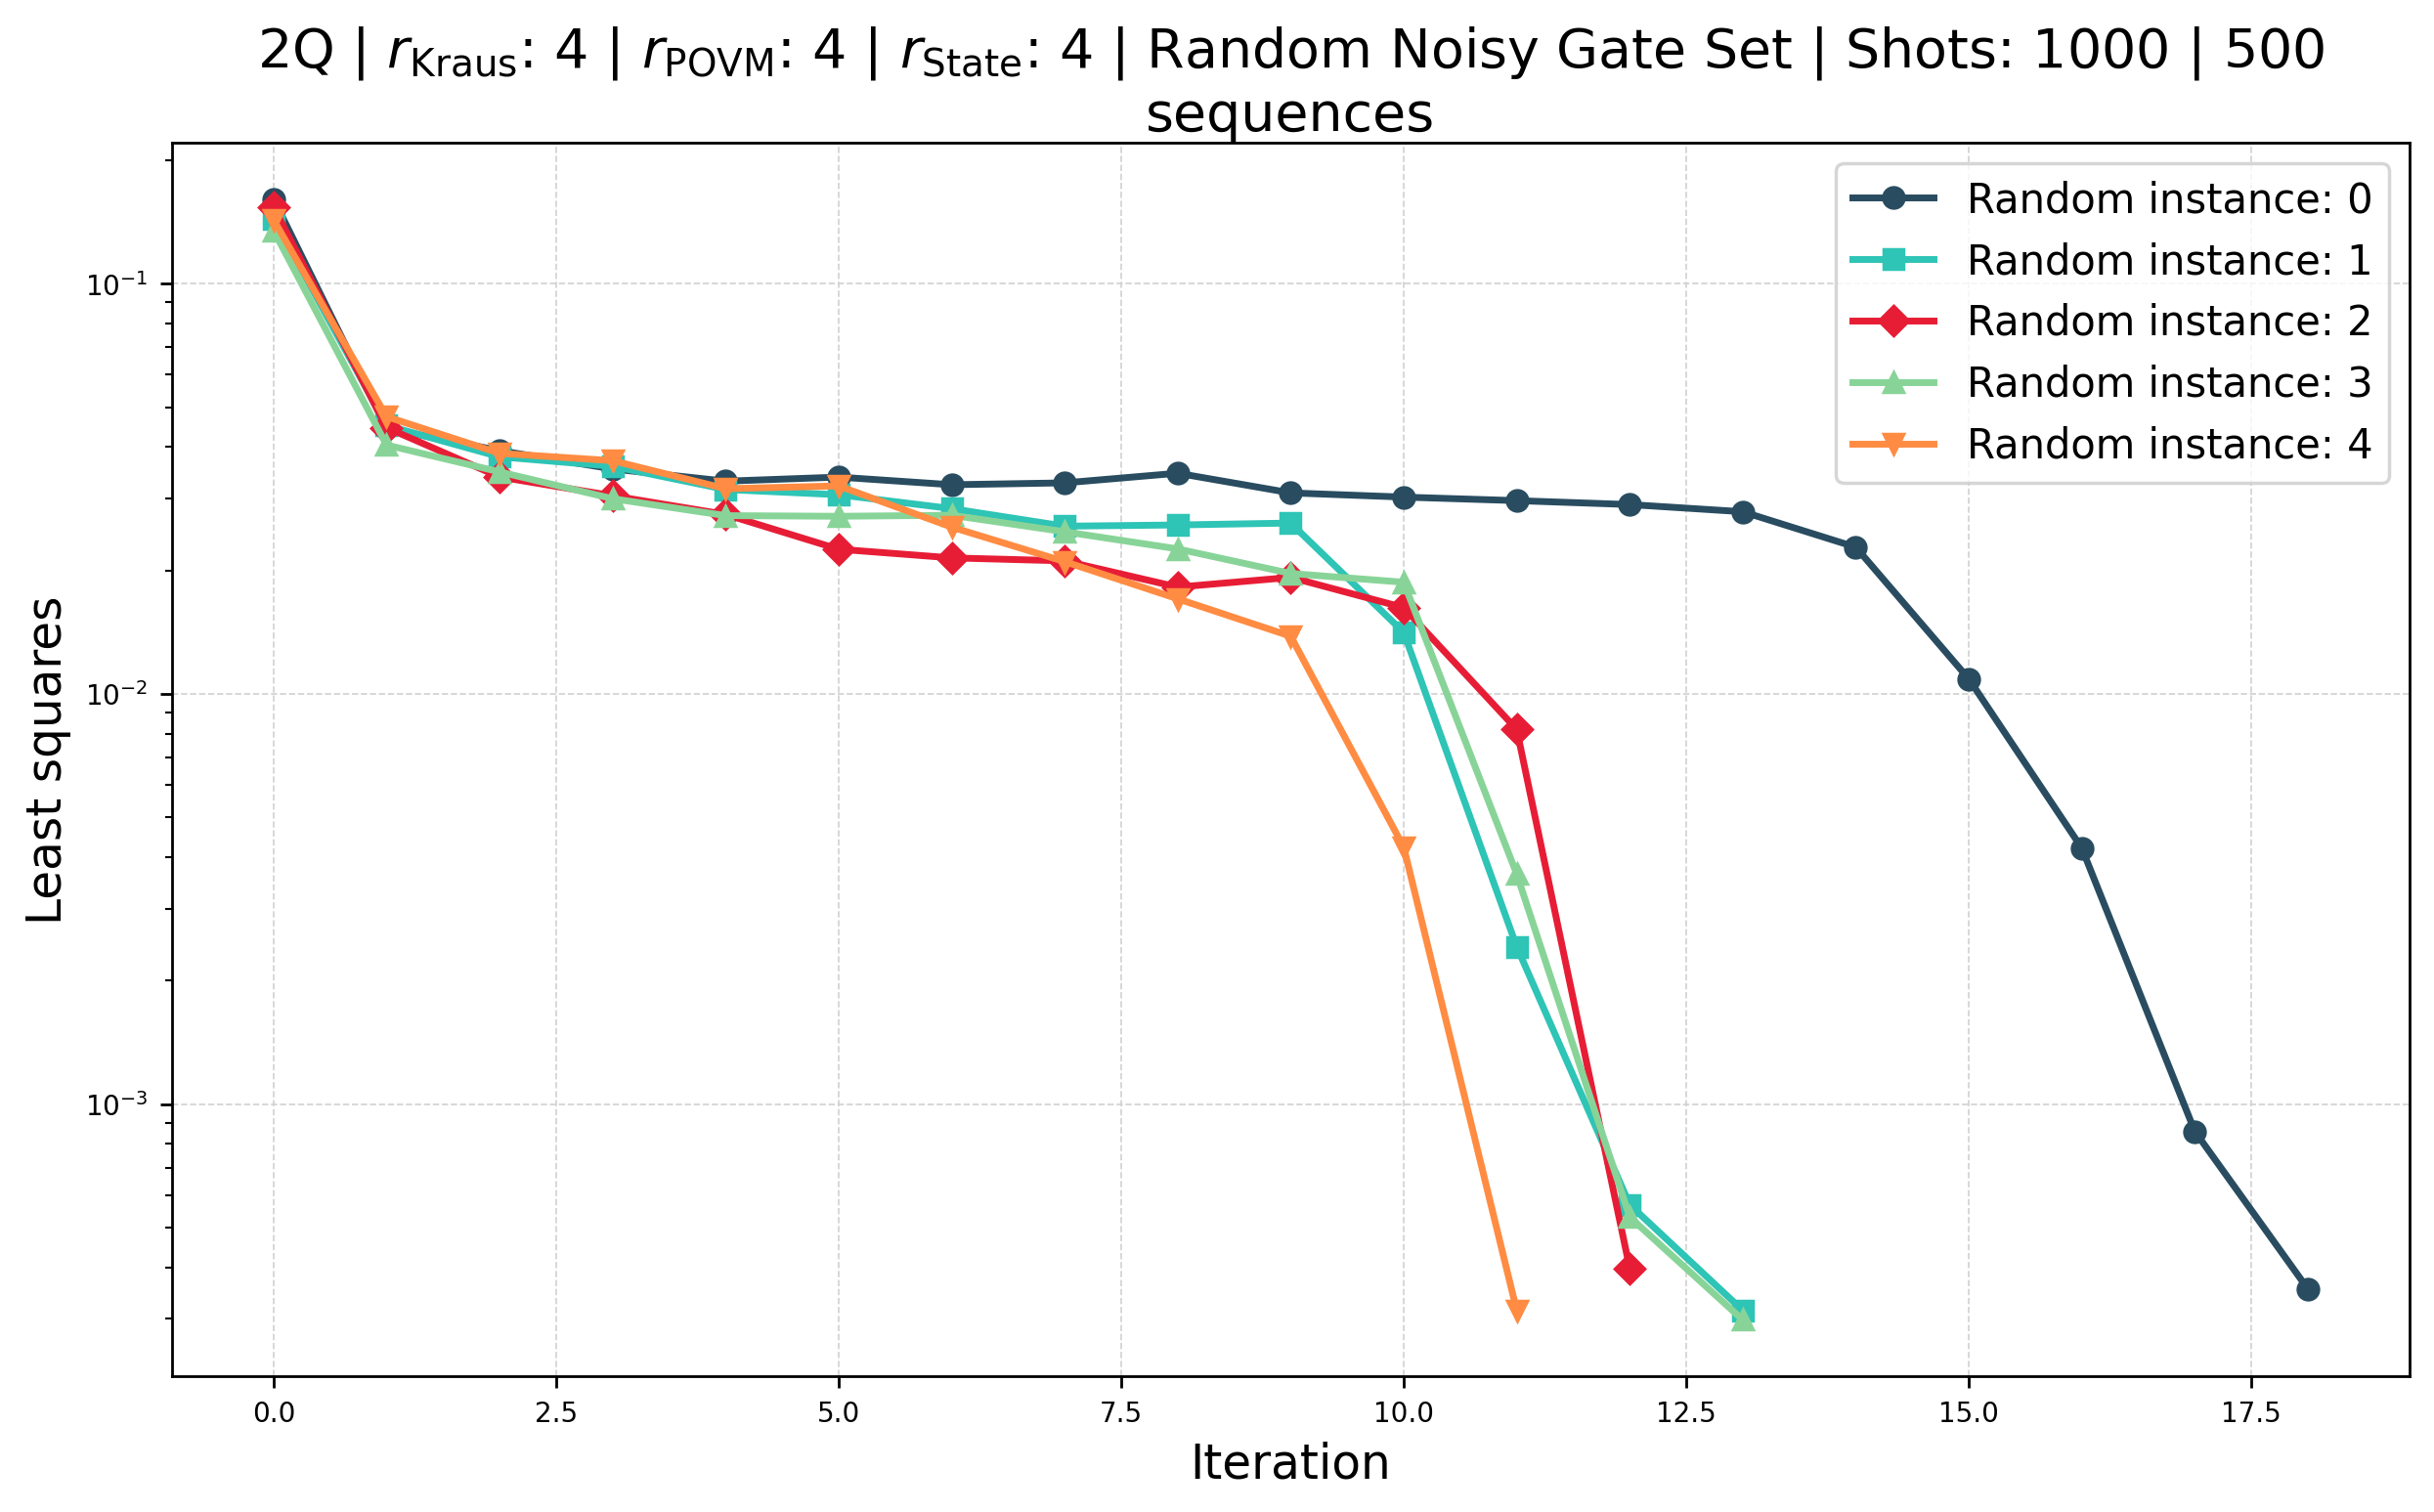

In [30]:
sequences_test = 500

final_results_test = get_all_realizations_for_key(final_results_500_550, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_500_550, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

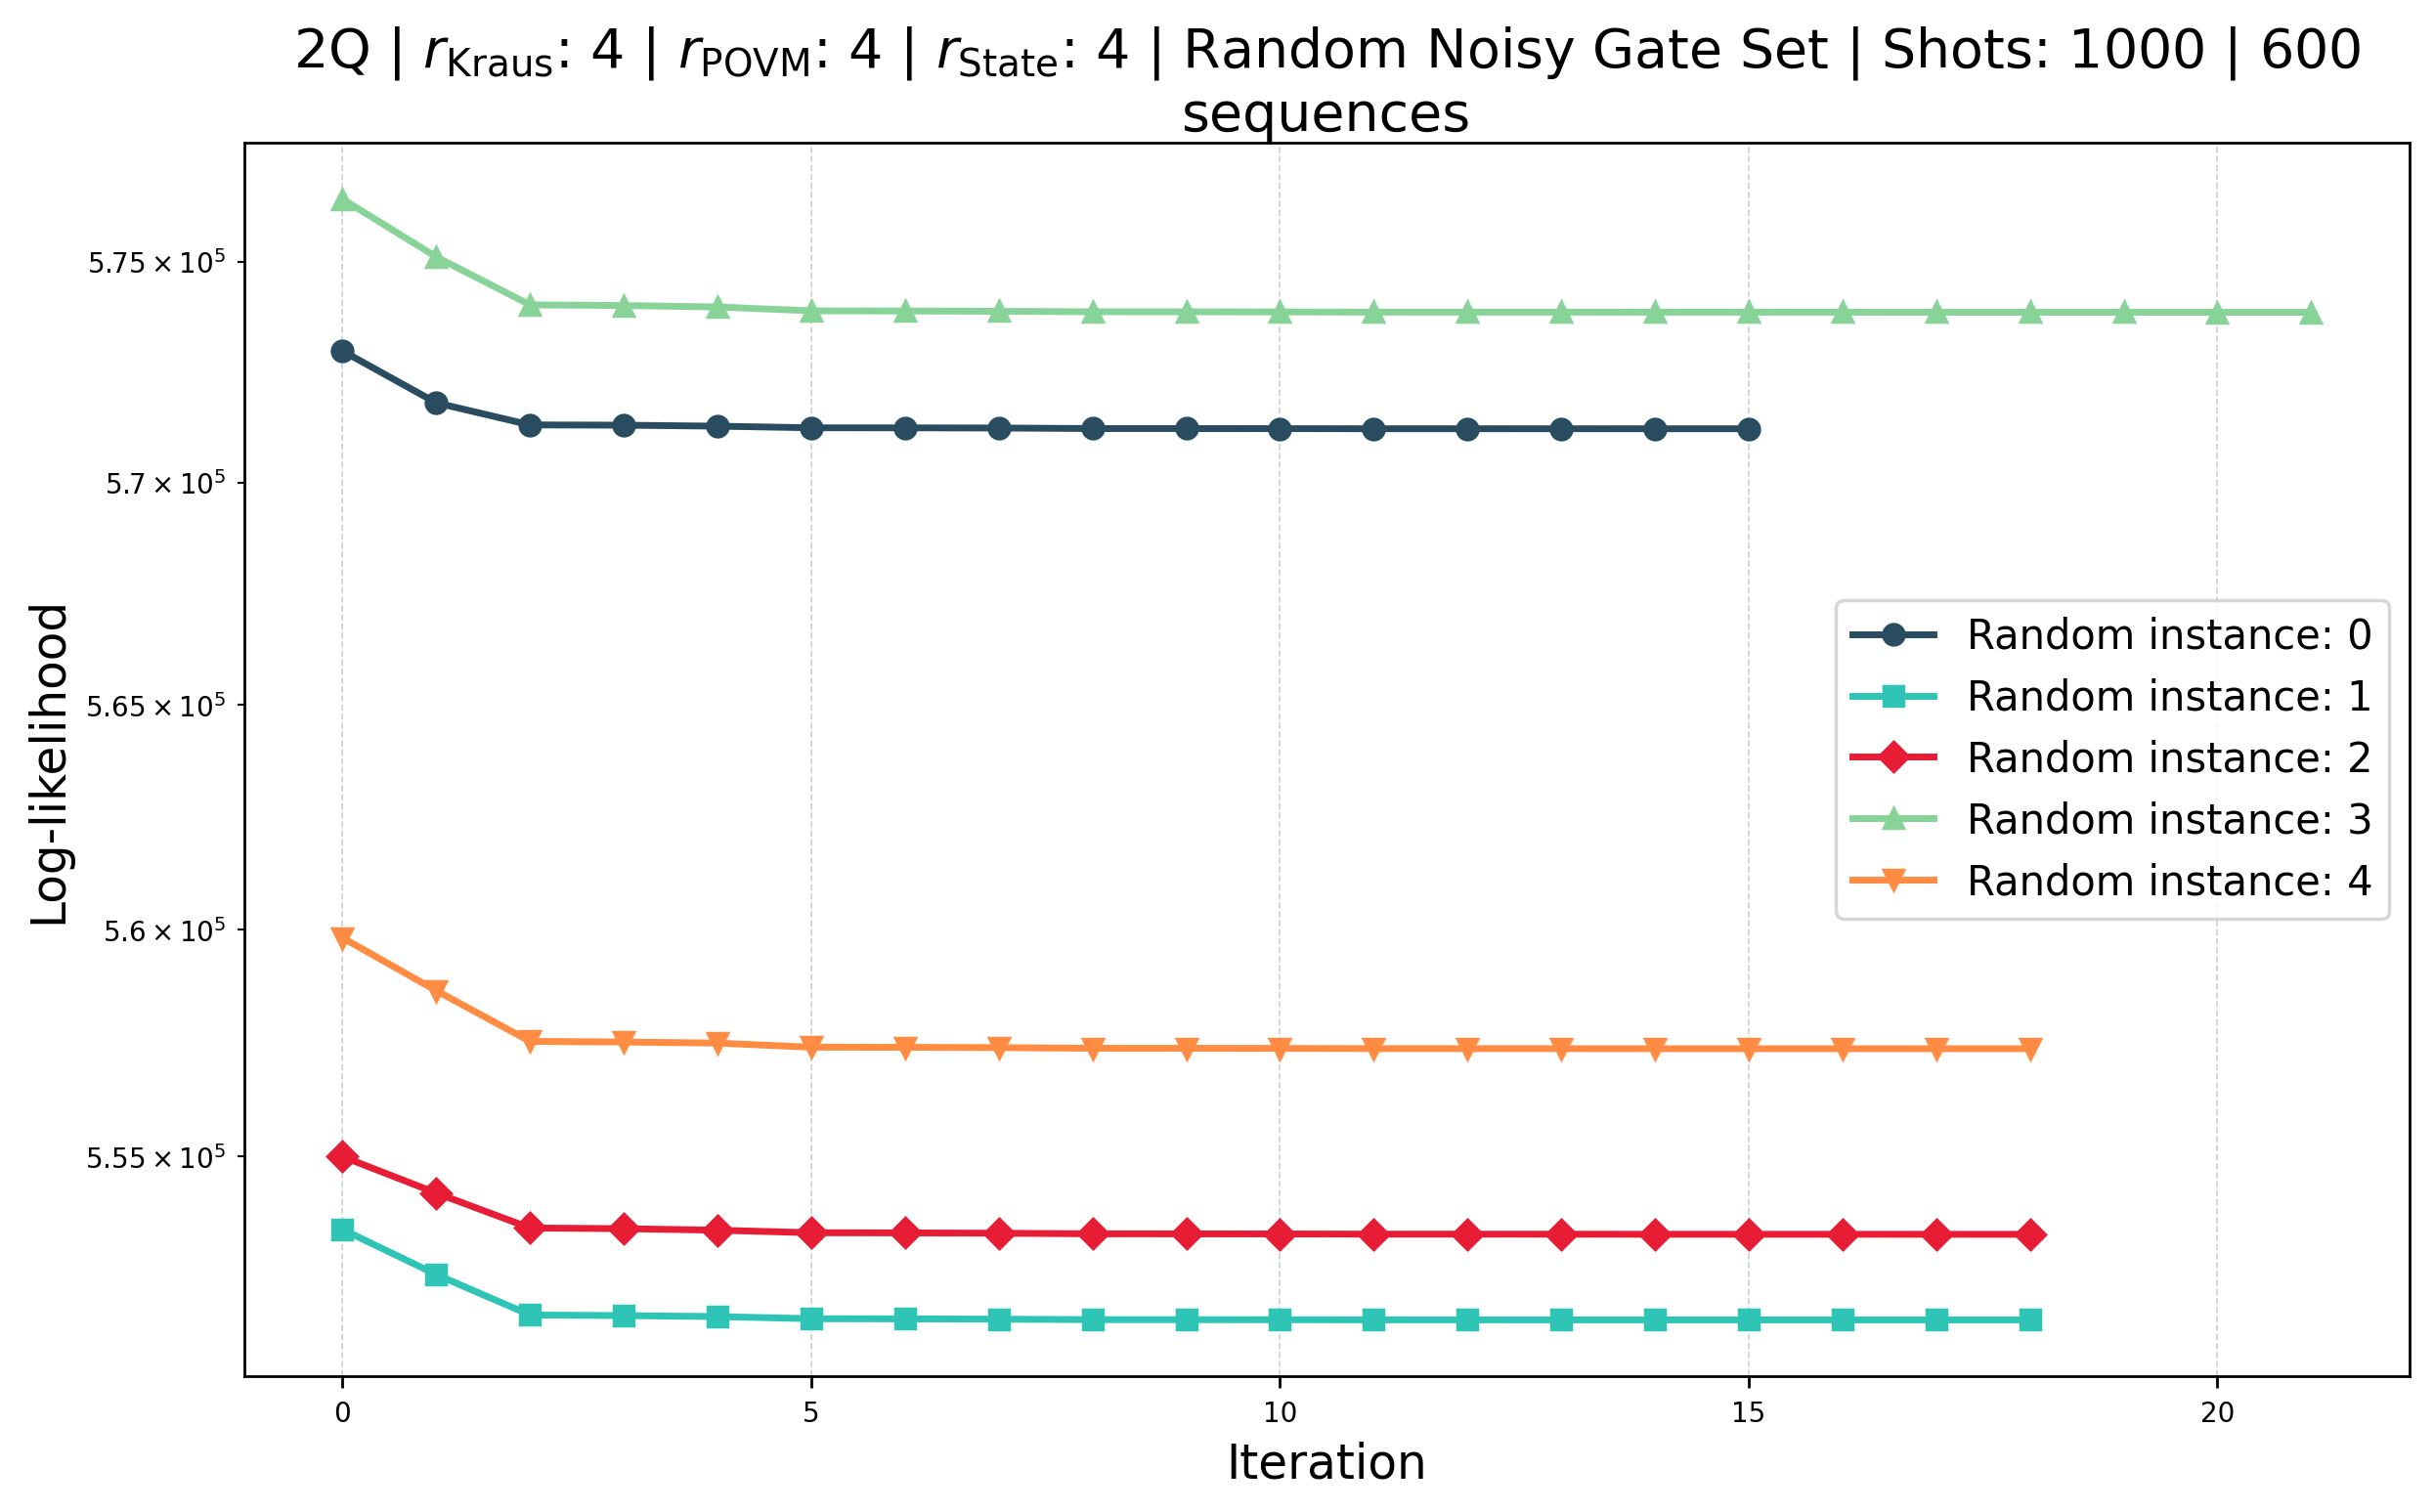

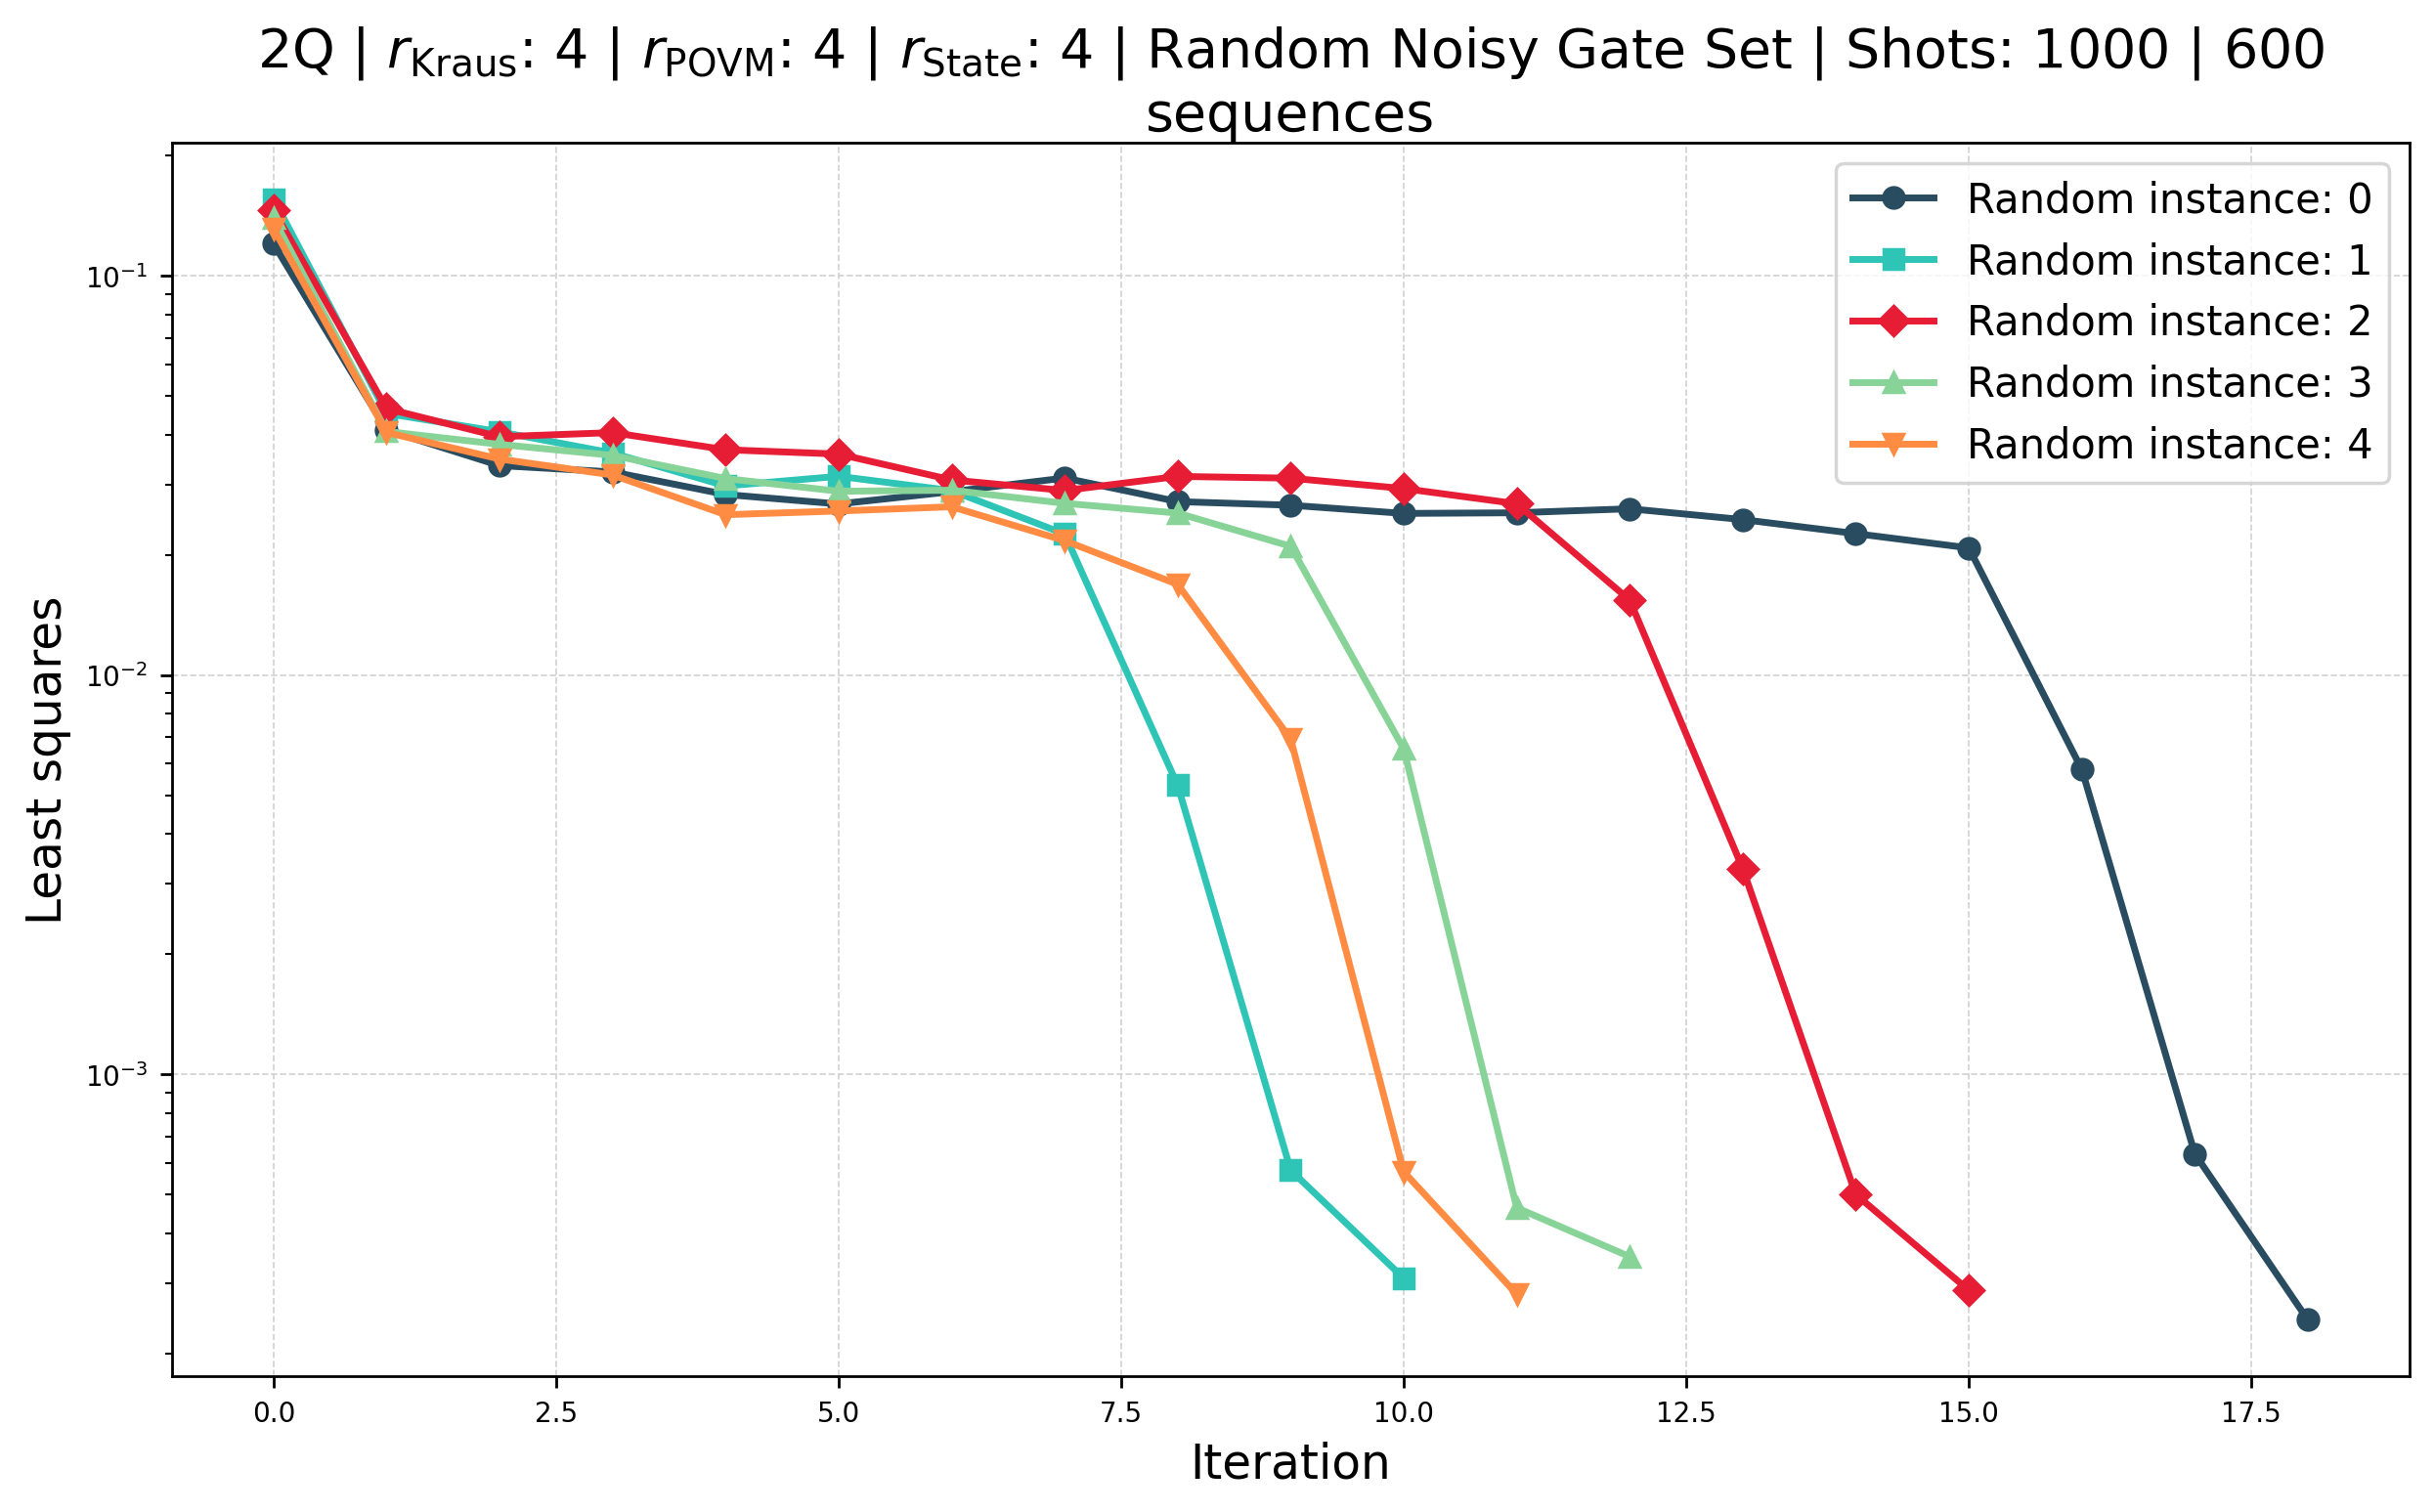

In [27]:
sequences_test = 600

final_results_test = get_all_realizations_for_key(final_results_600_650, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_600_650, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

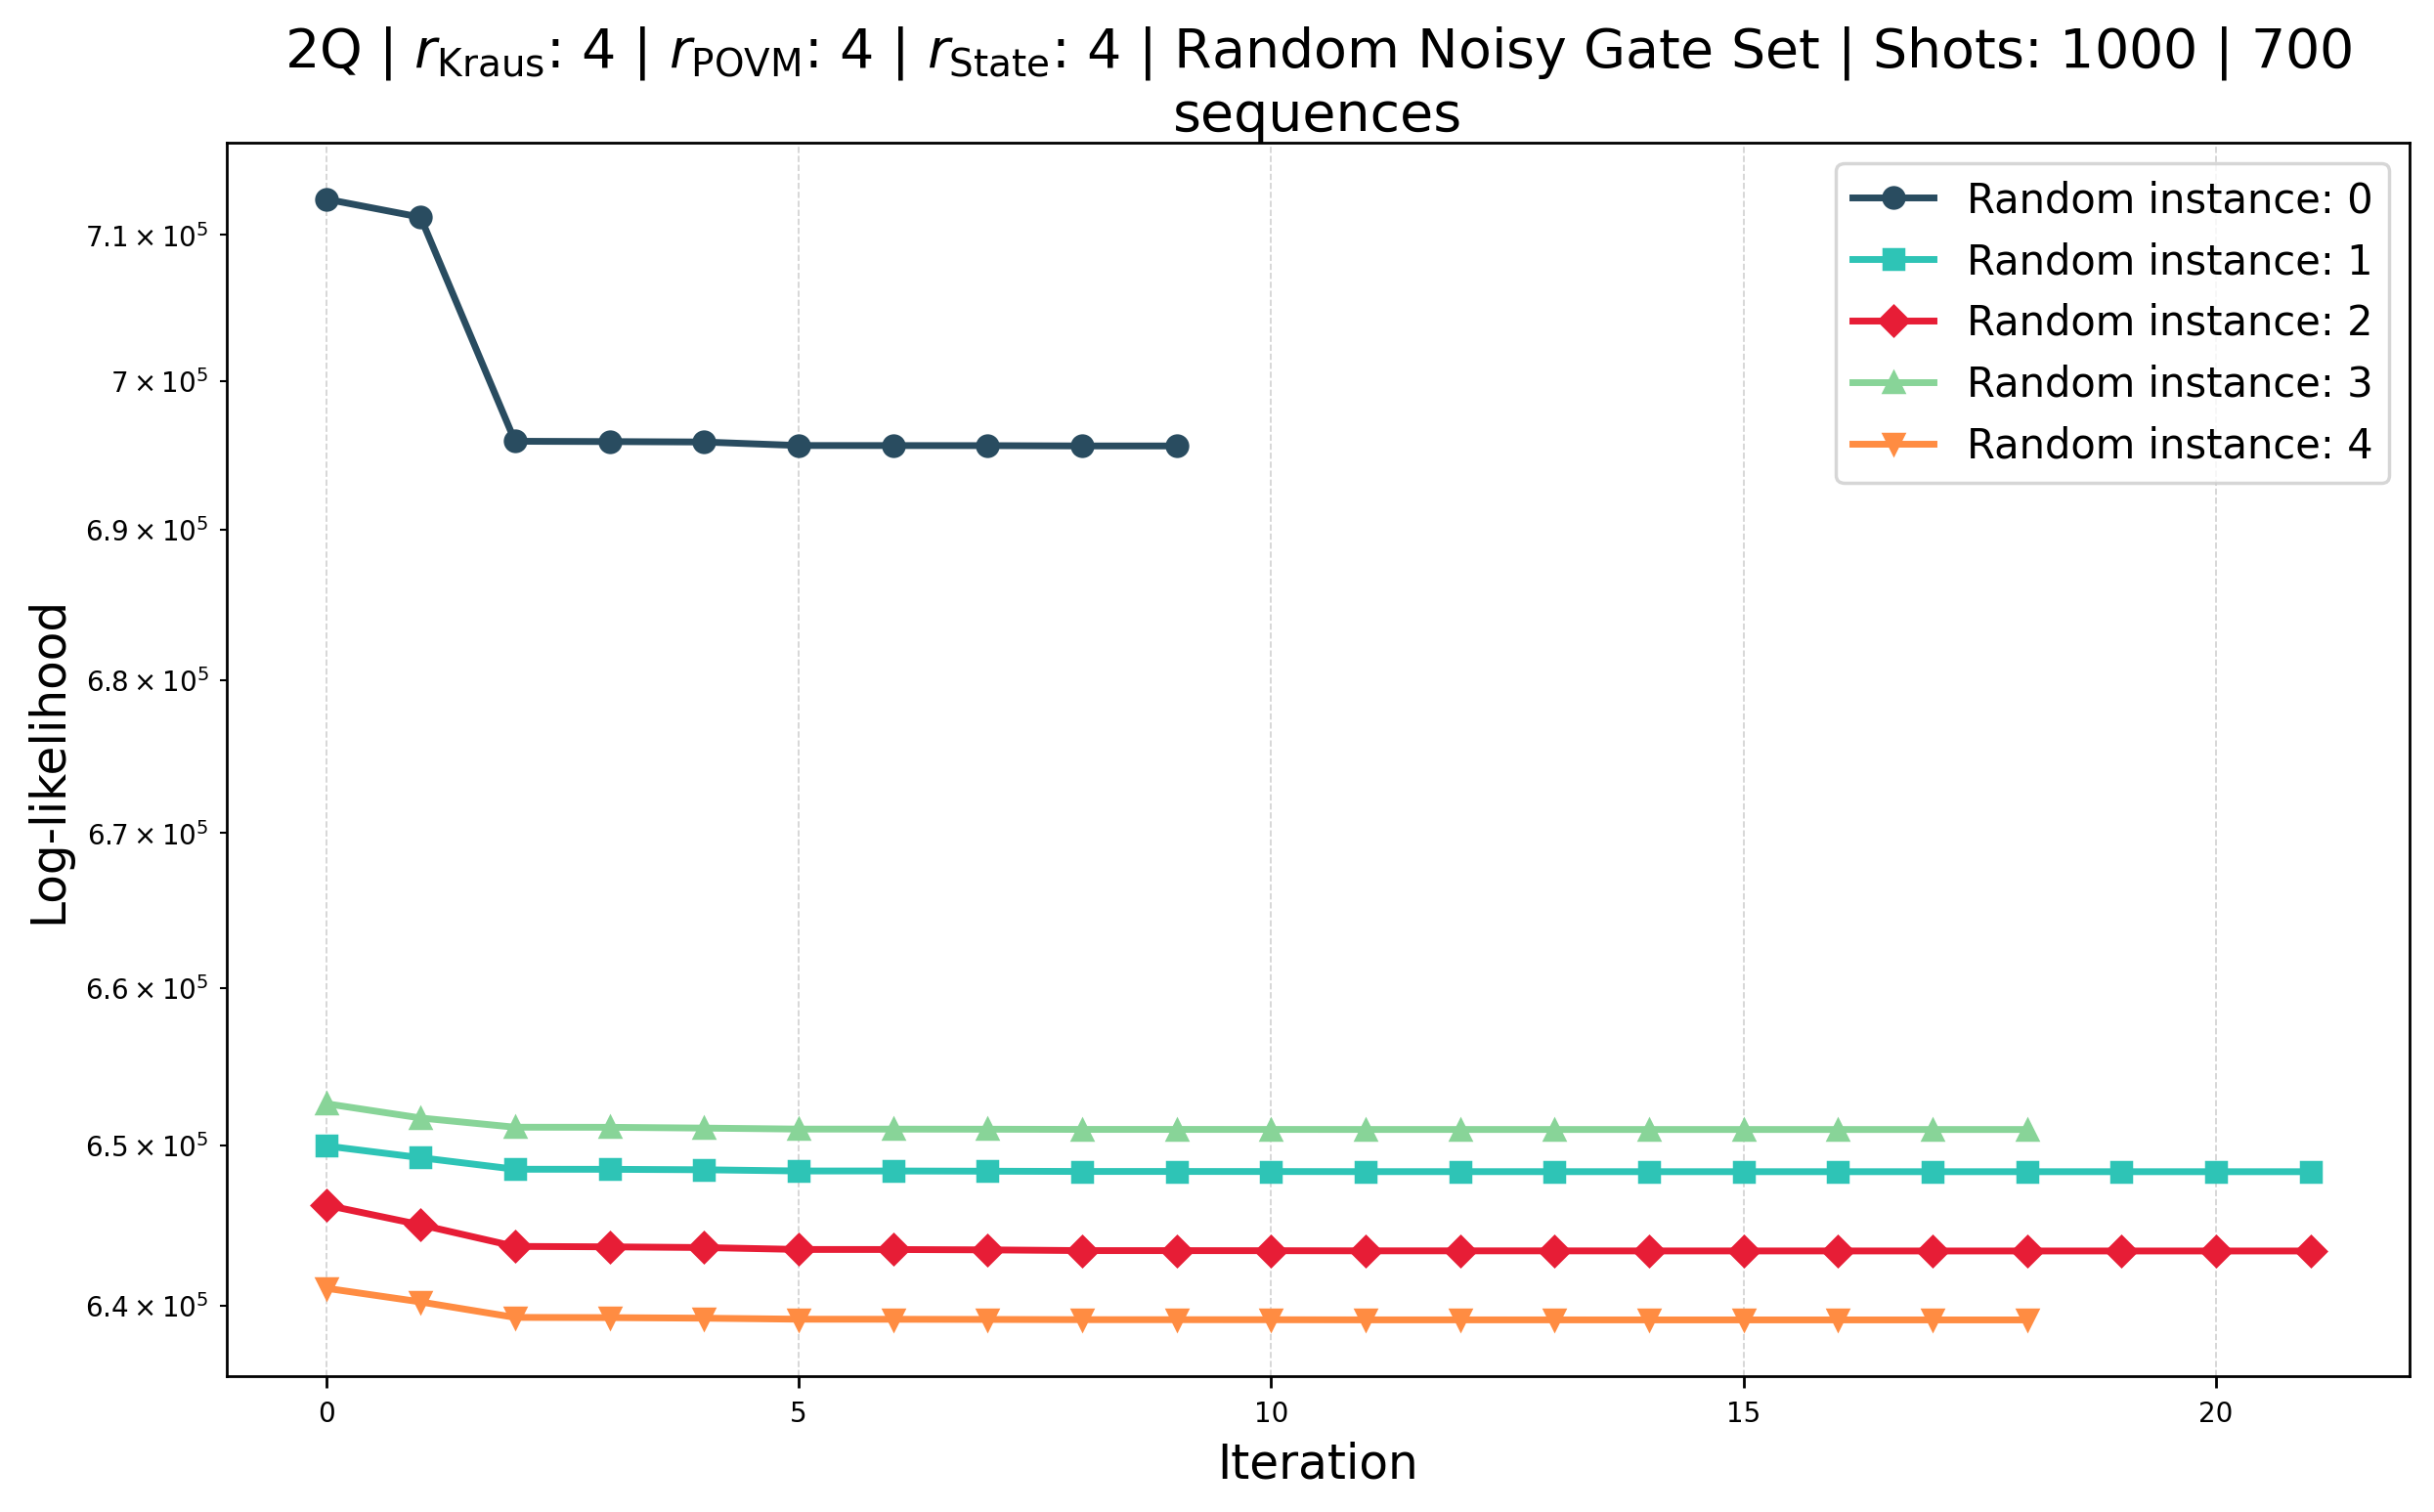

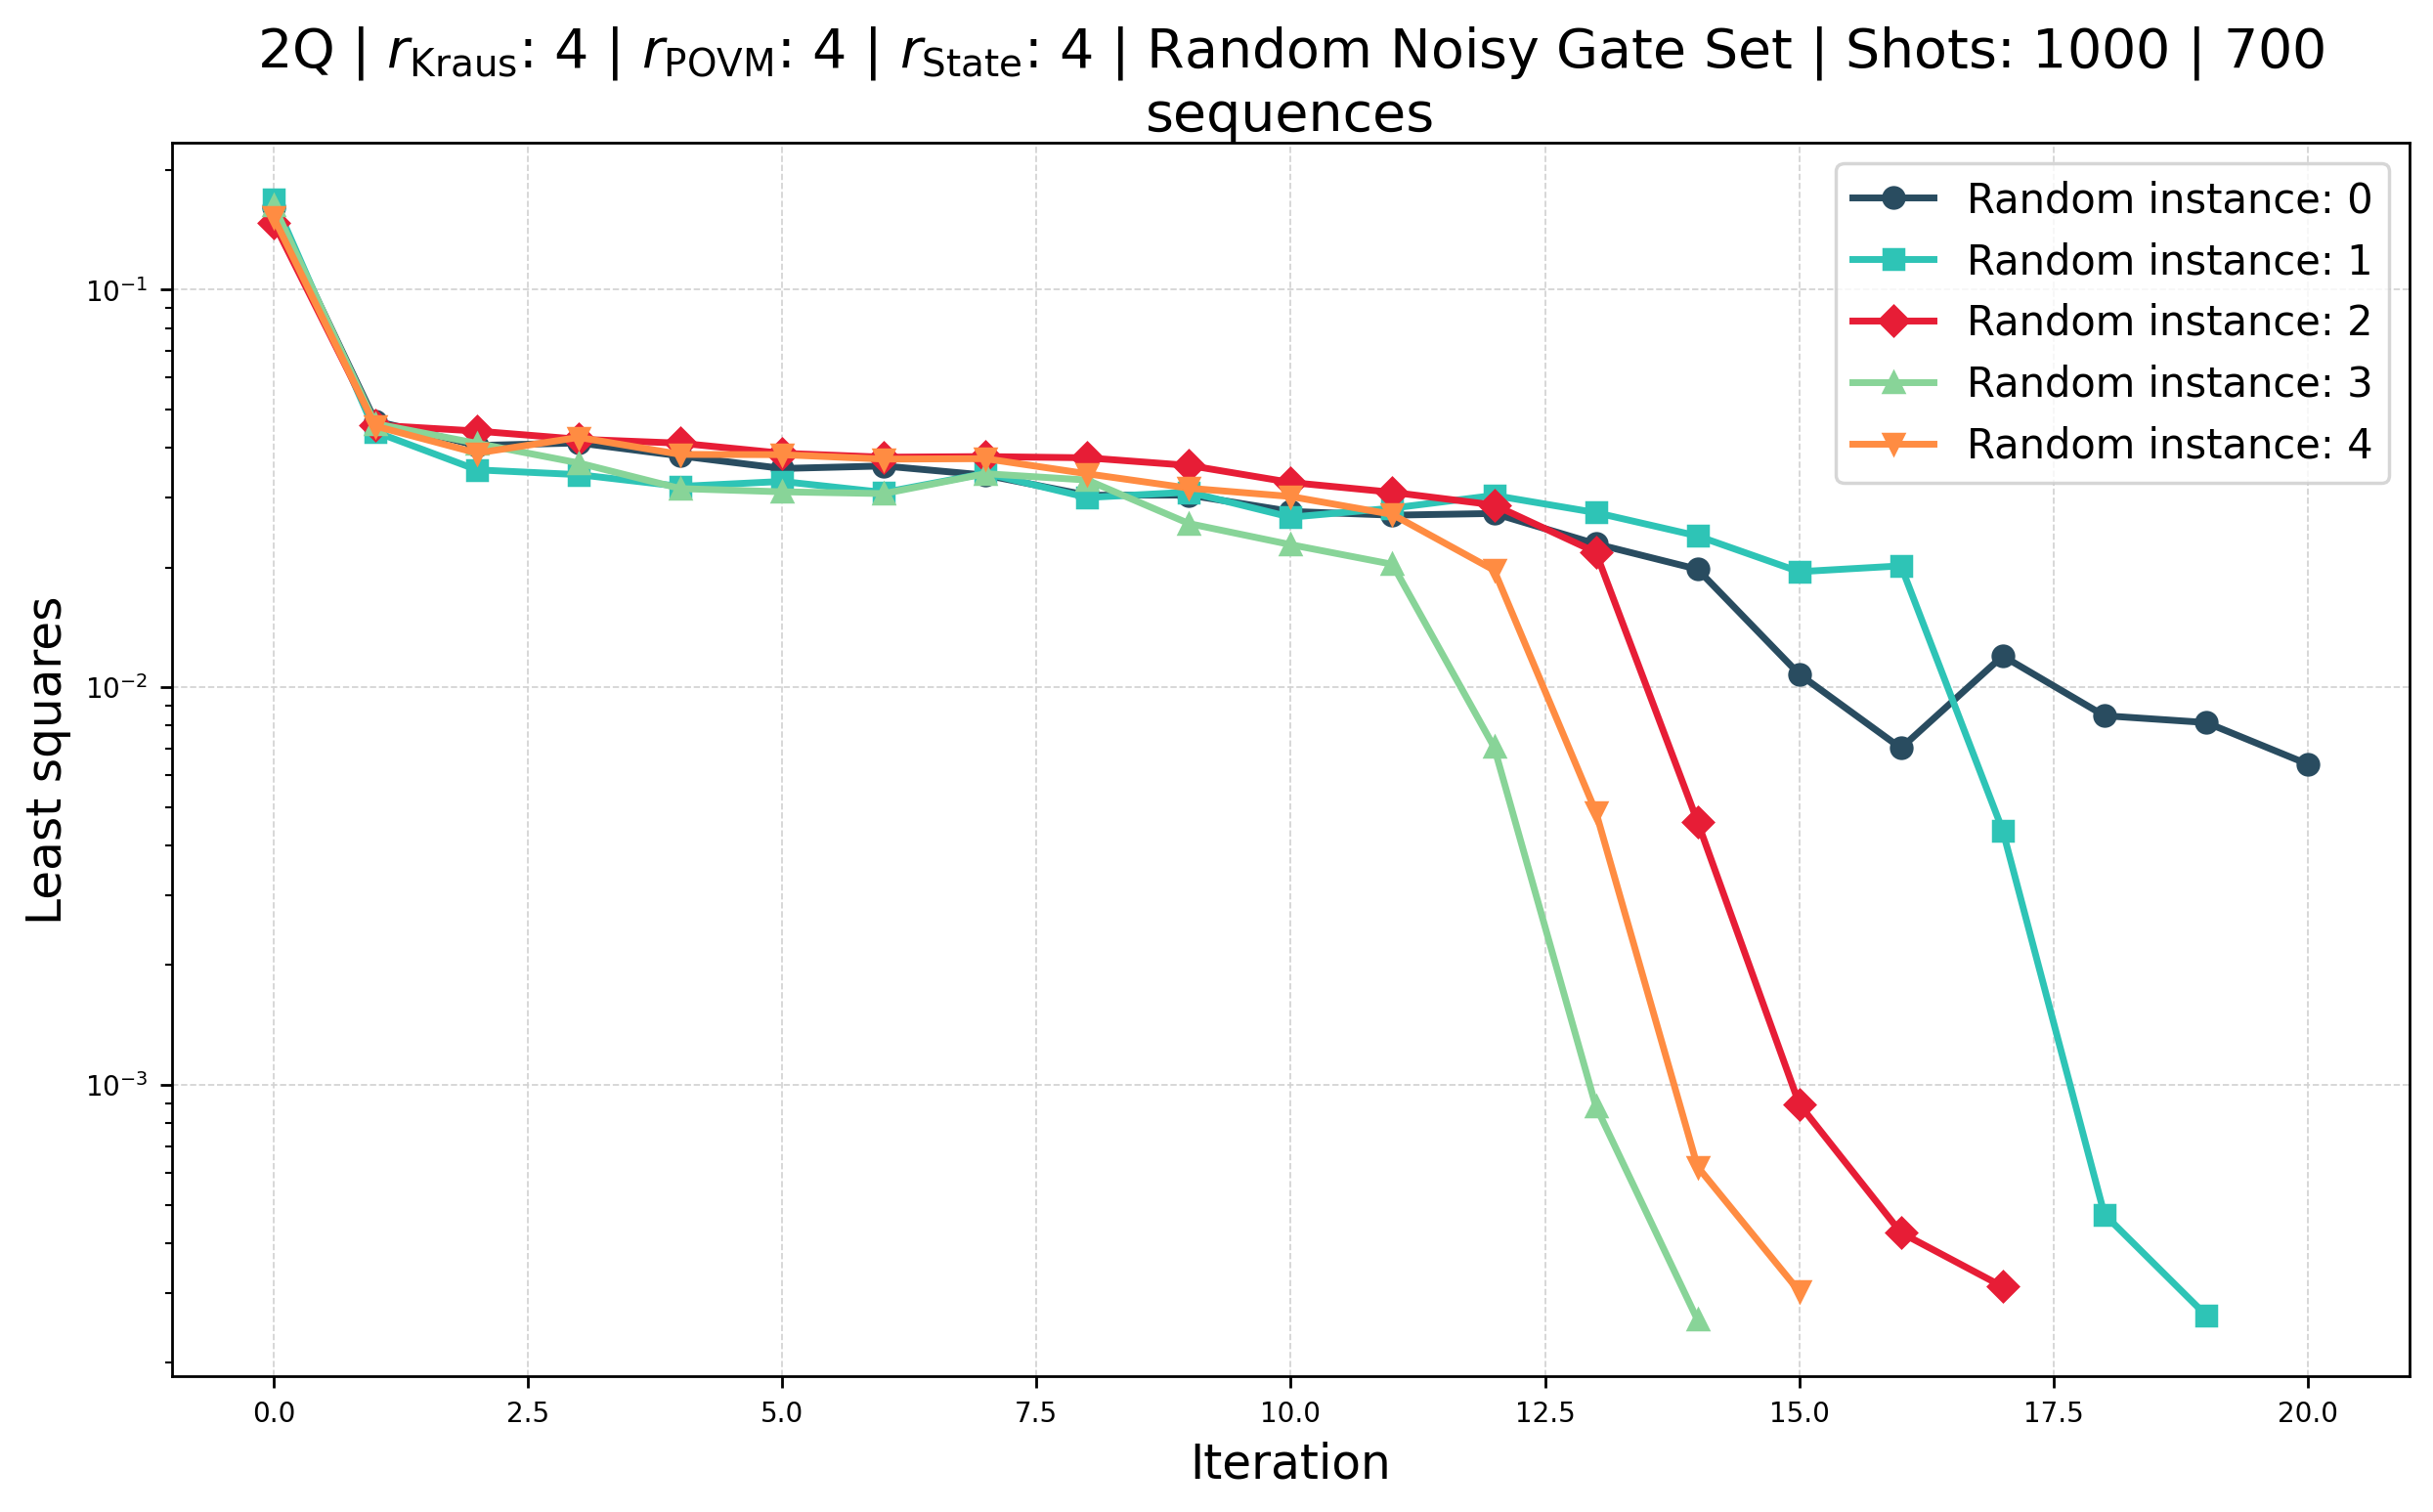

In [19]:
sequences_test = 700

final_results_test = get_all_realizations_for_key(final_results_700, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_700, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

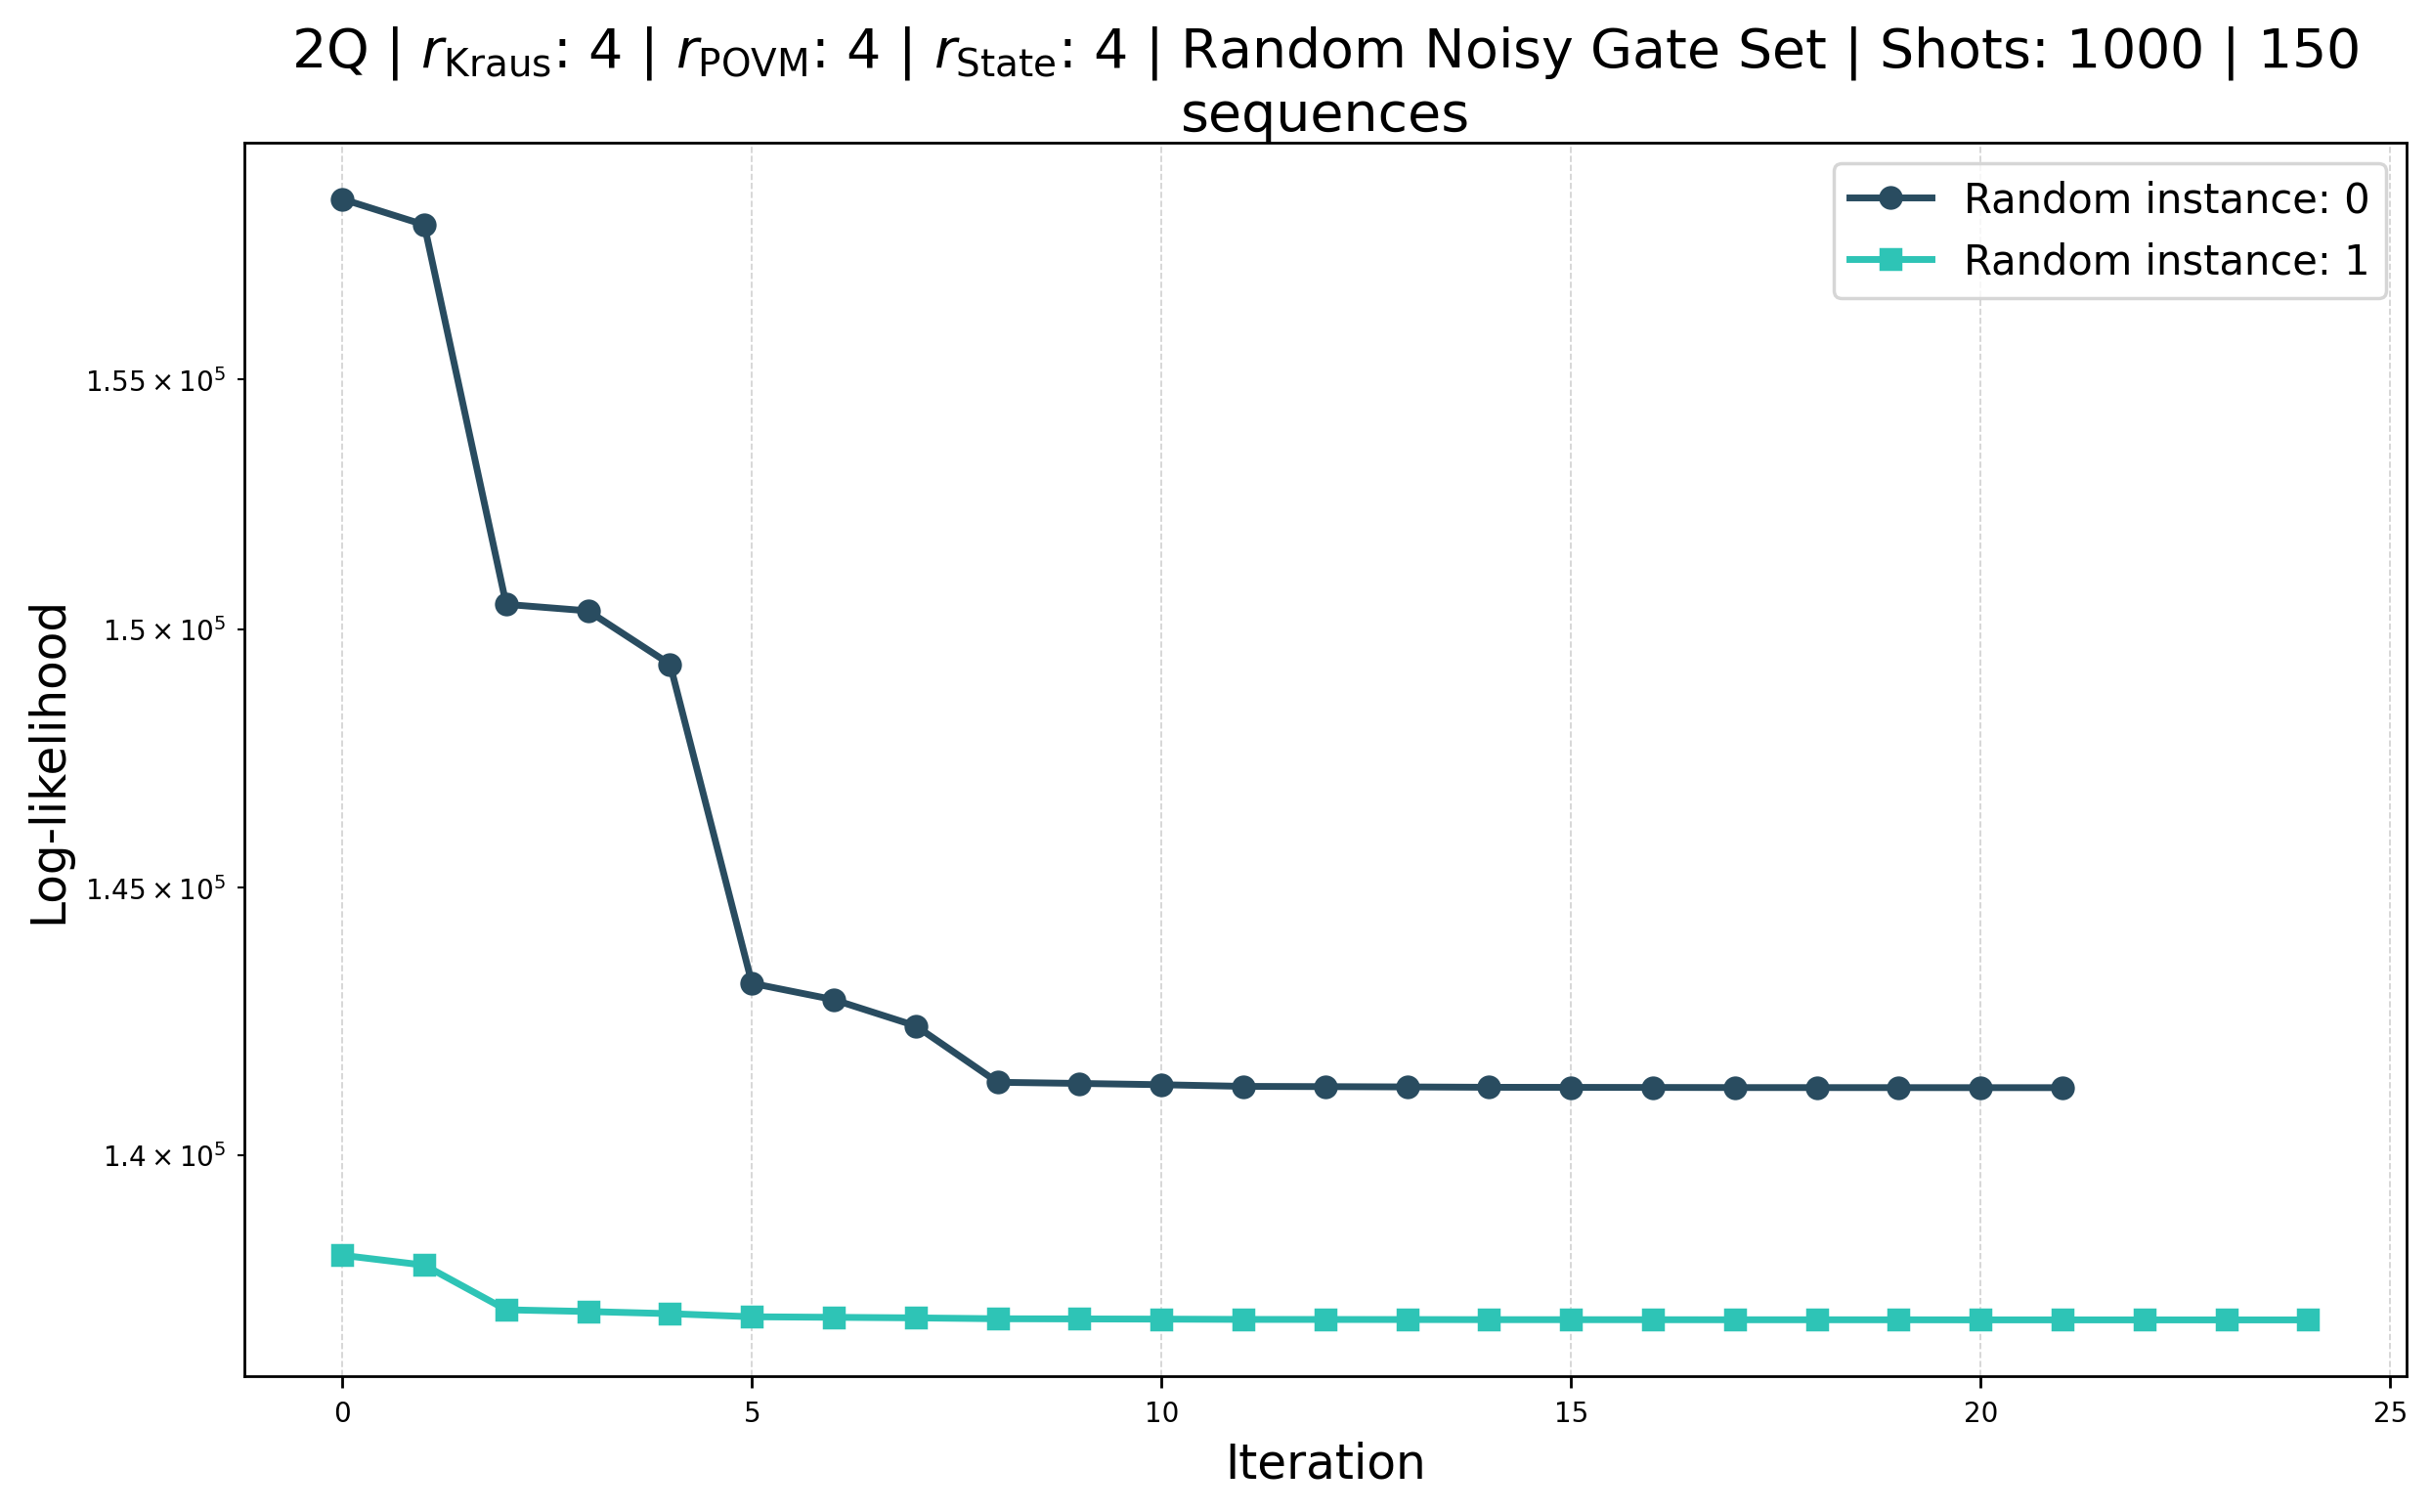

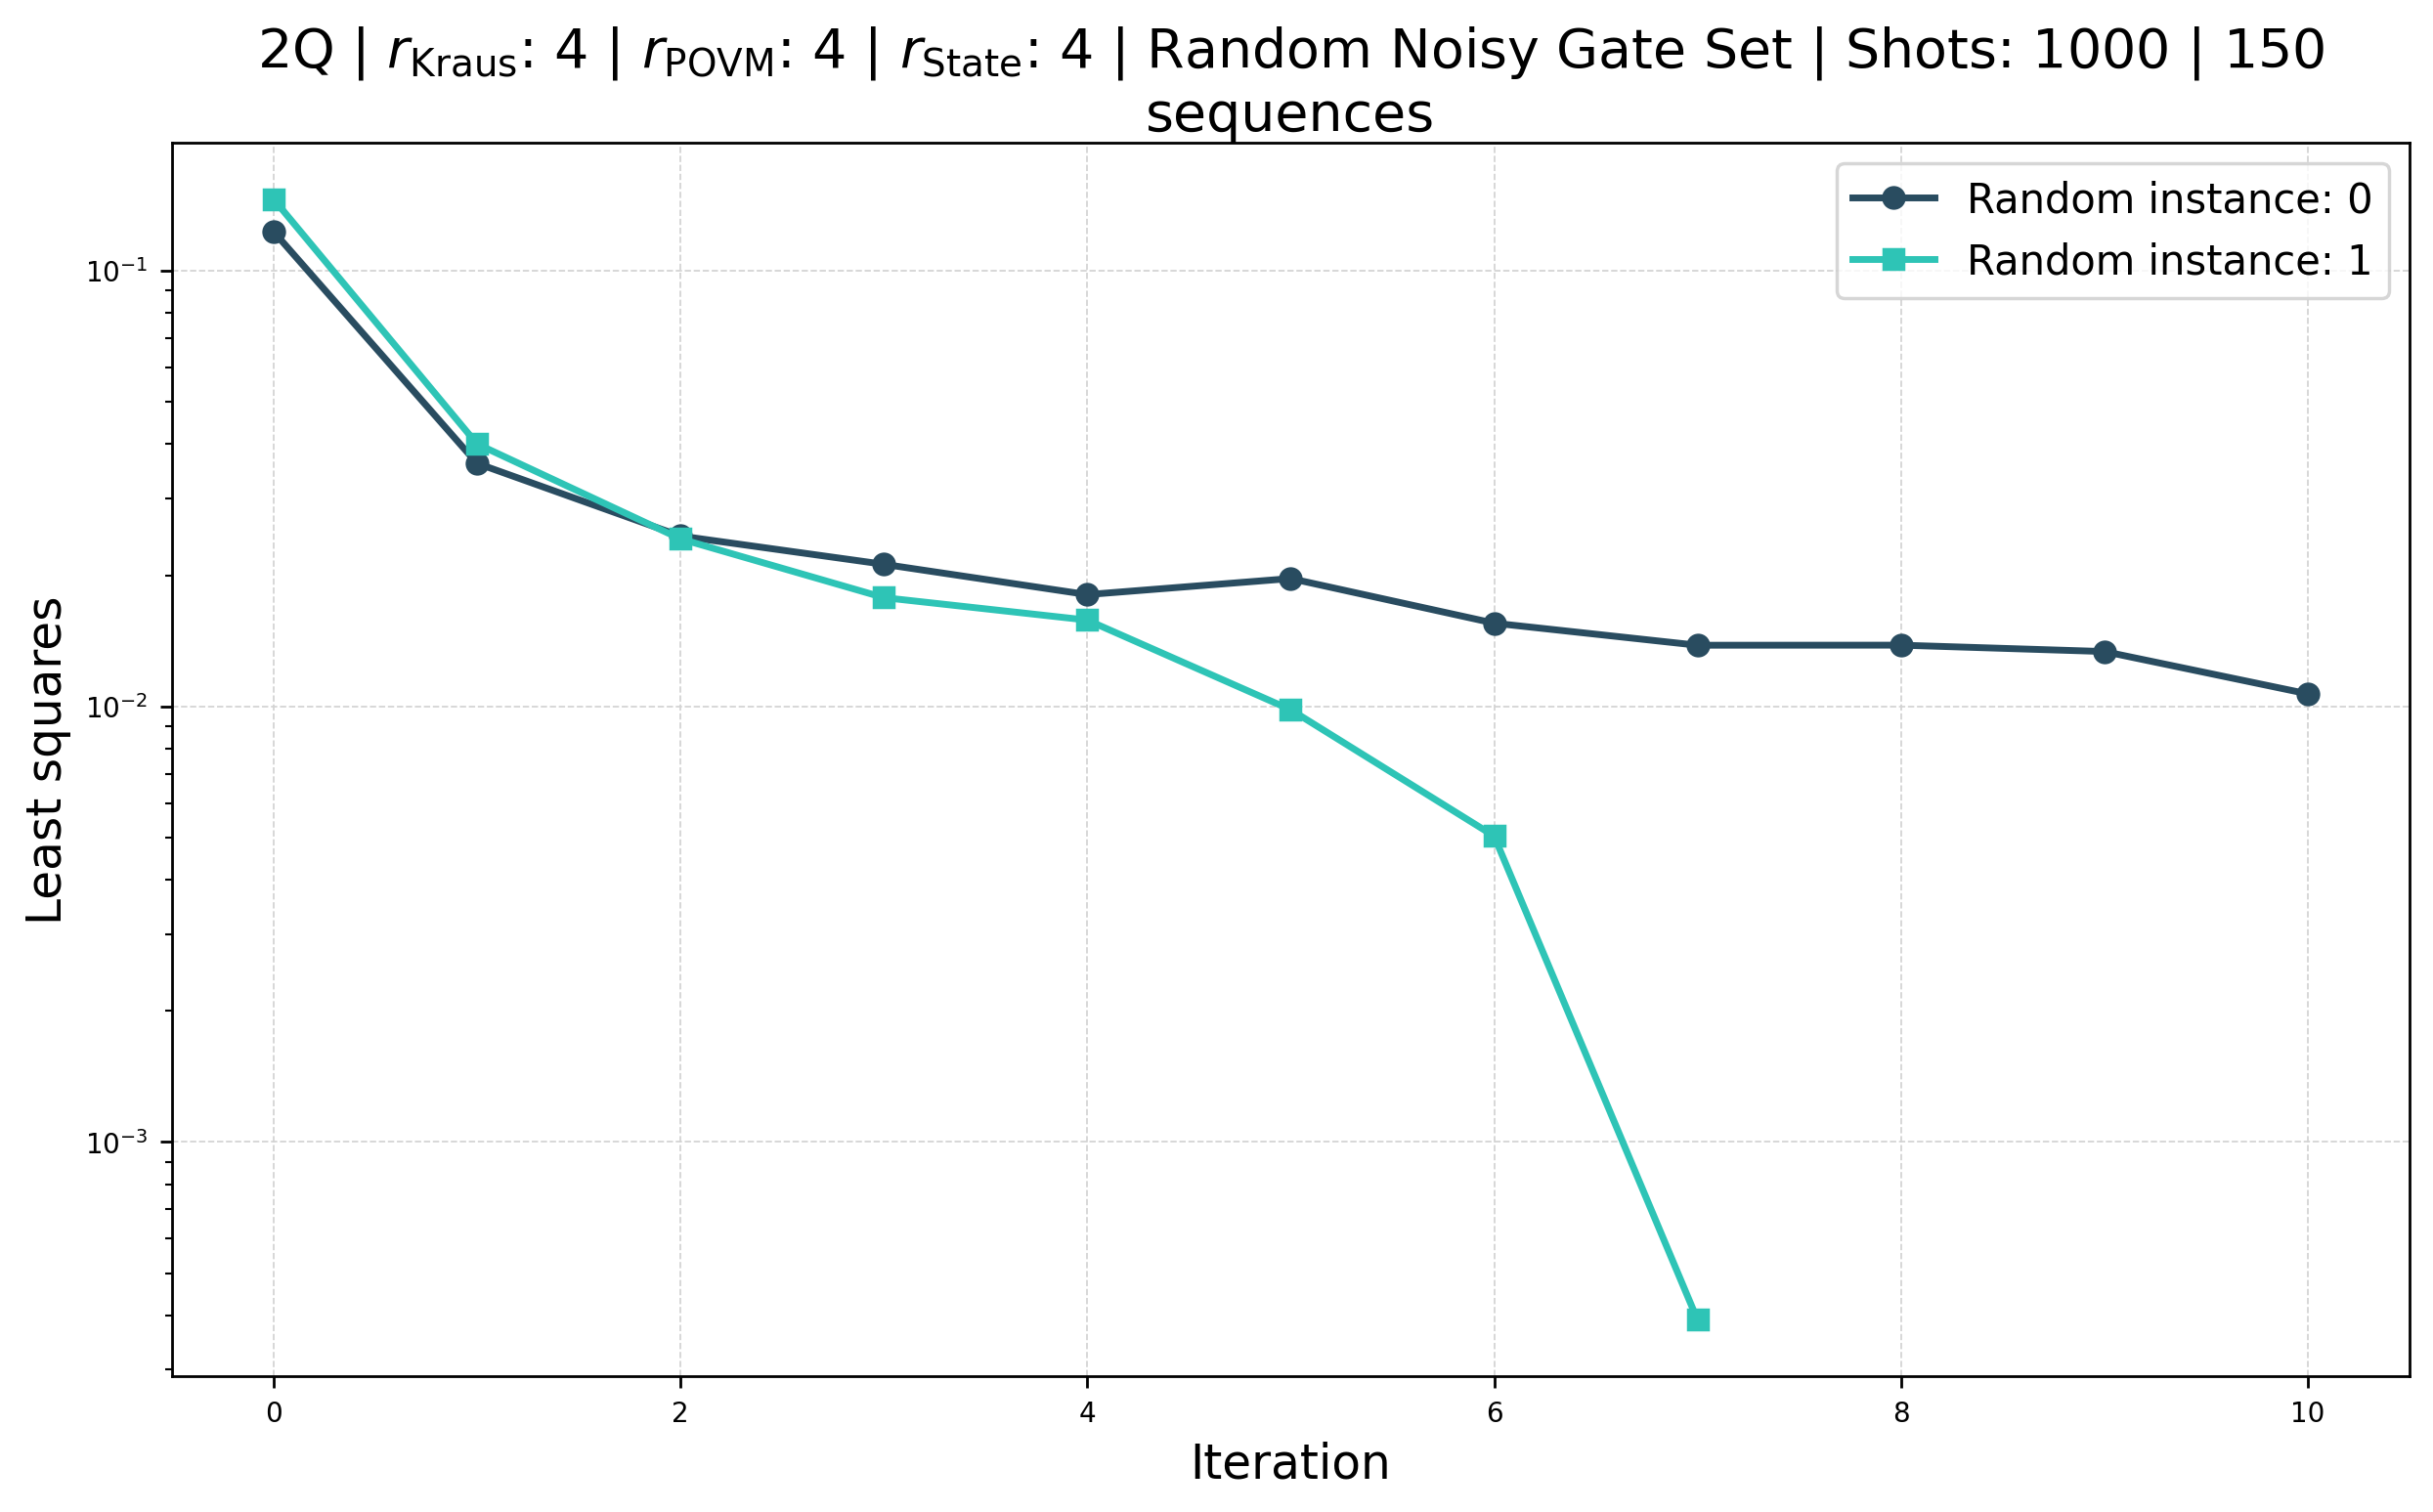

In [174]:
sequences_test = 150

final_results_test = get_all_realizations_for_key(final_results_0, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_0, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

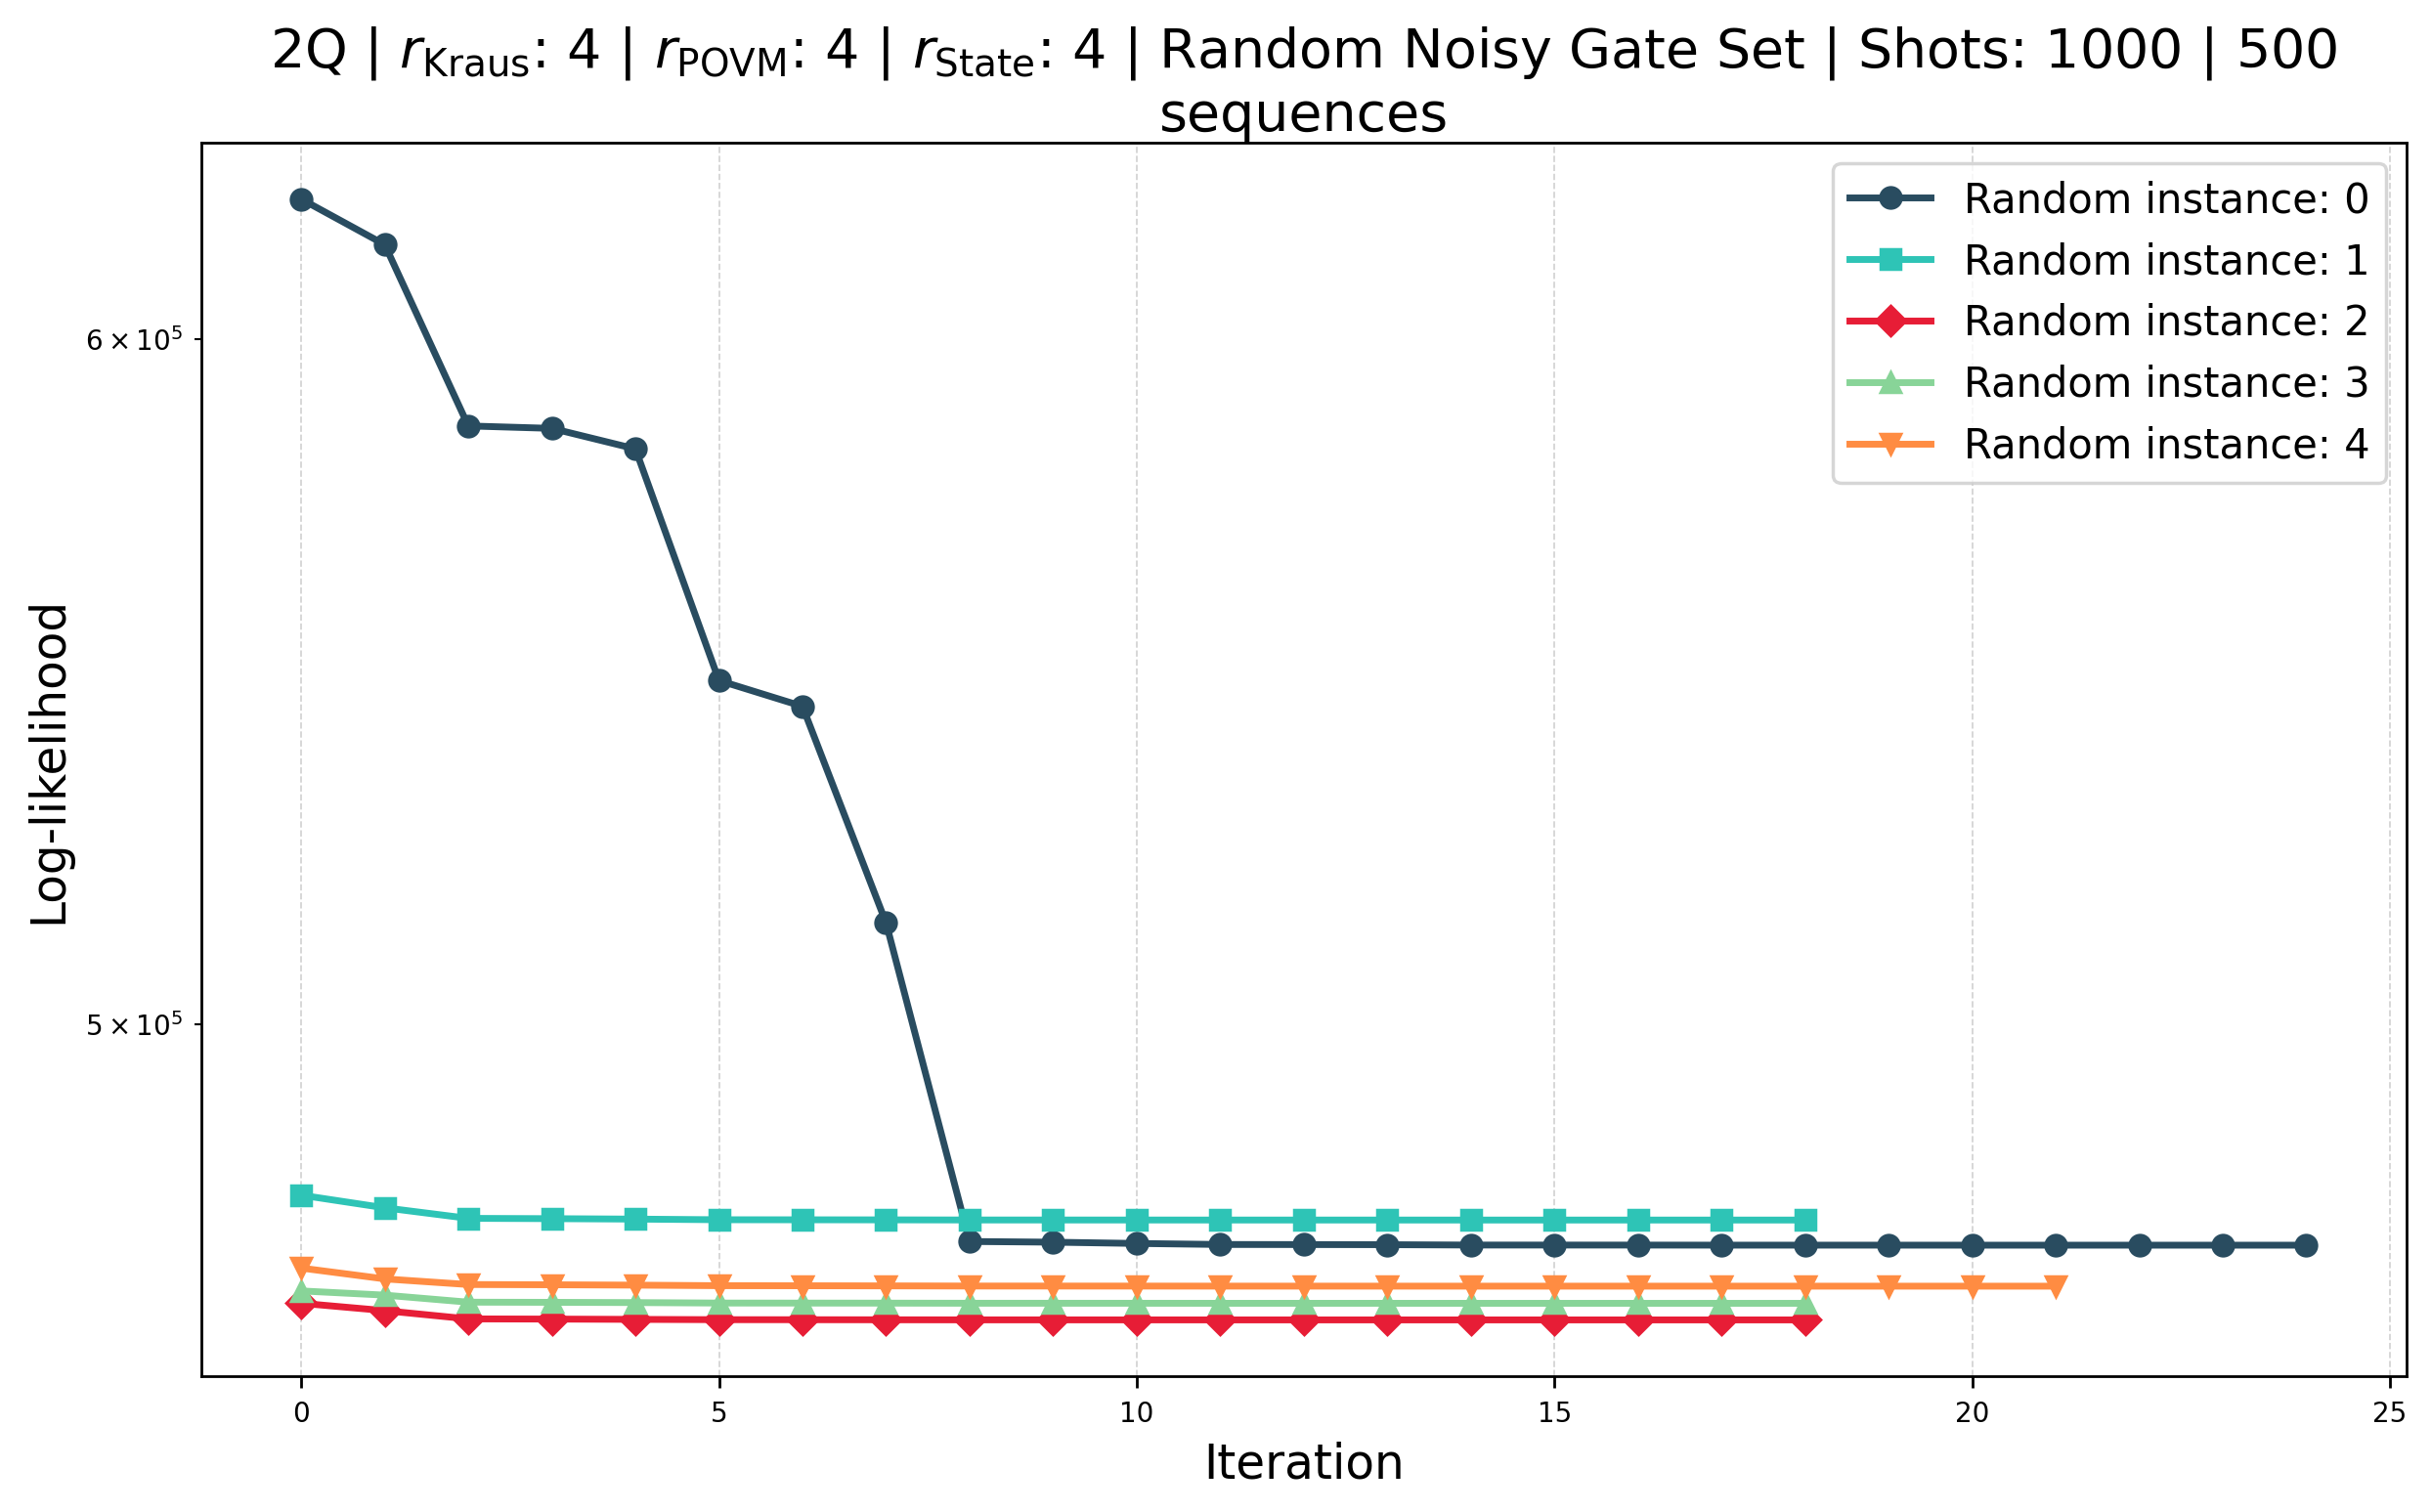

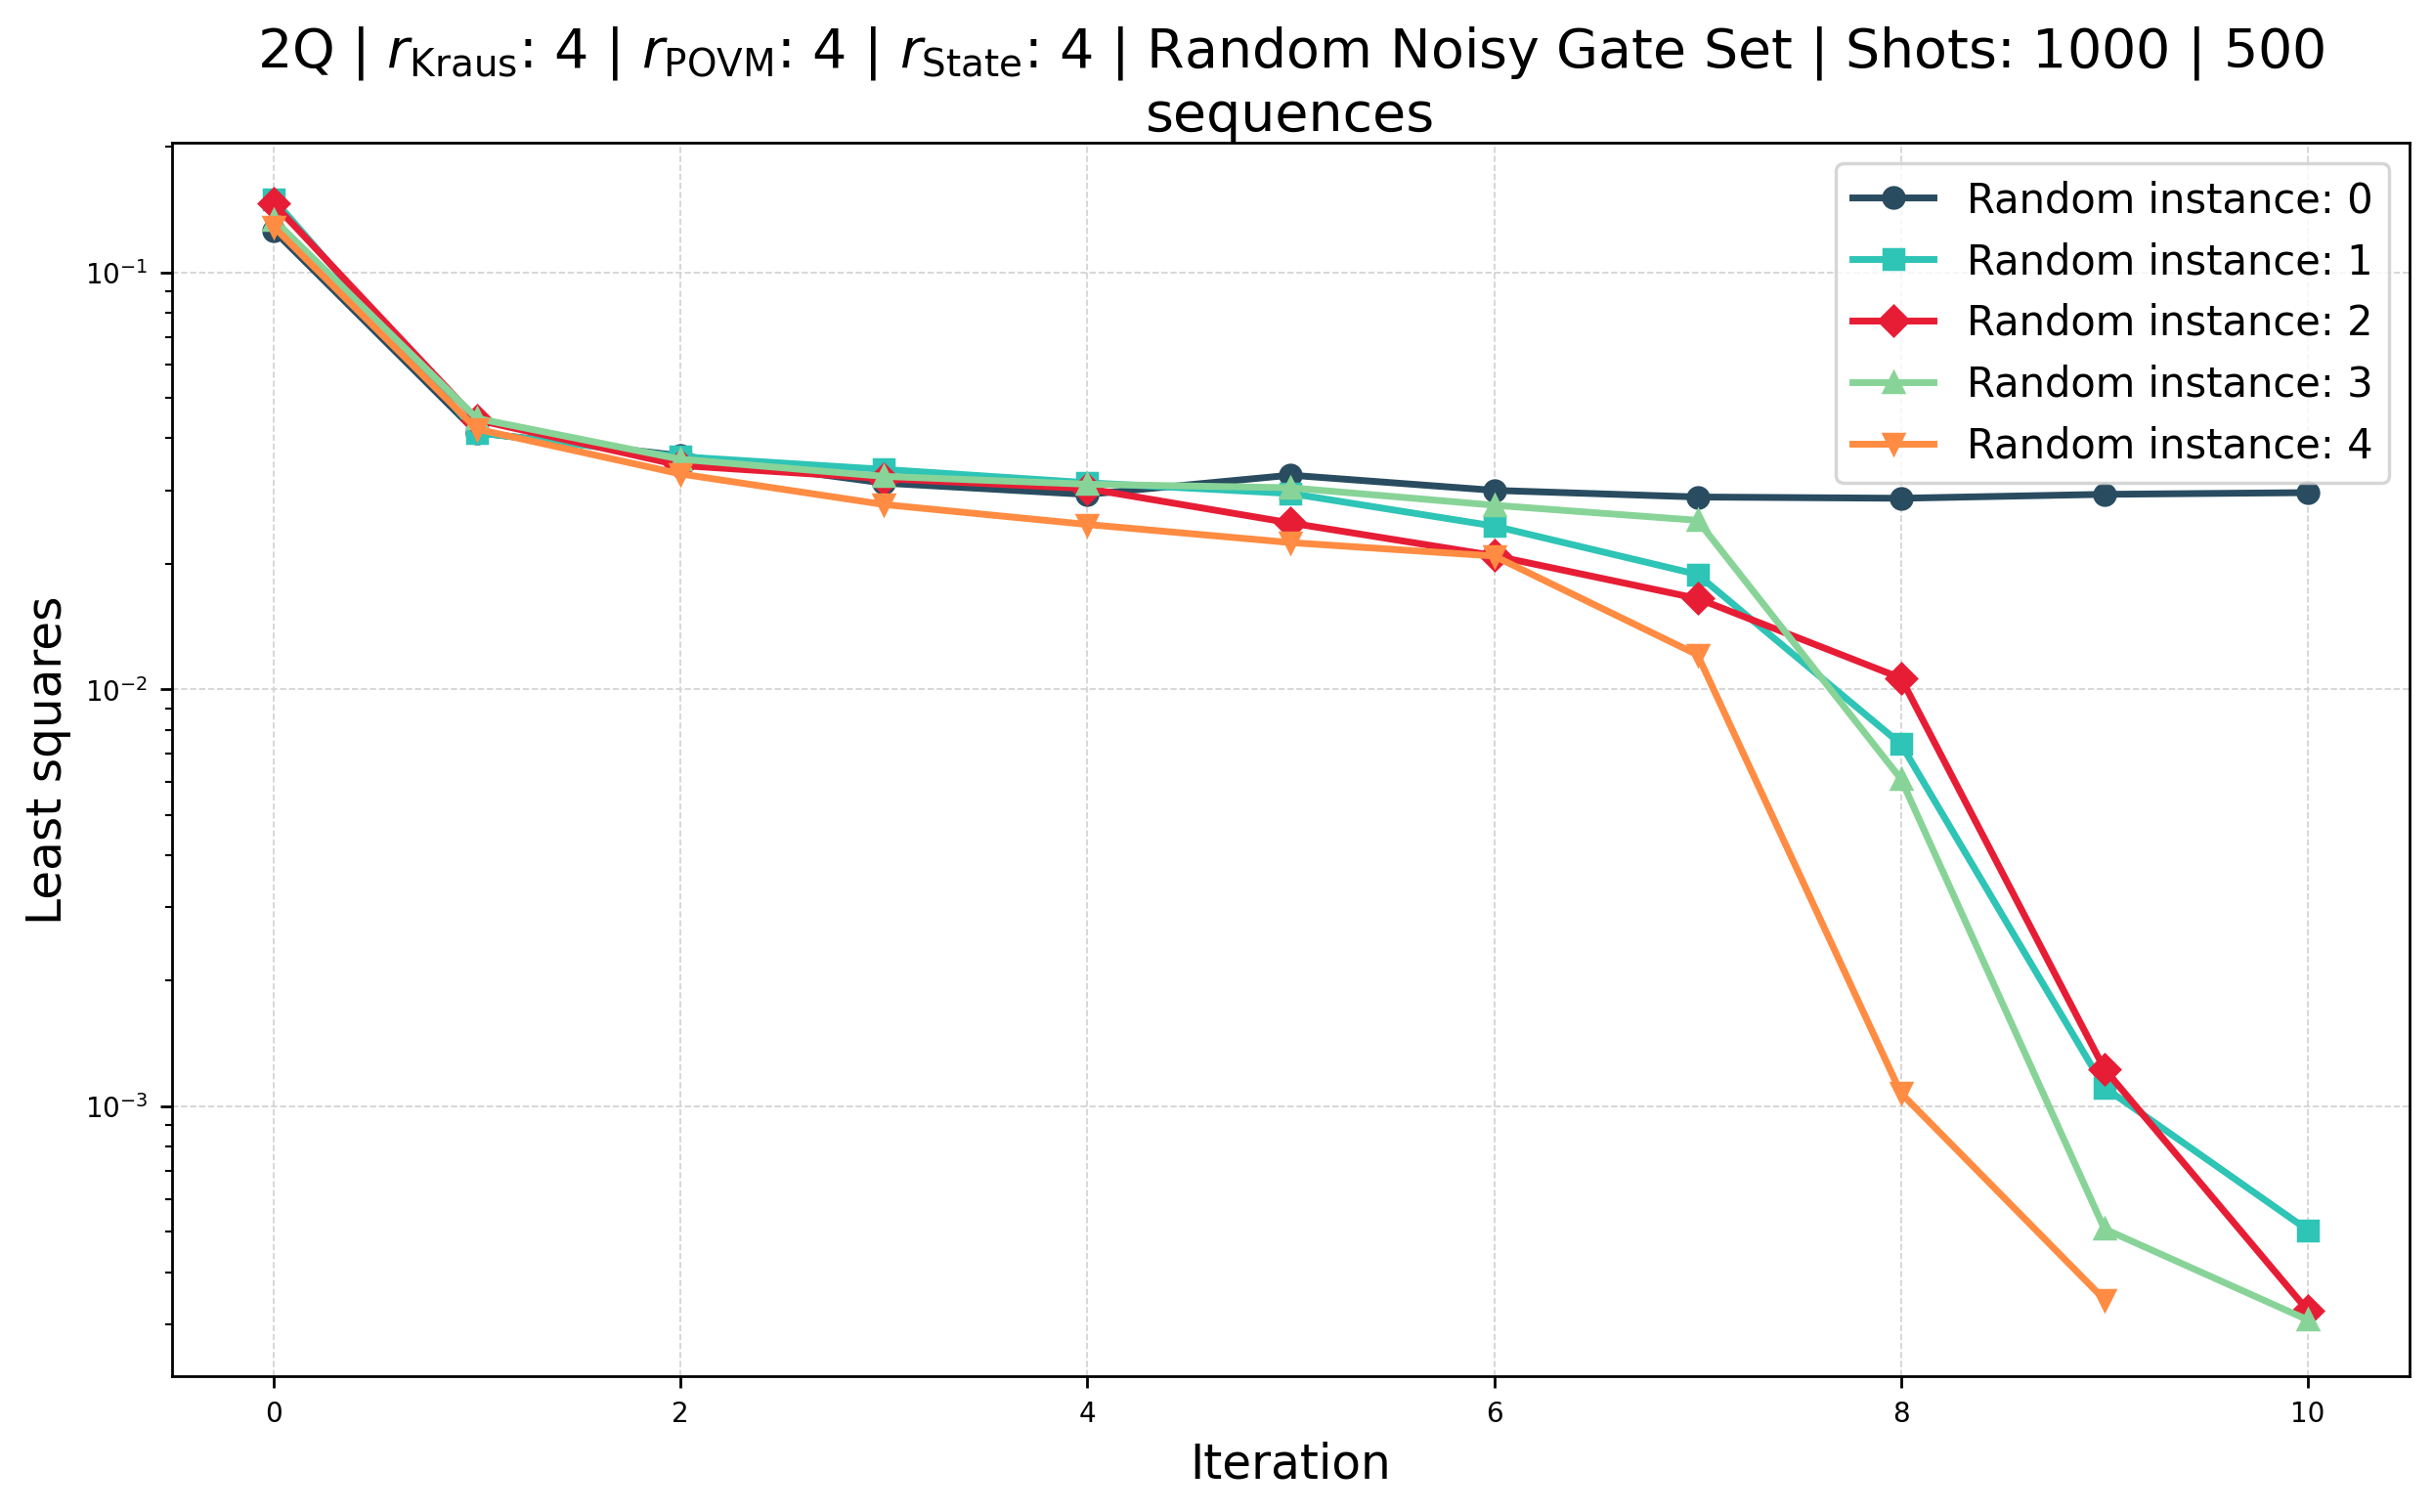

In [176]:
sequences_test = 500

final_results_test = get_all_realizations_for_key(final_results_2, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_2, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

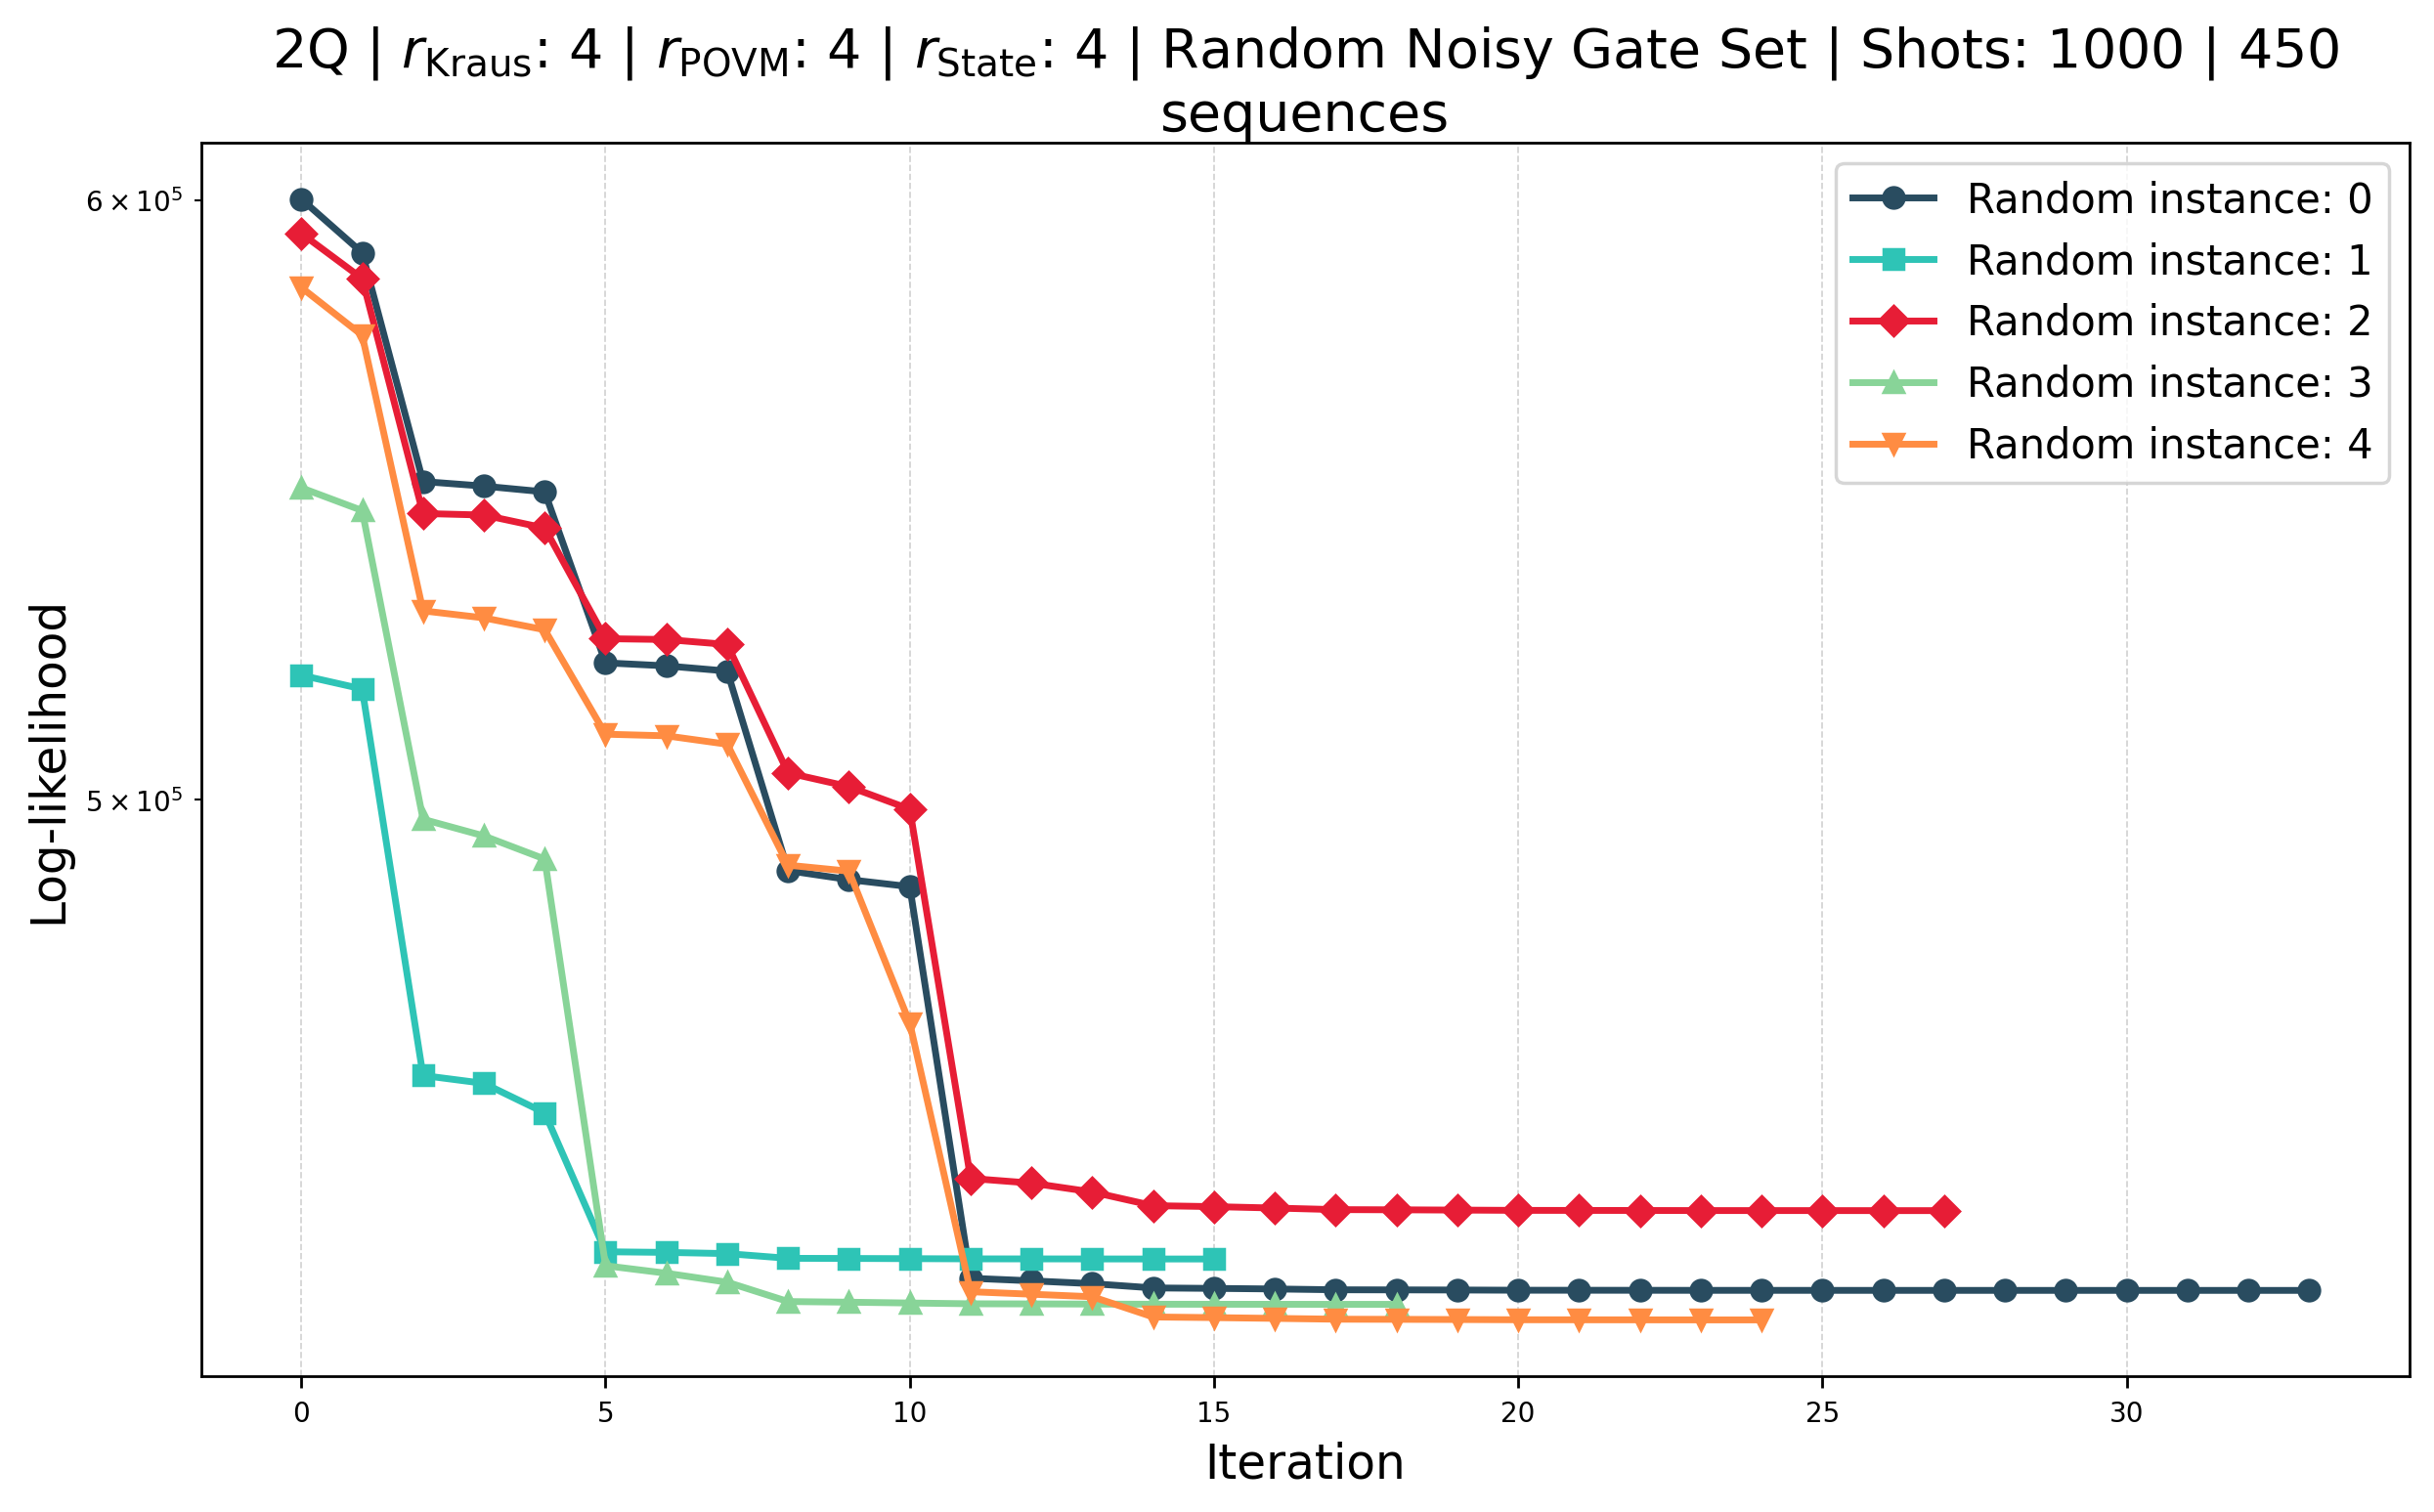

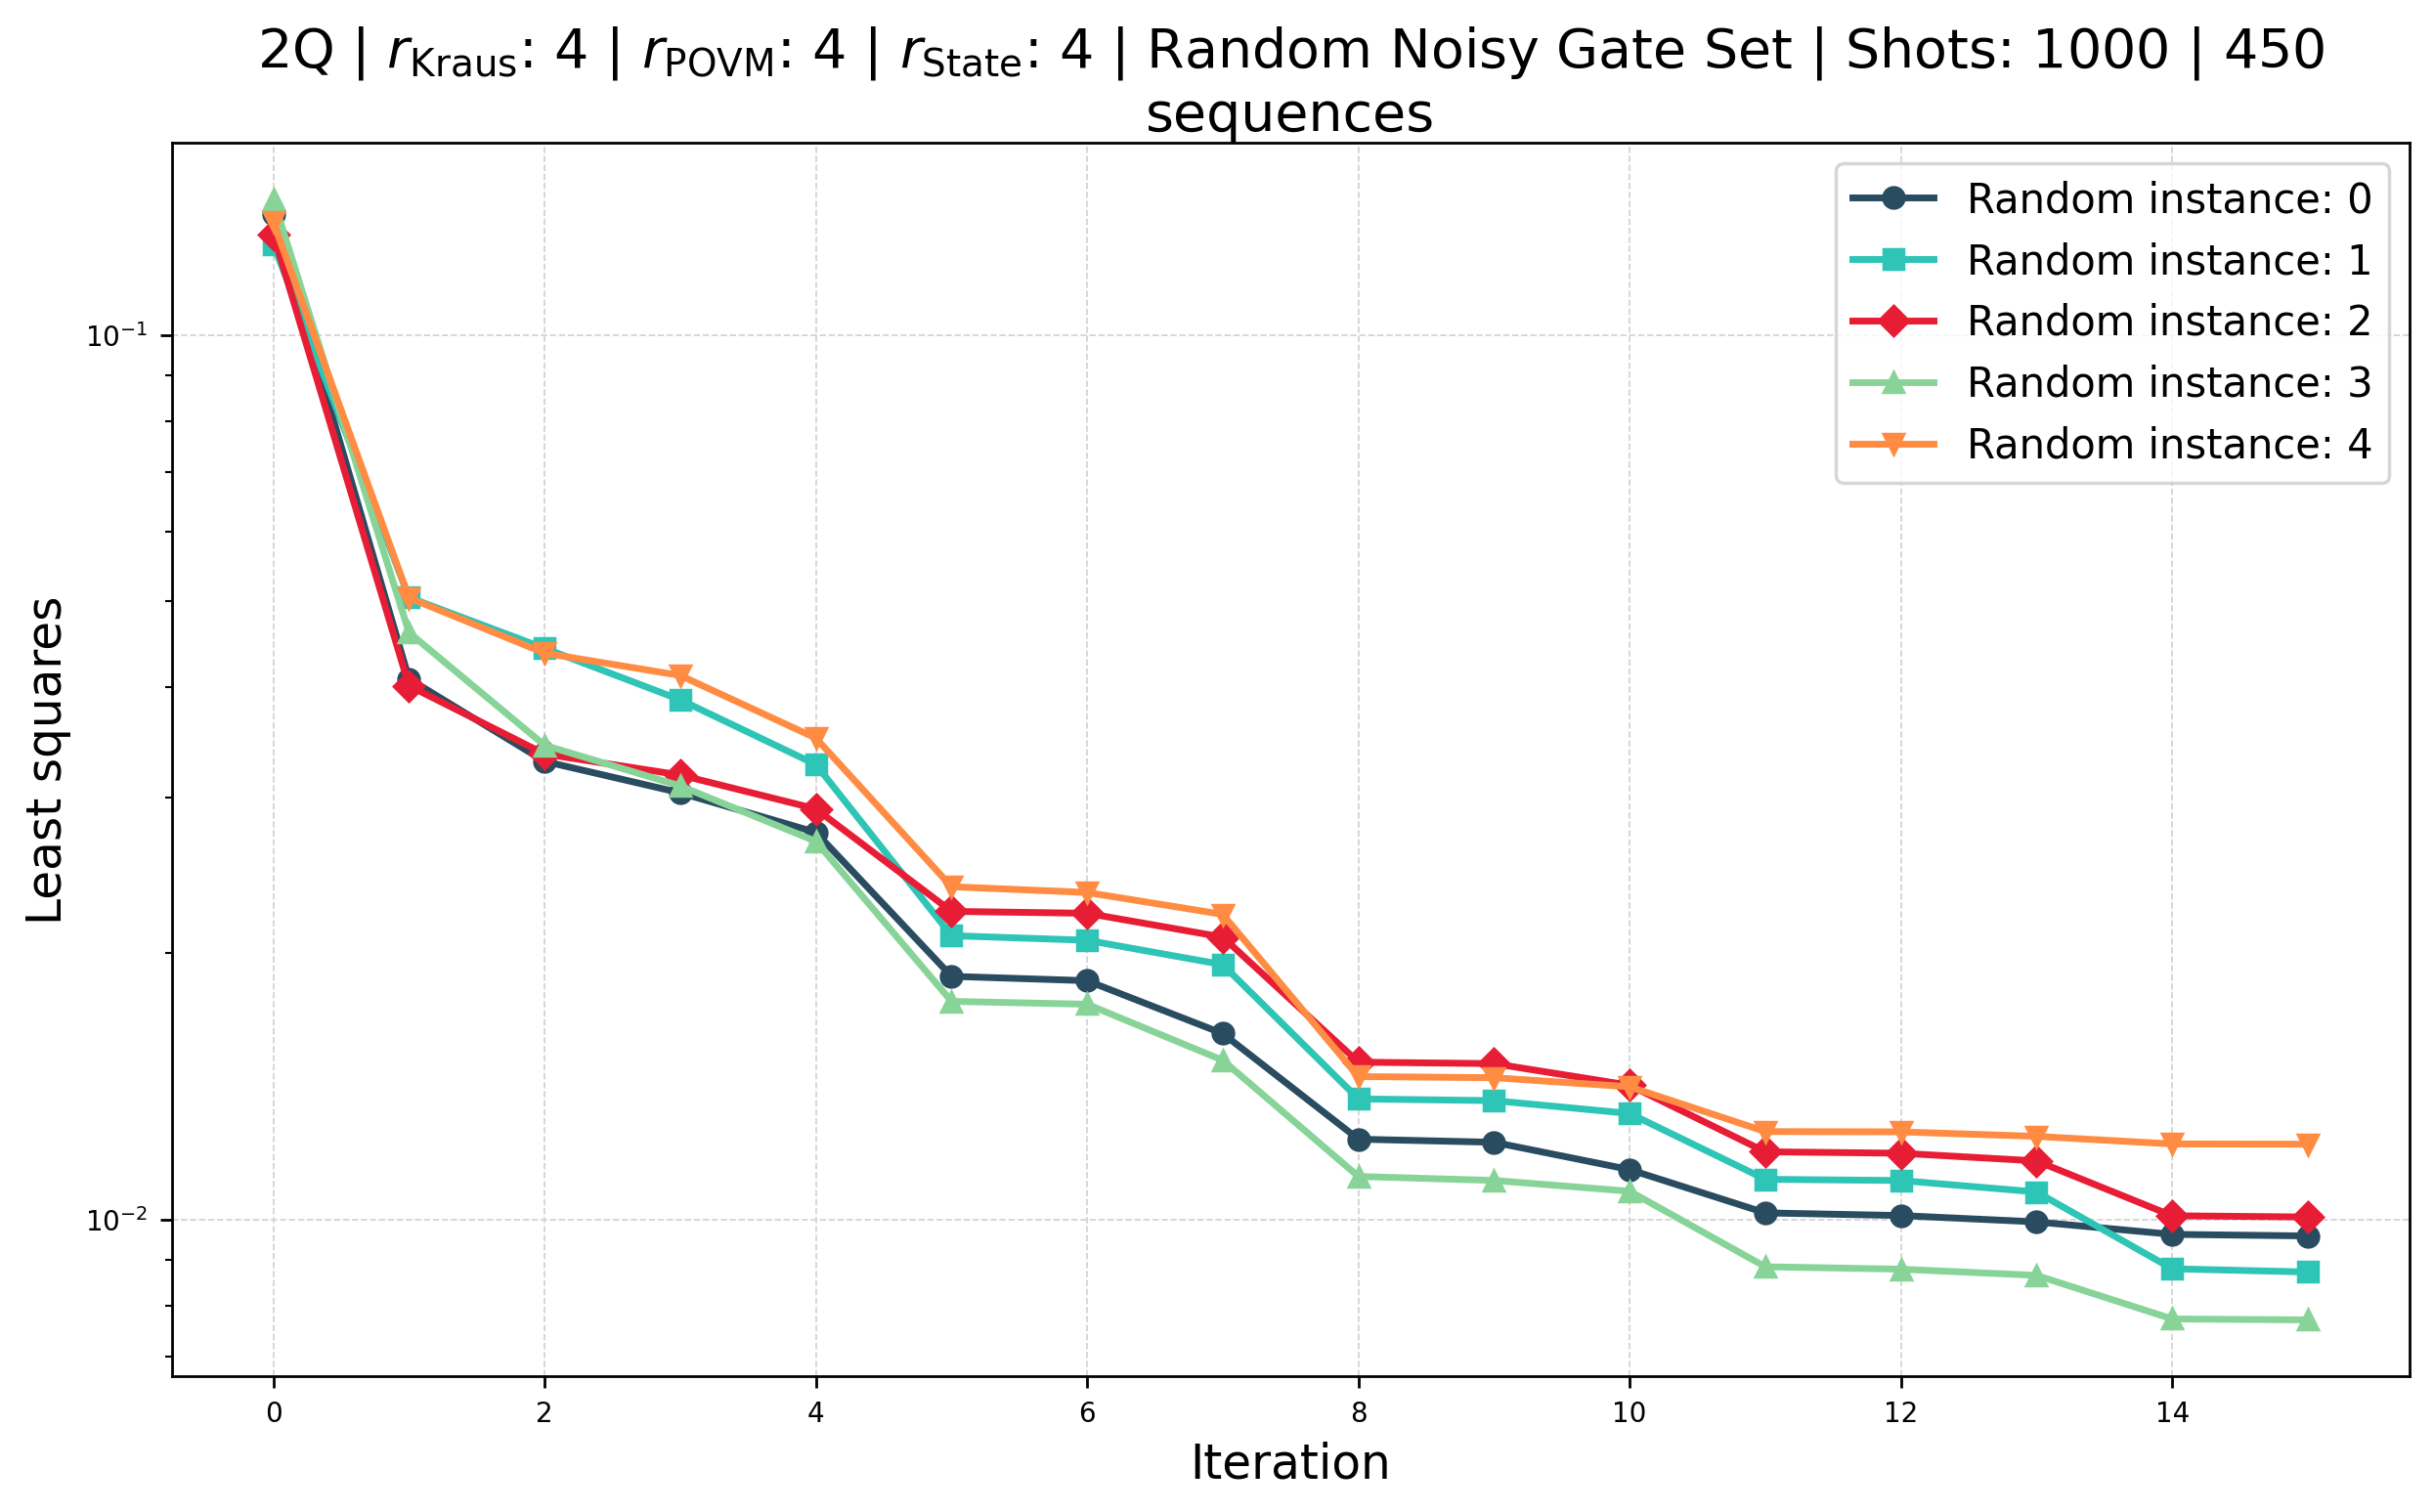

In [48]:
sequences_test = 450

final_results_test = get_all_realizations_for_key(final_results_2, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_2, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

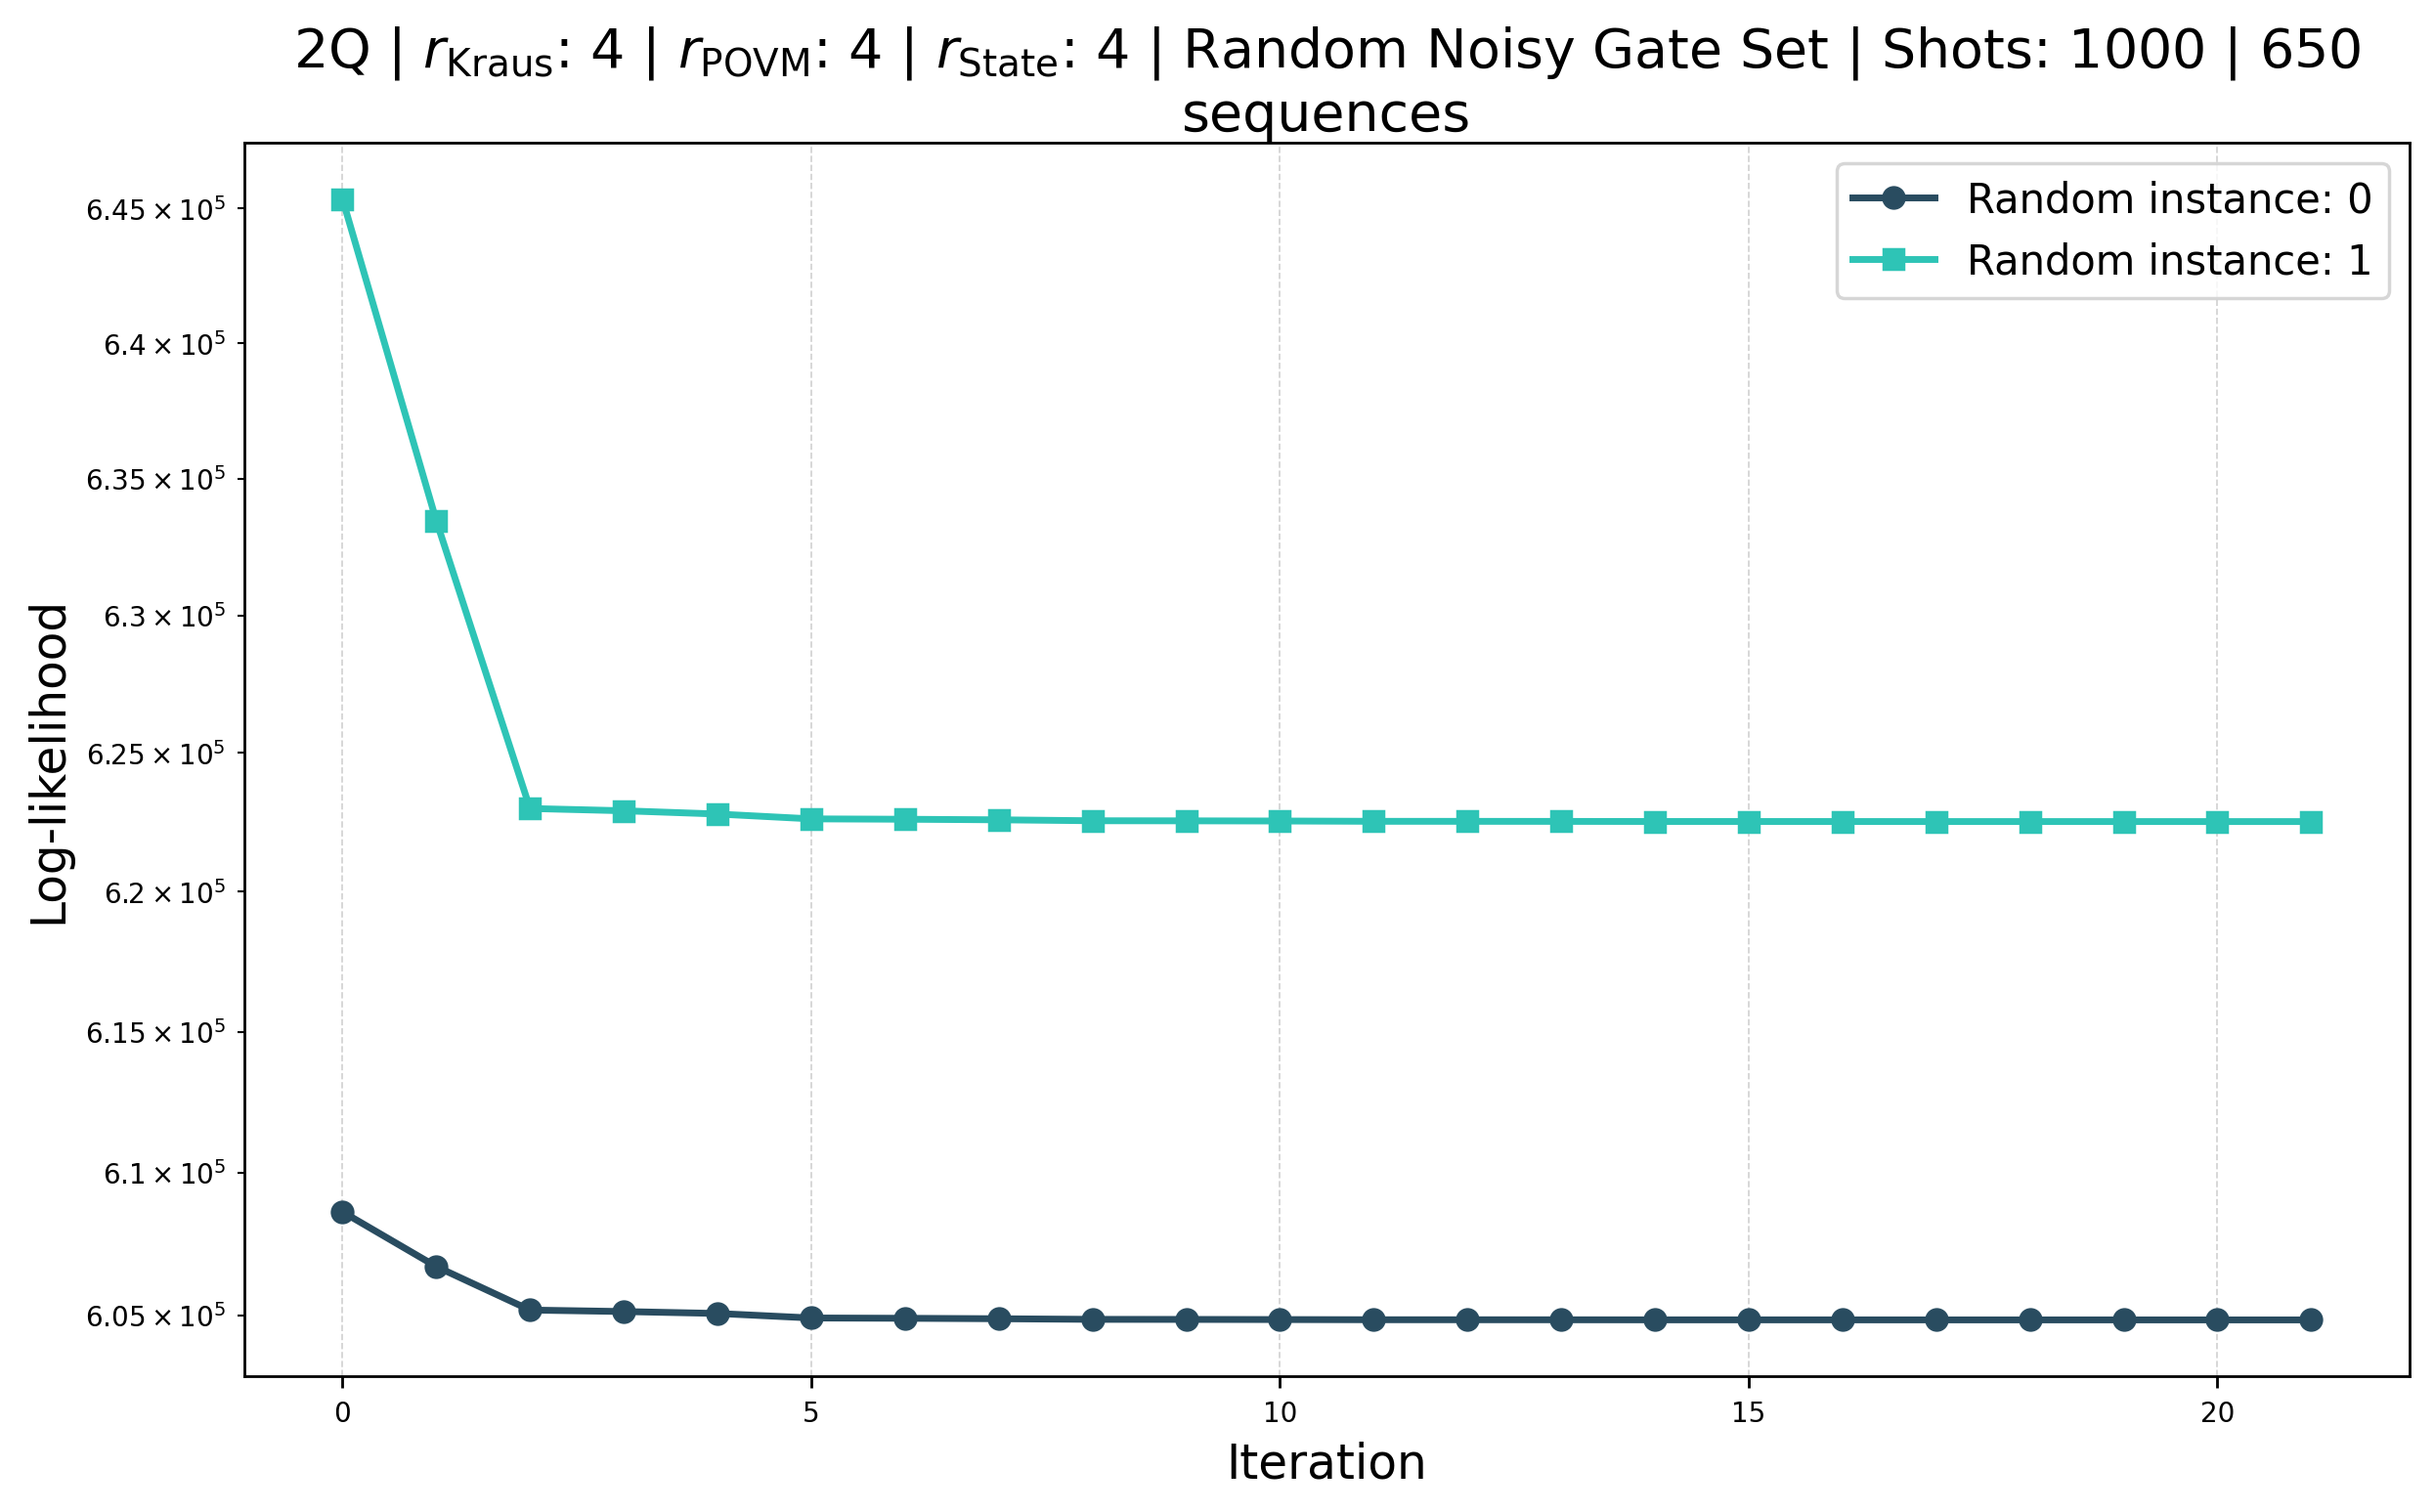

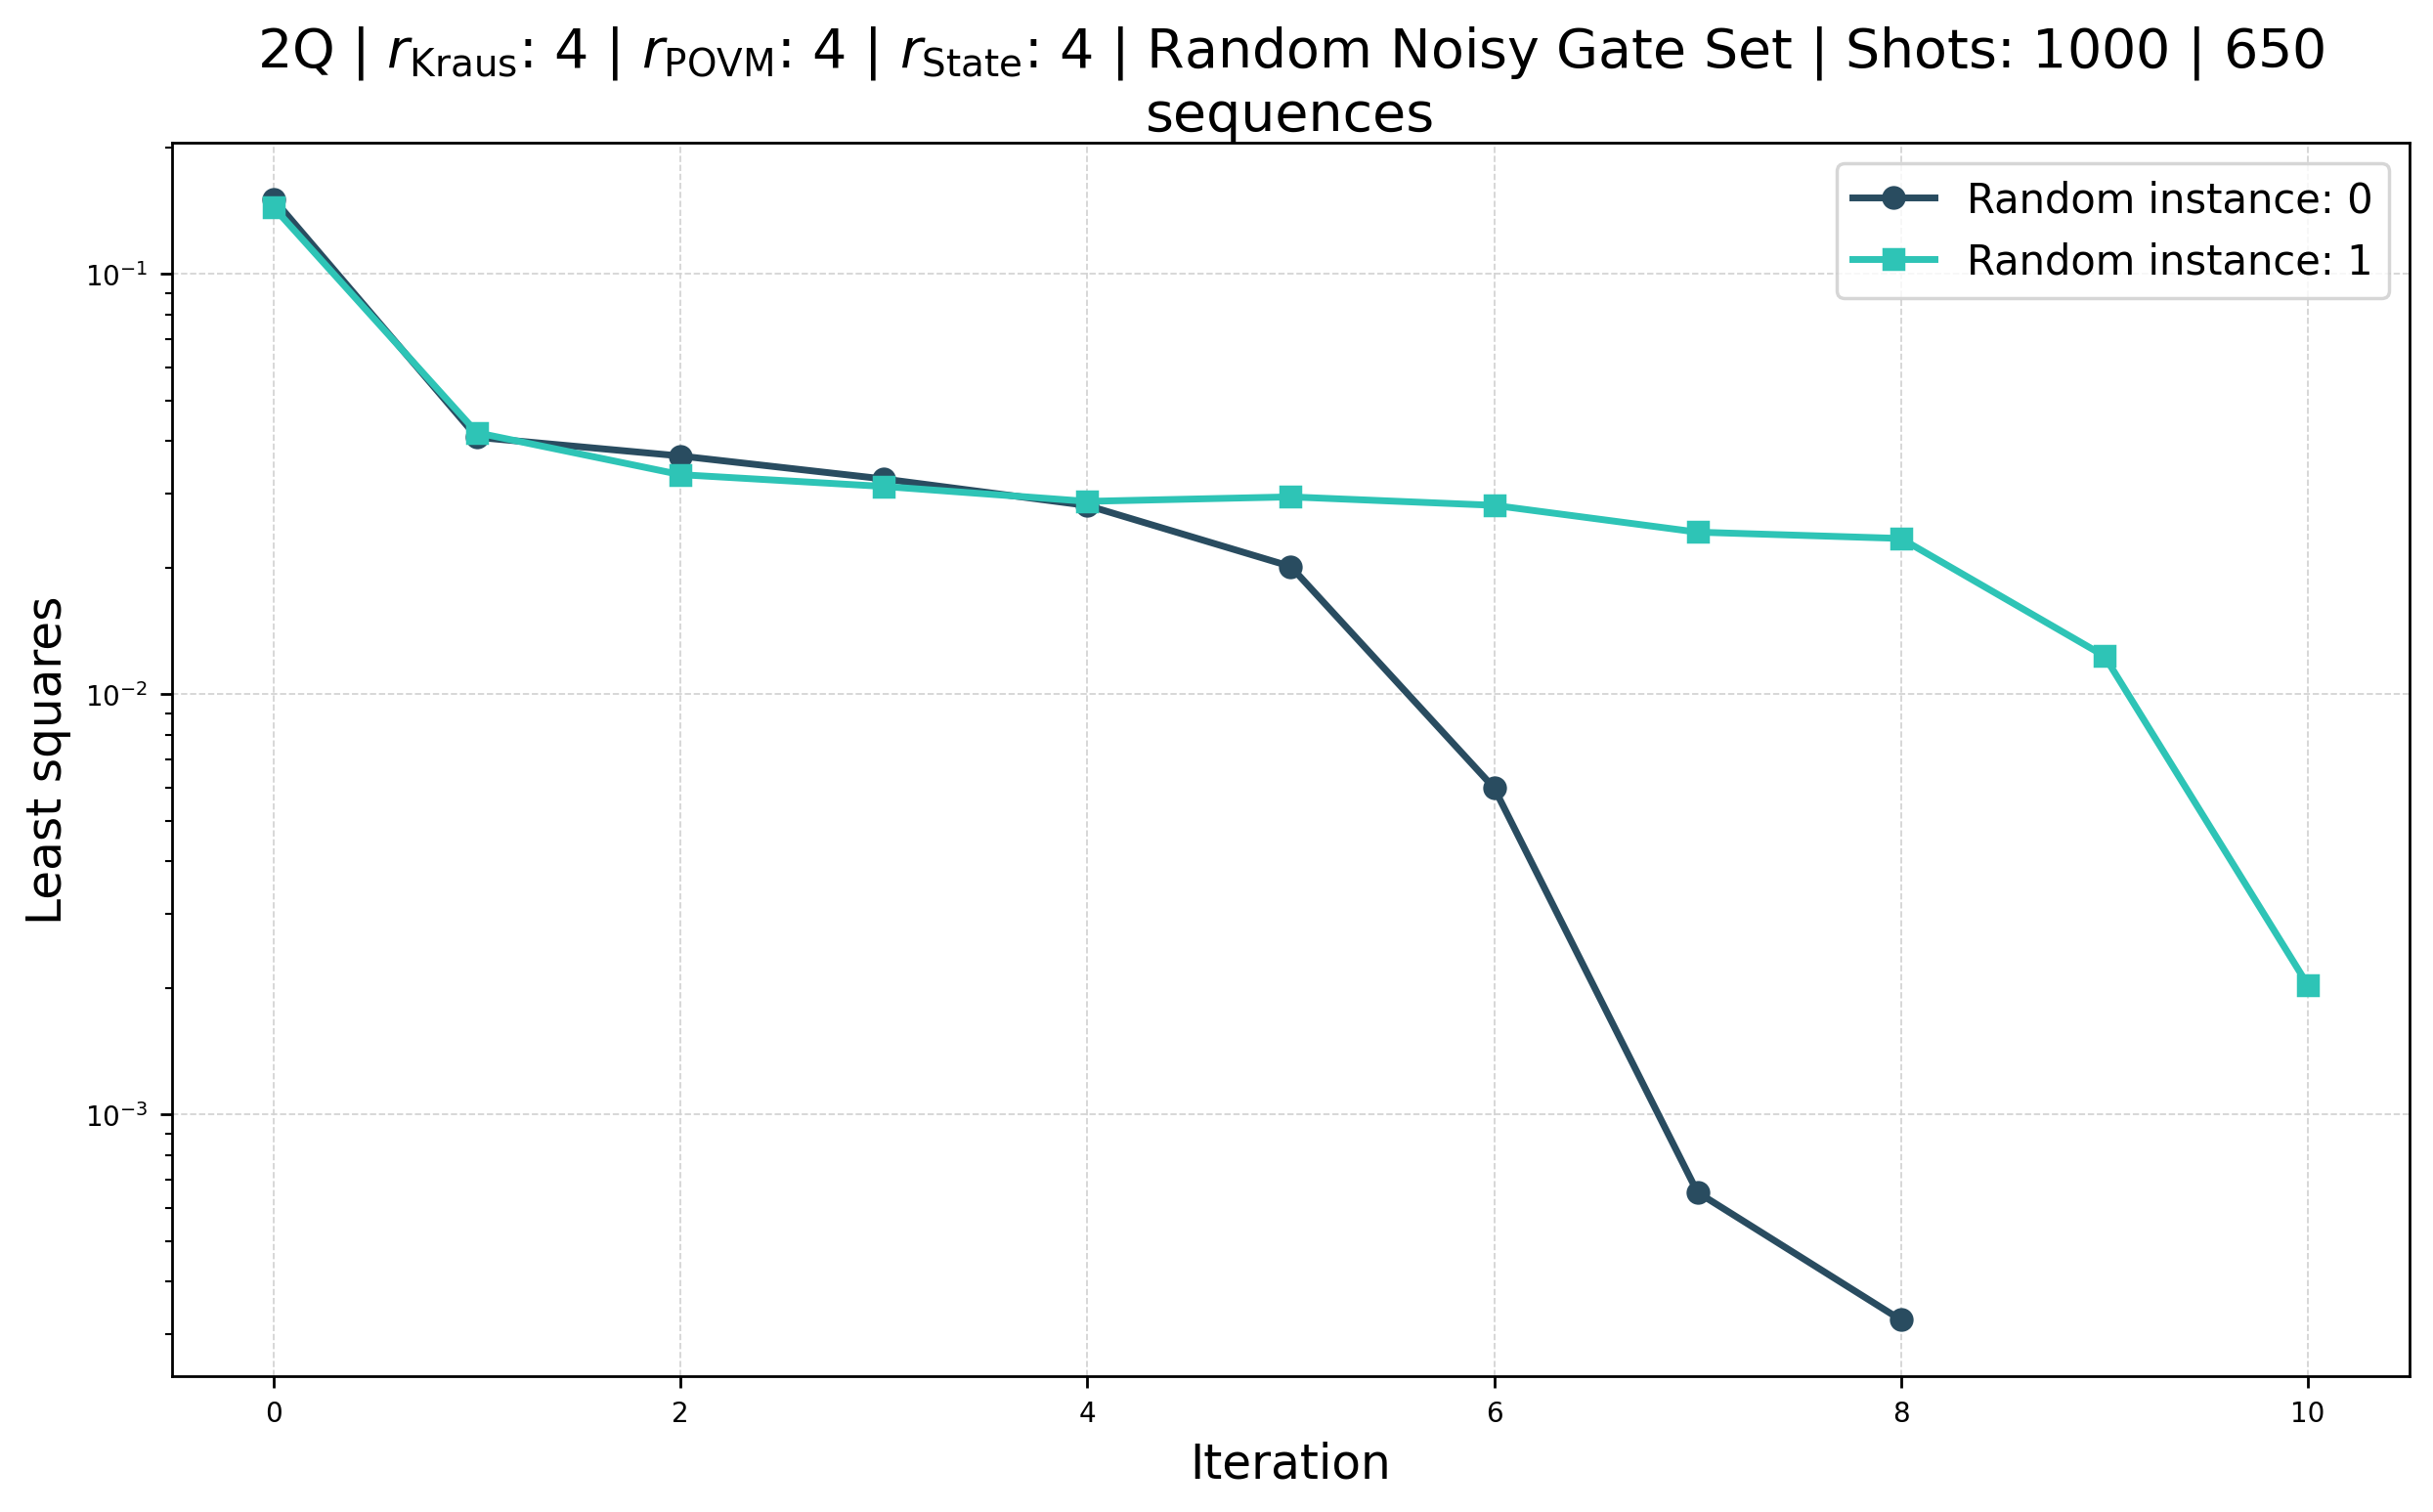

In [138]:
sequences_test = 650

final_results_test = get_all_realizations_for_key(final_results_1, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_1, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

# MVE

In [156]:
mve_results_0, wve_results_large_0 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_0,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_0

[{'100': {'mean': Array(0.36484922, dtype=float64),
   'std': Array(0.0049805, dtype=float64)},
  '150': {'mean': Array(0.07364065, dtype=float64),
   'std': Array(0.00435321, dtype=float64)}},
 {'100': {'mean': Array(0.0503904, dtype=float64),
   'std': Array(0.00527011, dtype=float64)},
  '150': {'mean': Array(0.01121048, dtype=float64),
   'std': Array(0.00026012, dtype=float64)}}]

In [157]:
mve_results_1, wve_results_large_1 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_1,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)

In [140]:
mve_results_1

[{'600': {'mean': Array(0.00534526, dtype=float64),
   'std': Array(5.9740795e-05, dtype=float64)},
  '650': {'mean': Array(0.00487994, dtype=float64),
   'std': Array(5.67801622e-05, dtype=float64)}},
 {'600': {'mean': Array(0.00448299, dtype=float64),
   'std': Array(0.00010177, dtype=float64)},
  '650': {'mean': Array(0.00471619, dtype=float64),
   'std': Array(7.60167755e-05, dtype=float64)}}]

In [148]:
mve_results_2

[{'500': {'mean': Array(0.00587815, dtype=float64),
   'std': Array(7.36294298e-05, dtype=float64)},
  '550': {'mean': Array(0.05954307, dtype=float64),
   'std': Array(0.00384927, dtype=float64)}},
 {'500': {'mean': Array(0.00580847, dtype=float64),
   'std': Array(0.00011778, dtype=float64)},
  '550': {'mean': Array(0.00509902, dtype=float64),
   'std': Array(7.87002132e-05, dtype=float64)}},
 {'500': {'mean': Array(0.00529004, dtype=float64),
   'std': Array(9.80921659e-05, dtype=float64)},
  '550': {'mean': Array(0.00552136, dtype=float64),
   'std': Array(0.00011025, dtype=float64)}},
 {'500': {'mean': Array(0.00589885, dtype=float64),
   'std': Array(0.0001483, dtype=float64)},
  '550': {'mean': Array(0.00565028, dtype=float64),
   'std': Array(9.82191153e-05, dtype=float64)}},
 {'500': {'mean': Array(0.00631851, dtype=float64),
   'std': Array(0.00011441, dtype=float64)},
  '550': {'mean': Array(0.00578916, dtype=float64),
   'std': Array(8.39945201e-05, dtype=float64)}}]

In [133]:
mve_results_3

[{'700': {'mean': Array(0.00545152, dtype=float64),
   'std': Array(8.23905083e-05, dtype=float64)},
  '750': {'mean': Array(0.00497923, dtype=float64),
   'std': Array(8.77735192e-05, dtype=float64)}},
 {'700': {'mean': Array(0.00501733, dtype=float64),
   'std': Array(8.00254466e-05, dtype=float64)},
  '750': {'mean': Array(0.00516564, dtype=float64),
   'std': Array(0.00012592, dtype=float64)}}]

In [115]:
mve_results_4

[{'1000': {'mean': Array(0.00489905, dtype=float64),
   'std': Array(0.00010383, dtype=float64)}},
 {'1000': {'mean': Array(0.00399239, dtype=float64),
   'std': Array(4.0105814e-05, dtype=float64)}}]

In [44]:
mve_results_100_150, wve_results_100_150 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_100_150,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_100_150

[{'100': {'mean': Array(0.38269418, dtype=float64),
   'std': Array(0.00475477, dtype=float64)},
  '150': {'mean': Array(0.01201783, dtype=float64),
   'std': Array(0.00019203, dtype=float64)}},
 {'100': {'mean': Array(0.34593324, dtype=float64),
   'std': Array(0.00654775, dtype=float64)},
  '150': {'mean': Array(0.01298343, dtype=float64),
   'std': Array(0.00031918, dtype=float64)}},
 {'100': {'mean': Array(0.33630528, dtype=float64),
   'std': Array(0.00666516, dtype=float64)},
  '150': {'mean': Array(0.33106513, dtype=float64),
   'std': Array(0.00596, dtype=float64)}},
 {'100': {'mean': Array(0.38395682, dtype=float64),
   'std': Array(0.0061578, dtype=float64)},
  '150': {'mean': Array(0.01272324, dtype=float64),
   'std': Array(0.00031876, dtype=float64)}},
 {'100': {'mean': Array(0.38927578, dtype=float64),
   'std': Array(0.00509403, dtype=float64)},
  '150': {'mean': Array(0.01121541, dtype=float64),
   'std': Array(0.0003051, dtype=float64)}}]

In [52]:
mve_results_200_250, wve_results_200_250 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_200_250,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_200_250

[{'200': {'mean': Array(0.00981976, dtype=float64),
   'std': Array(0.00014684, dtype=float64)},
  '250': {'mean': Array(0.00950467, dtype=float64),
   'std': Array(0.00014163, dtype=float64)}},
 {'200': {'mean': Array(0.01014485, dtype=float64),
   'std': Array(0.00018474, dtype=float64)},
  '250': {'mean': Array(0.00732835, dtype=float64),
   'std': Array(0.00014803, dtype=float64)}},
 {'200': {'mean': Array(0.01020053, dtype=float64),
   'std': Array(0.00018814, dtype=float64)},
  '250': {'mean': Array(0.00914425, dtype=float64),
   'std': Array(0.00013849, dtype=float64)}},
 {'200': {'mean': Array(0.00965754, dtype=float64),
   'std': Array(0.00016538, dtype=float64)},
  '250': {'mean': Array(0.00870566, dtype=float64),
   'std': Array(0.0001597, dtype=float64)}},
 {'200': {'mean': Array(0.00947286, dtype=float64),
   'std': Array(0.00012785, dtype=float64)},
  '250': {'mean': Array(0.00910932, dtype=float64),
   'std': Array(0.00017473, dtype=float64)}}]

In [37]:
mve_results_300_350, wve_results_300_350 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_300_350,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_300_350

[{'300': {'mean': Array(0.0078458, dtype=float64),
   'std': Array(0.00016915, dtype=float64)},
  '350': {'mean': Array(0.00710101, dtype=float64),
   'std': Array(0.00014164, dtype=float64)}},
 {'300': {'mean': Array(0.00760608, dtype=float64),
   'std': Array(0.00018821, dtype=float64)},
  '350': {'mean': Array(0.00793763, dtype=float64),
   'std': Array(0.00014346, dtype=float64)}},
 {'300': {'mean': Array(0.00891622, dtype=float64),
   'std': Array(0.0001667, dtype=float64)},
  '350': {'mean': Array(0.00709861, dtype=float64),
   'std': Array(0.00016086, dtype=float64)}},
 {'300': {'mean': Array(0.00821346, dtype=float64),
   'std': Array(0.00016027, dtype=float64)},
  '350': {'mean': Array(0.00682745, dtype=float64),
   'std': Array(0.00012091, dtype=float64)}},
 {'300': {'mean': Array(0.00731207, dtype=float64),
   'std': Array(0.00016526, dtype=float64)},
  '350': {'mean': Array(0.00668898, dtype=float64),
   'std': Array(0.00012552, dtype=float64)}}]

In [34]:
mve_results_400_450, wve_results_400_450 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_400_450,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_400_450

[{'400': {'mean': Array(0.00771743, dtype=float64),
   'std': Array(0.00012328, dtype=float64)},
  '450': {'mean': Array(0.00597715, dtype=float64),
   'std': Array(7.78388782e-05, dtype=float64)}},
 {'400': {'mean': Array(0.00655868, dtype=float64),
   'std': Array(0.00012036, dtype=float64)},
  '450': {'mean': Array(0.00731872, dtype=float64),
   'std': Array(0.00014631, dtype=float64)}},
 {'400': {'mean': Array(0.00600395, dtype=float64),
   'std': Array(0.00012394, dtype=float64)},
  '450': {'mean': Array(0.00578141, dtype=float64),
   'std': Array(0.00011848, dtype=float64)}},
 {'400': {'mean': Array(0.00668011, dtype=float64),
   'std': Array(0.00010644, dtype=float64)},
  '450': {'mean': Array(0.00636988, dtype=float64),
   'std': Array(9.96029622e-05, dtype=float64)}},
 {'400': {'mean': Array(0.00692856, dtype=float64),
   'std': Array(0.00014489, dtype=float64)},
  '450': {'mean': Array(0.00587571, dtype=float64),
   'std': Array(0.00011663, dtype=float64)}}]

In [31]:
mve_results_500_550, wve_results_500_550 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_500_550,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_500_550

[{'500': {'mean': Array(0.0062373, dtype=float64),
   'std': Array(0.00012704, dtype=float64)},
  '550': {'mean': Array(0.00615011, dtype=float64),
   'std': Array(0.00013897, dtype=float64)}},
 {'500': {'mean': Array(0.00665876, dtype=float64),
   'std': Array(0.0001225, dtype=float64)},
  '550': {'mean': Array(0.0055573, dtype=float64),
   'std': Array(0.00014722, dtype=float64)}},
 {'500': {'mean': Array(0.00628725, dtype=float64),
   'std': Array(0.00012111, dtype=float64)},
  '550': {'mean': Array(0.00599068, dtype=float64),
   'std': Array(0.00012491, dtype=float64)}},
 {'500': {'mean': Array(0.00656368, dtype=float64),
   'std': Array(0.00016243, dtype=float64)},
  '550': {'mean': Array(0.00493488, dtype=float64),
   'std': Array(8.99216277e-05, dtype=float64)}},
 {'500': {'mean': Array(0.00648815, dtype=float64),
   'std': Array(0.00012792, dtype=float64)},
  '550': {'mean': Array(0.00494724, dtype=float64),
   'std': Array(9.38775229e-05, dtype=float64)}}]

In [28]:
mve_results_600_650, wve_results_600_650 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_600_650,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_600_650

[{'600': {'mean': Array(0.00559044, dtype=float64),
   'std': Array(0.00013863, dtype=float64)},
  '650': {'mean': Array(0.00519687, dtype=float64),
   'std': Array(6.38433531e-05, dtype=float64)}},
 {'600': {'mean': Array(0.00485328, dtype=float64),
   'std': Array(6.29998759e-05, dtype=float64)},
  '650': {'mean': Array(0.00463391, dtype=float64),
   'std': Array(7.74930344e-05, dtype=float64)}},
 {'600': {'mean': Array(0.00495058, dtype=float64),
   'std': Array(9.47467519e-05, dtype=float64)},
  '650': {'mean': Array(0.00600266, dtype=float64),
   'std': Array(8.0346463e-05, dtype=float64)}},
 {'600': {'mean': Array(0.00498404, dtype=float64),
   'std': Array(0.00012295, dtype=float64)},
  '650': {'mean': Array(0.004696, dtype=float64),
   'std': Array(0.0001393, dtype=float64)}},
 {'600': {'mean': Array(0.00570369, dtype=float64),
   'std': Array(0.00011288, dtype=float64)},
  '650': {'mean': Array(0.00536021, dtype=float64),
   'std': Array(0.00010389, dtype=float64)}}]

In [20]:
mve_results_700, wve_results_large_700 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_700,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_700

[{'700': {'mean': Array(0.06879002, dtype=float64),
   'std': Array(0.00455871, dtype=float64)}},
 {'700': {'mean': Array(0.00490968, dtype=float64),
   'std': Array(0.00010067, dtype=float64)}},
 {'700': {'mean': Array(0.0048539, dtype=float64),
   'std': Array(5.33898347e-05, dtype=float64)}},
 {'700': {'mean': Array(0.0047349, dtype=float64),
   'std': Array(9.99353173e-05, dtype=float64)}},
 {'700': {'mean': Array(0.00542322, dtype=float64),
   'std': Array(0.00010596, dtype=float64)}}]

In [53]:
mve_combined = combine_error_results(mve_results_100_150, mve_results_200_250, mve_results_300_350, mve_results_400_450, mve_results_500_550, mve_results_600_650, mve_results_700)
mean_mve_results_combined = compute_avg_and_std_along_keys(list_of_errors=mve_combined)

In [164]:
result_1000_seq = mve_results_test["1000"]
result_1000_seq_dict = {key: result_1000_seq for key in mean_mve_results_combined}
result_1000_seq

{'mean': Array(0.00376728, dtype=float64),
 'std': Array(4.57926501e-05, dtype=float64)}

In [54]:
mean_mve_results_combined

{'100': {'mean': Array(0.36763306, dtype=float64),
  'std': Array(0.02197281, dtype=float64)},
 '150': {'mean': Array(0.07600101, dtype=float64),
  'std': Array(0.12753354, dtype=float64)},
 '200': {'mean': Array(0.00985911, dtype=float64),
  'std': Array(0.00027914, dtype=float64)},
 '250': {'mean': Array(0.00875845, dtype=float64),
  'std': Array(0.00075852, dtype=float64)},
 '300': {'mean': Array(0.00797873, dtype=float64),
  'std': Array(0.00055407, dtype=float64)},
 '350': {'mean': Array(0.00713074, dtype=float64),
  'std': Array(0.00043362, dtype=float64)},
 '400': {'mean': Array(0.00677775, dtype=float64),
  'std': Array(0.00055893, dtype=float64)},
 '450': {'mean': Array(0.00626458, dtype=float64),
  'std': Array(0.00056384, dtype=float64)},
 '500': {'mean': Array(0.00644703, dtype=float64),
  'std': Array(0.00016102, dtype=float64)},
 '550': {'mean': Array(0.00551604, dtype=float64),
  'std': Array(0.000508, dtype=float64)},
 '600': {'mean': Array(0.00521641, dtype=float64),
 

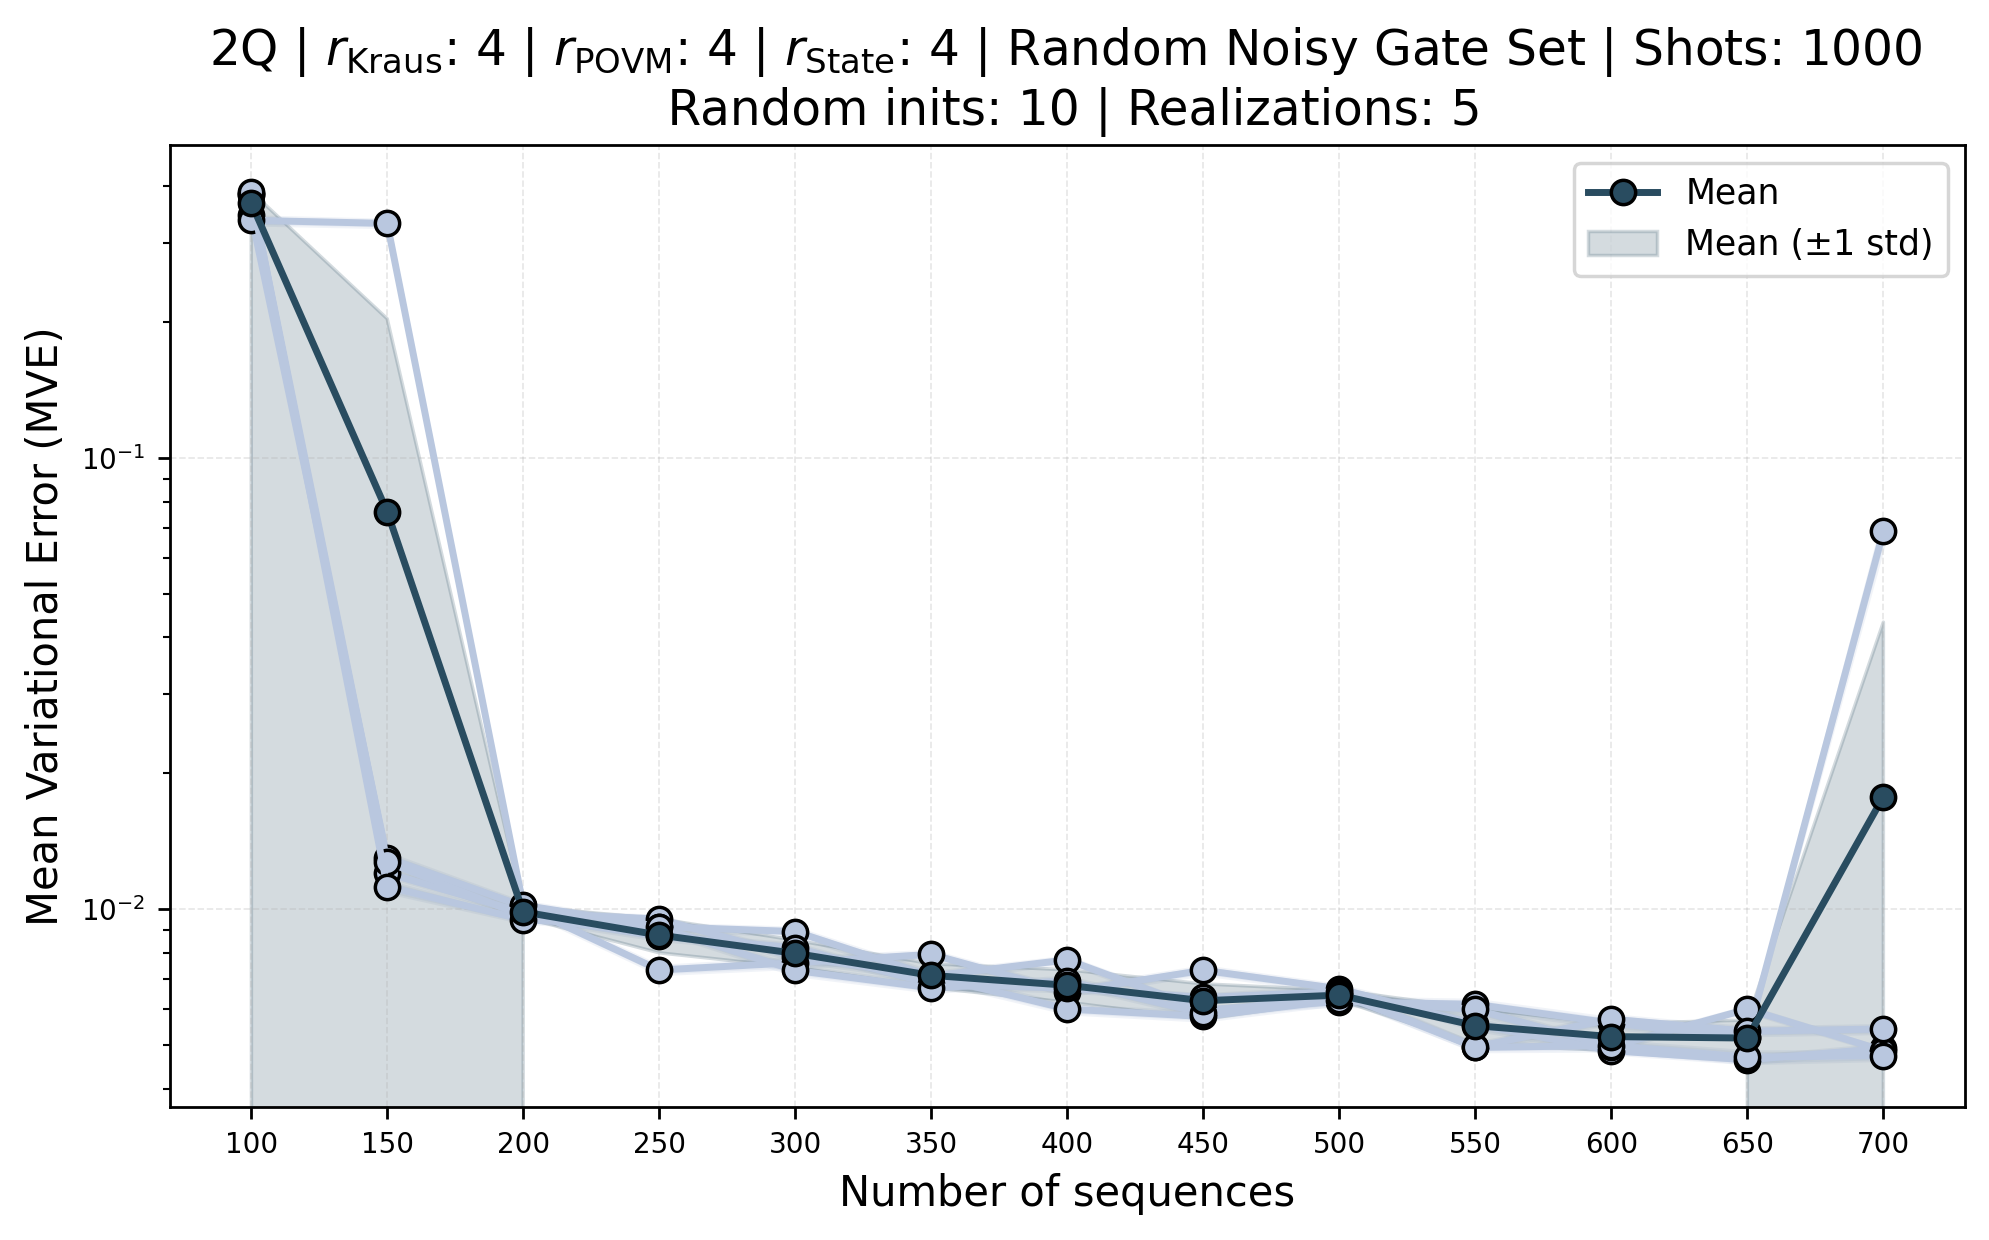

In [55]:
fig_all_mve = plot_many_mean_std_vs_x(
    data=mve_combined,
    title=title_mve,
    ylabel=f"Mean Variational Error (MVE)",
    use_log_scale="y",
    main_curve=mean_mve_results_combined,
    main_curve_label="Mean",
    # main_curve=result_1000_seq_dict,
    # main_curve_label="1000 Sequences (target init)",
    show=False,
)

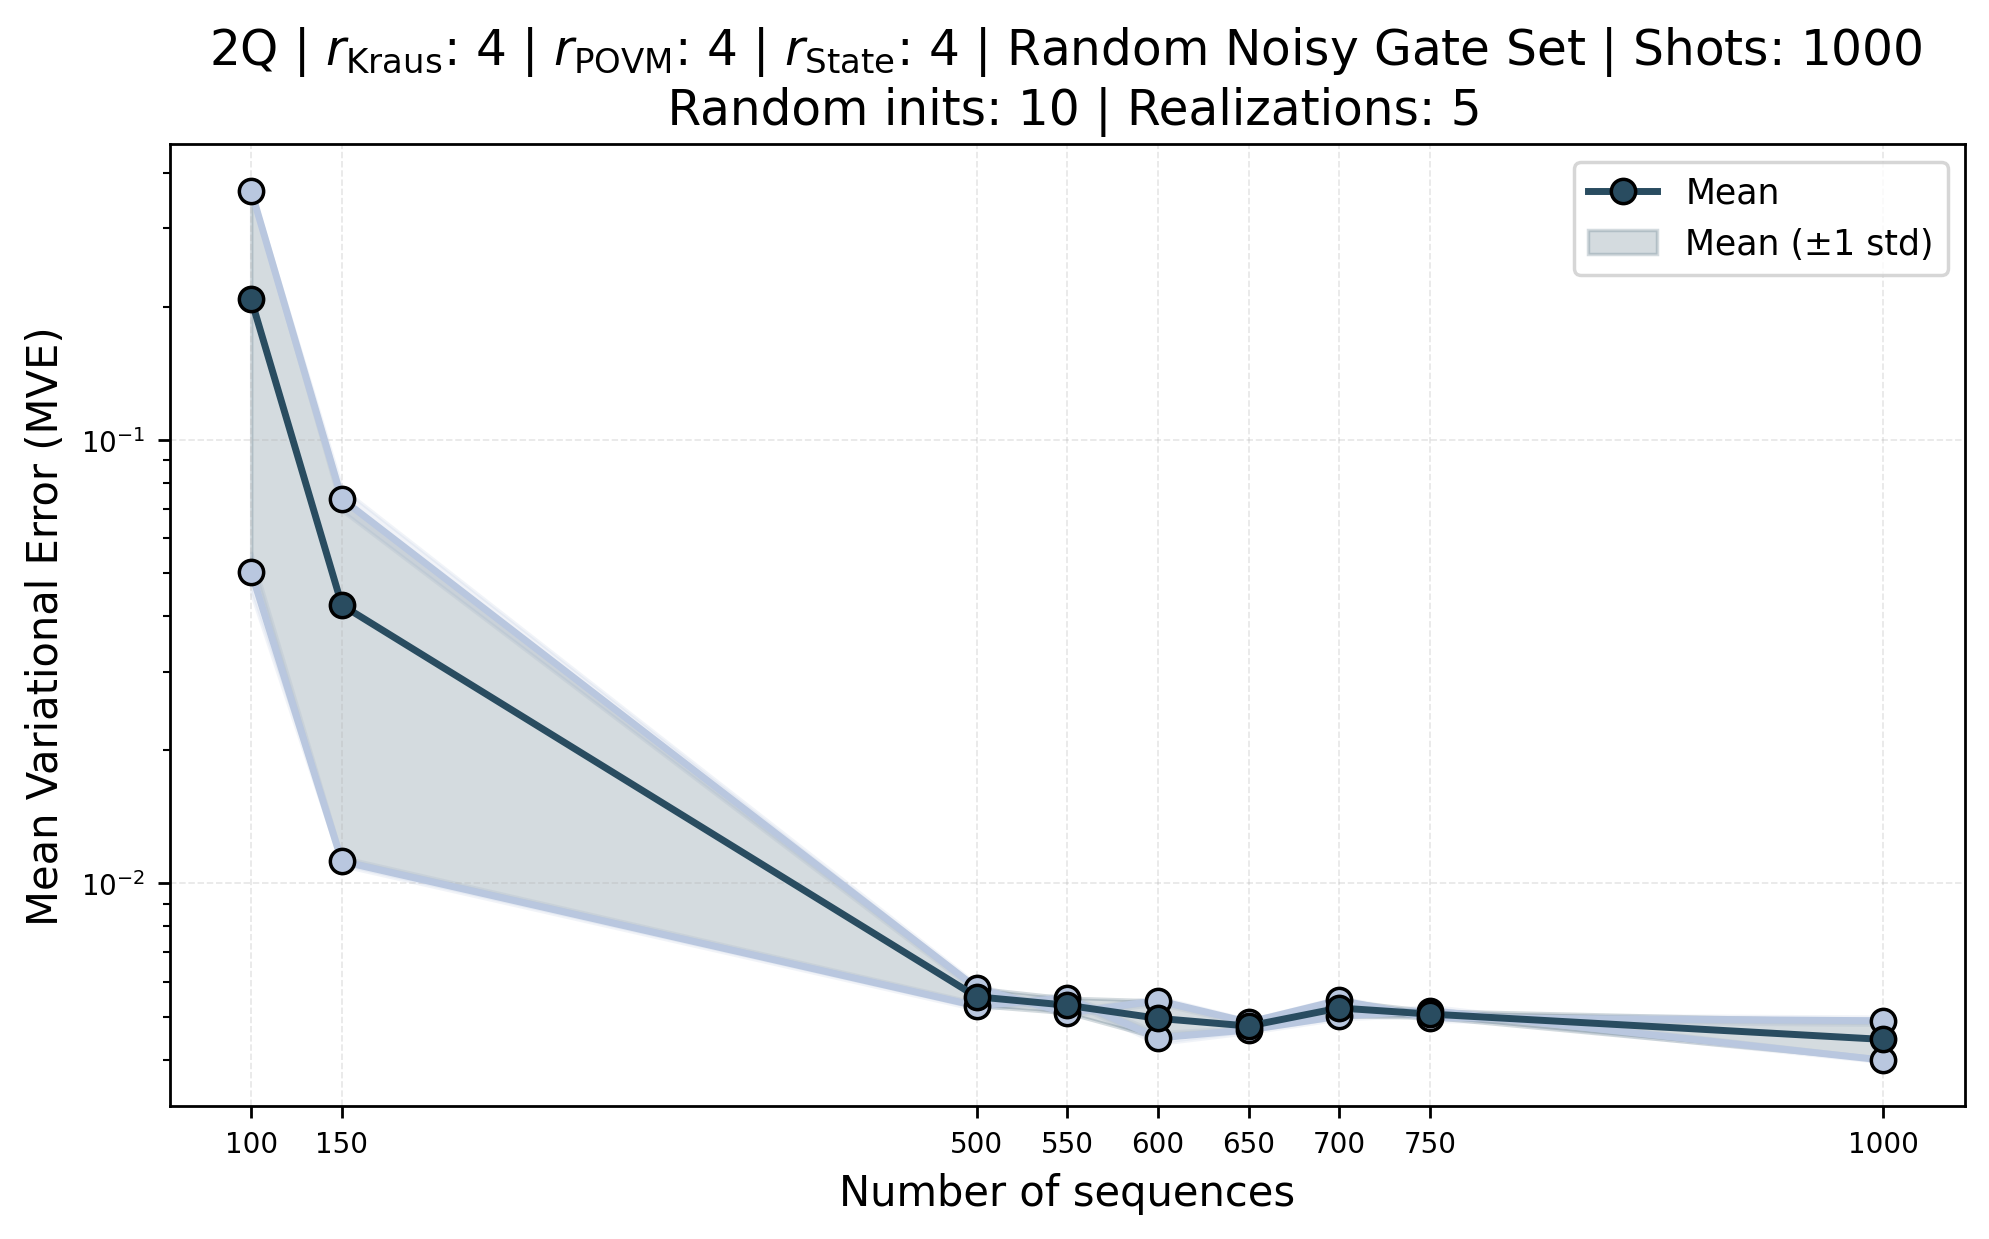

In [173]:
fig_all_mve = plot_many_mean_std_vs_x(
    data=mve_combined,
    title=title_mve,
    ylabel=f"Mean Variational Error (MVE)",
    use_log_scale="y",
    main_curve=mean_mve_results_combined,
    main_curve_label="Mean",
    # main_curve=result_1000_seq_dict,
    # main_curve_label="1000 Sequences (target init)",
    show=False,
)

In [175]:
min_expected, max_expected

(623, 815)

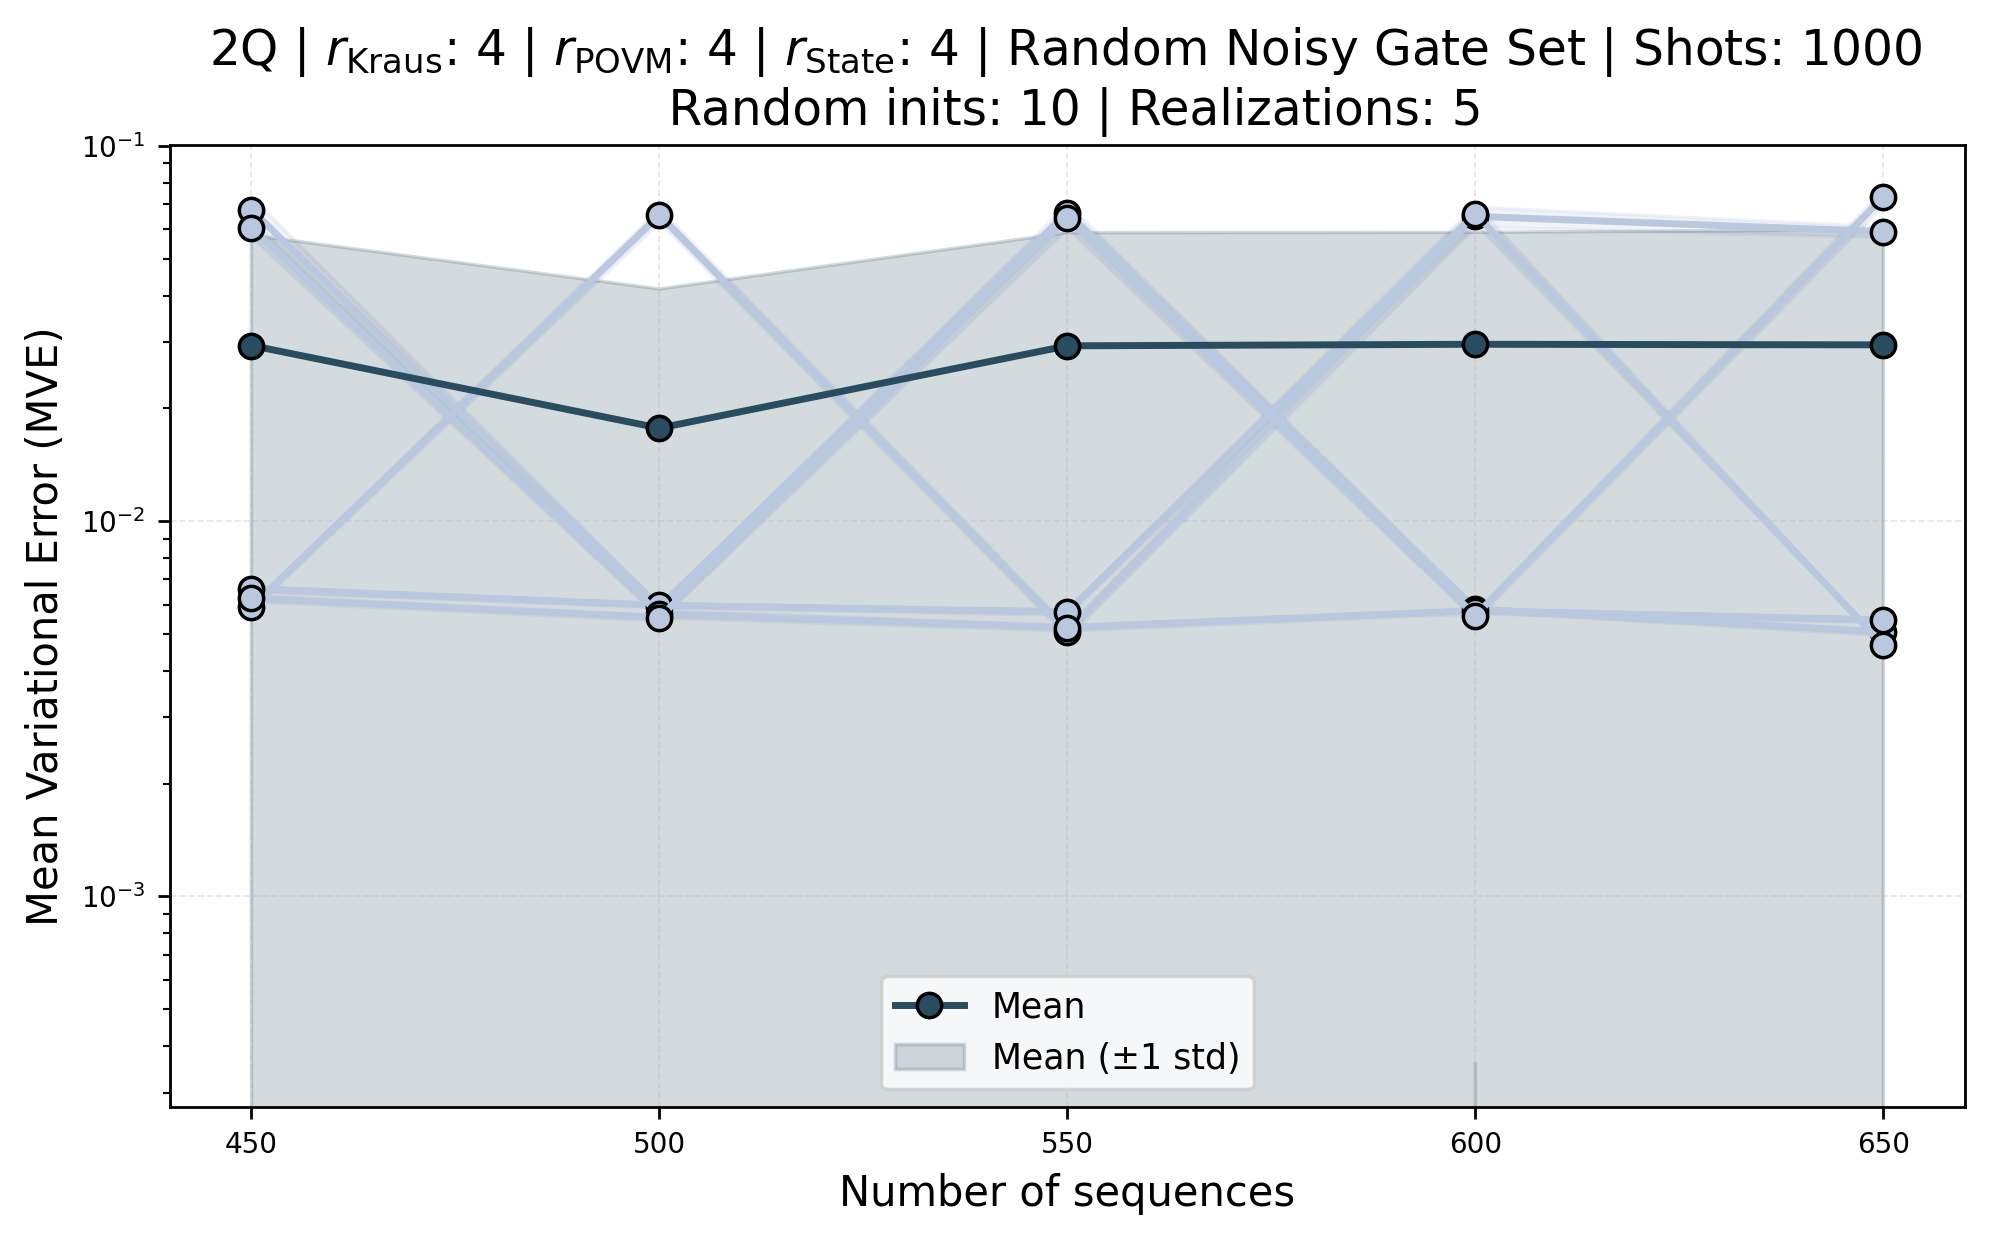

In [35]:
fig_all_mve_ammended = plot_many_mean_std_vs_x(
    data=mve_combined,
    title=title_mve,
    ylabel=f"Mean Variational Error (MVE)",
    use_log_scale="y",
    main_curve=mean_mve_results_combined,
    main_curve_label="Mean",
    show=False,
)